# UMD Cyber Events Database - United States

The purpose of this notebook is to examine documented cyber incidents involving the United States as a victim or target, establish a transparent inclusion rule, and assess the available evidence for subsequent sectoral, temporal, and statistical analyses.

Each row represents one documented cyber event in which an unauthorized action or series of actions produced a discernible effect on a target.

**Source:** [*UMD Cyber Events Database*](https://gotech.umd.edu/cyber-events-database)  
**Dataset used:** *`Cyber Events Database - 2014-August2026.xlsx`*  
**Reference:** *`docs/codebooks/Cyber Events Database Codebook_March 2026.pdf`*


## Table of Contents

1. [Data Source and Initial Inspection](#1-data-source-and-scope)
   - [Data Loading](#1-data-loading-and-initial-inspection)
   - [Identifying US-Related Records](#12-identifying-us-related-records)
   - [US Subset Overview](#13-us-subset-overview)
   - [Data Completeness](#14-data-completeness)
   - [Missing and Unspecified Values](#15-missing-and-unspecified-value-categories)

2. [Duplicate Record Assessment](#2-duplicate-record-assessment)
   - [Exact Duplicate Candidates](#22-examination-of-exact-duplicate-candidates)
   - [Deduplication](#23-deduplication-of-identical-records)
   - [Additional Duplicate Detection](#24-additional-duplicate-candidate-detection)
   - [Detection Criteria](#25-comparison-of-duplicate-detection-criteria)
   - [Conservative Deduplication](#26-conservative-deduplication)

3. [Temporal Coverage and Incident Trends](#3-temporal-coverage-and-incident-trends)
   - [Annual Incident Distribution](#31-annual-incident-distribution)
   - [Monthly and Seasonal Patterns](#32-monthly-and-seasonal-patterns)

4. [Geographical Distribution](#4-geographical-distribution)
   - [Incidents by State](#41-incidents-by-state)
   - [State-Level Coverage by Year](#42-state-level-coverage-by-year)
   - [Top Three States by Year](#421-top-three-states-by-year)
   - [State-Level Case Studies](#44-state-level-case-studies)

5. [Incident Types and Subtypes](#5-incident-types-and-subtypes)
   - [Incident Types](#51-distribution-of-incident-types)
   - [Incident Subtypes](#52-distribution-of-incident-subtypes)
   - [Type–Subtype Relationships](#53-relationships-between-incident-types-and-subtypes)
   - [Changes Over Time](#54-changes-in-incident-types-and-subtypes-over-time)

6. [Targeted Economic Sectors](#6-targeted-economic-sectors)
   - [Incident Types by Sector](#61-incident-types-across-economic-sectors)
   - [Incident Subtypes by Sector](#641-incident-subtypes-across-economic-sectors)
   - [Ransomware by Sector](#64-ransomware-related-incidents-by-economic-sector)
   - [Geographical Distribution of Ransomware](#65-geographical-distribution-of-ransomware-related-incidents)

7. [Targeted Organizations](#7-targeted-organizations)
   - [Organization Name Consolidation](#71-organization-name-consolidation)
   - [Incident Concentration](#72-organization-level-incident-concentration)
   - [Repeated Incidents](#73-repeated-incidents-over-time)
   - [Organizations by Sector and State](#74-organizations-by-sector-and-state)
   - [Organizational Incident Histories](#75-organizational-incident-histories)

8. [Threat Actors and Motivations](#8-threat-actors-and-motivations)
   - [Actor Types](#81-distribution-of-actor-types)
   - [Identified Threat Actors](#82-identified-threat-actors)
   - [Geographical Attribution](#83-geographical-attribution-of-threat-actors)
   - [Threat Actor Motivations](#84-threat-actor-motivations)
   - [Actors, Sectors, and Incident Types](#85-threat-actors-target-sectors-and-incident-types)

9. [Figure Export](#9-figure-export)
   - [Named Figure Objects](#91-export-figures-already-stored-as-named-figure-objects)
   - [Organization Figures](#92-recreate-and-export-organization-focused-figures)
   - [Actor and Attribution Figures](#93-recreate-and-export-actor-and-attribution-focused-figures)
   - [Export Summary](#94-export-summary)

---


## 1. Data source and scope

Verify the source workbook, schema, provenance, reporting period, and geographical field definitions before filtering.


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import sys

sys.path.insert(0, str(Path("../src").resolve()))

import organization
import importlib

importlib.reload(organization)
from organization import consolidate_organizations

In [2]:
# Configure figure export directories
from pathlib import Path

FIGURES_DIR = Path("../figures/umd_usa").resolve()
STATIC_DIR = FIGURES_DIR / "static"
INTERACTIVE_DIR = FIGURES_DIR / "interactive"

STATIC_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_DIR.mkdir(parents=True, exist_ok=True)

# Shared export settings
FIGURE_DPI = 300

print(f"Static figures: {STATIC_DIR}")
print(f"Interactive figures: {INTERACTIVE_DIR}")


Static figures: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static
Interactive figures: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive


In [3]:
# Load consolidated UMD data without deduplication
DATA_PATH = Path(
    "../data/processed/umd_overview/umd_consolidated_all_records.csv"
)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["event_date", "reported_date"],
    low_memory=False
)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

Rows: 17,480
Columns: 46


## 1. Data loading and initial inspection

We load the original UMD dataset and examine its basic characteristics, focusing on records involving the United States before performing any data cleaning or transformation.

In [4]:
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Non-null values": df.notna().sum().values,
    "Missing (%)": (df.isna().mean() * 100).round(2).values,
})

display(column_overview)

,Column,Data type,Non-null values,Missing (%)
0,slug,str,17480,0.00
1,original_method,int64,17480,0.00
2,event_date,datetime64[us],17480,0.00
3,reported_date,datetime64[us],2929,83.24
4,year,int64,17480,0.00
5,month,int64,17480,0.00
6,actor,str,17480,0.00
7,actor_type,str,17480,0.00
8,organization,str,17480,0.00
9,industry_code,int64,17480,0.00


### 1.2 Identifying US-related records

We examine how the United States is represented in the geographic variables before defining the criteria for selecting relevant incidents.

In [5]:
geo_columns = [
    "country",
    "country_iso3",
    "actor_country",
    "actor_country_iso3",
    "state",
    "county"
]

us_geo_overview = pd.DataFrame({
    "Column": geo_columns,
    "Non-null values": [df[col].notna().sum() for col in geo_columns],
    "Unique values": [df[col].nunique(dropna=True) for col in geo_columns],
    "US matches": [
        df[col].astype("string").str.contains(
            r"\b(?:United States(?: of America)?|USA|US)\b",
            case=False,
            regex=True,
            na=False
        ).sum()
        for col in geo_columns
    ]
})

display(us_geo_overview)

,Column,Non-null values,Unique values,US matches
0,country,17480,175,8274
1,country_iso3,16828,170,8274
2,actor_country,17479,91,169
3,actor_country_iso3,17450,88,169
4,state,8306,58,0
5,county,8119,823,0


In [6]:
us_matches = df[
    df["country_iso3"].astype("string").str.contains(
        r"\bUSA\b", regex=True, na=False
    )
]

us_country_combinations = (
    us_matches
    .groupby(["country", "country_iso3"], dropna=False)
    .size()
    .reset_index(name="Records")
    .sort_values("Records", ascending=False)
)

display(us_country_combinations)

,country,country_iso3,Records
0,United States of America,USA,8274


In [7]:
# Select incidents involving the United States as the victim or target
usa = df.loc[df["country_iso3"].eq("USA")].copy()

print(f"US records: {len(usa):,}")
print(f"Share of all records: {len(usa) / len(df):.2%}")
print(f"Unique slugs: {usa['slug'].nunique():,}")

US records: 8,274
Share of all records: 47.33%
Unique slugs: 8,274


### 1.3 US subset overview

In [8]:
print(f"Earliest event: {usa['event_date'].min():%Y-%m-%d}")
print(f"Latest event:   {usa['event_date'].max():%Y-%m-%d}")
print(f"Years covered:  {usa['year'].nunique()}")
print(f"States recorded: {usa['state'].nunique(dropna=True)}")
print(f"Industries recorded: {usa['industry'].nunique(dropna=True)}")

Earliest event: 2014-01-01
Latest event:   2026-08-27
Years covered:  13
States recorded: 57
Industries recorded: 21


In [9]:
state_overview = (
    usa["state"]
    .value_counts(dropna=False)
    .rename_axis("State")
    .reset_index(name="Records")
)

state_overview["Share (%)"] = (
    state_overview["Records"] / len(usa) * 100
).round(2)

display(state_overview)

,State,Records,Share (%)
0,Undetermined,1443,17.44
1,California,930,11.24
2,Texas,552,6.67
3,New York,495,5.98
4,Florida,339,4.10
5,Illinois,281,3.40
6,Pennsylvania,238,2.88
7,Georgia,236,2.85
8,Massachusetts,234,2.83
9,Washington,199,2.41


### 1.4 Data completeness

The completeness of the US subset is assessed to identify missing values and determine which variables are sufficiently documented for further analysis.

In [10]:
usa_completeness = pd.DataFrame({
    "Column": usa.columns,
    "Missing": usa.isna().sum().values,
    "Missing (%)": (usa.isna().mean() * 100).round(2).values
}).sort_values("Missing (%)", ascending=False)

display(usa_completeness)

,Column,Missing,Missing (%)
15,duration,7944,96.01
14,magnitude,7939,95.95
16,scope,7937,95.93
18,org_data,7252,87.65
19,cust_data,7234,87.43
17,ip,7234,87.43
3,reported_date,7025,84.90
45,change_log,469,5.67
27,county,216,2.61
26,state,24,0.29


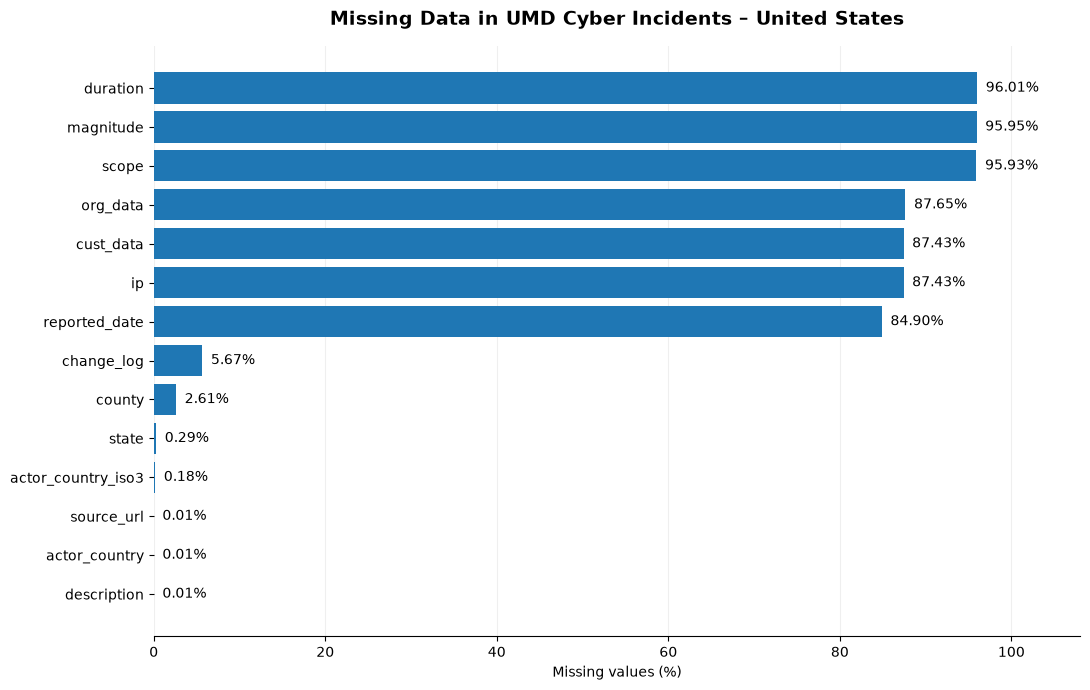

In [11]:
# Visualize missing values in the US subset
usa_missing_values = (
    usa_completeness
    .query("Missing > 0")
    .sort_values("Missing (%)")
)

fig_usa_missing_values, ax_usa_missing_values = plt.subplots(
    figsize=(11, 7)
)

bars = ax_usa_missing_values.barh(
    usa_missing_values["Column"],
    usa_missing_values["Missing (%)"]
)

for bar, pct in zip(bars, usa_missing_values["Missing (%)"]):
    ax_usa_missing_values.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%",
        va="center",
        fontsize=10
    )

ax_usa_missing_values.set_title(
    "Missing Data in UMD Cyber Incidents – United States",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax_usa_missing_values.set_xlabel("Missing values (%)")
ax_usa_missing_values.set_ylabel("")
ax_usa_missing_values.set_xlim(0, 108)

ax_usa_missing_values.spines[["top", "right", "left"]].set_visible(False)
ax_usa_missing_values.grid(axis="x", alpha=0.2)
ax_usa_missing_values.set_axisbelow(True)



fig_usa_missing_values.tight_layout()

plt.show()


### 1.5 Missing and unspecified value categories

Data quality is examined across all variables by distinguishing actual missing values from explicitly unspecified information. The resulting breakdown supports the identification of variables with limited analytical reliability.

In [12]:
# Examine missing and explicitly unspecified values across all variables
quality_types = [
    "NaN/NA",
    "NaT",
    "Undetermined",
    "Undisclosed",
    "Unknown"
]

usa_quality_summary = pd.DataFrame(
    0,
    index=usa.columns,
    columns=quality_types
)

for col in usa.columns:
    series = usa[col]
    missing_count = series.isna().sum()

    if pd.api.types.is_datetime64_any_dtype(series):
        usa_quality_summary.loc[col, "NaT"] = missing_count
    else:
        usa_quality_summary.loc[col, "NaN/NA"] = missing_count

    normalized = series.astype("string").str.strip().str.casefold()

    for label in ["Undetermined", "Undisclosed", "Unknown"]:
        usa_quality_summary.loc[col, label] = (
            normalized.eq(label.casefold()).sum()
        )

usa_quality_summary["Total"] = (
    usa_quality_summary[quality_types].sum(axis=1)
)

usa_quality_summary["Share (%)"] = (
    usa_quality_summary["Total"] / len(usa) * 100
)

usa_quality_summary = usa_quality_summary.sort_values(
    "Share (%)", ascending=False
)

display(usa_quality_summary.round(2))

,NaN/NA,NaT,Undetermined,Undisclosed,Unknown,Total,Share (%)
duration,7944,0,102,0,0,8046,97.24
scope,7937,0,33,0,0,7970,96.33
magnitude,7939,0,28,0,0,7967,96.29
org_data,7252,0,70,0,0,7322,88.49
cust_data,7234,0,45,0,0,7279,87.97
ip,7234,0,35,0,0,7269,87.85
actor_country_iso3,15,0,7132,0,0,7147,86.38
actor_country,1,0,7146,0,0,7147,86.38
reported_date,0,7025,0,0,0,7025,84.90
actor,0,0,5657,0,0,5657,68.37


In [13]:
# Assess missing and unspecified values across all US records
quality_categories = [
    "NaN/NA",
    "NaT",
    "Undetermined",
    "Undisclosed",
    "Unknown",
    "None reported",
    "Not reported"
]

In [14]:
usa_data_quality = pd.DataFrame(
    0,
    index=usa.columns,
    columns=quality_categories,
    dtype=int
)

for col in usa.columns:
    series = usa[col]

    # Distinguish missing dates from other missing values
    if pd.api.types.is_datetime64_any_dtype(series):
        usa_data_quality.loc[col, "NaT"] = series.isna().sum()
    else:
        usa_data_quality.loc[col, "NaN/NA"] = series.isna().sum()

    # Count explicitly specified labels separately
    normalized = series.astype("string").str.strip().str.casefold()

    for category in quality_categories[2:]:
        usa_data_quality.loc[col, category] = (
            normalized.eq(category.casefold()).sum()
        )

usa_data_quality["Total"] = (
    usa_data_quality[quality_categories].sum(axis=1)
)

usa_data_quality["Share (%)"] = (
    usa_data_quality["Total"] / len(usa) * 100
)

usa_data_quality = usa_data_quality.sort_values(
    "Share (%)", ascending=True
)

# Prepare category shares for the stacked bar chart
usa_quality_percentages = (
    usa_data_quality[quality_categories] / len(usa) * 100
)


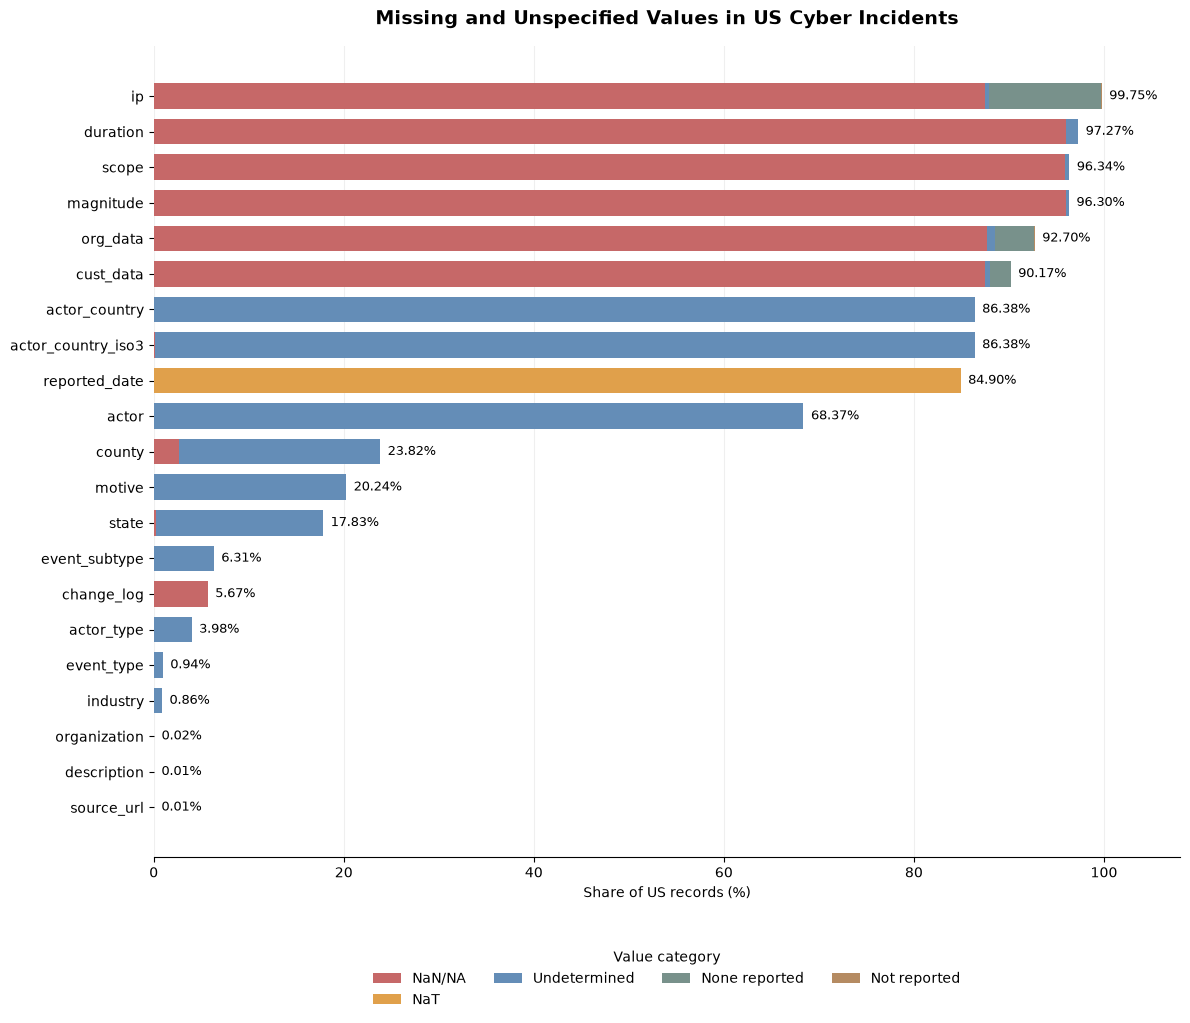


Variables without missing or unspecified values (25):
asean, au, aukus, country, country_iso3, csto, ecowas, eu, event_date, five_eyes, g20, g7, gulf_coop, industry_code, mercosur, month, nato, oas, oecd, opec, original_method, osce, shanghai_coop, slug, year


In [15]:
# Display only variables containing missing or unspecified values
quality_categories = [
    "NaN/NA",
    "NaT",
    "Undetermined",
    "Undisclosed",
    "Unknown",
    "None reported",
    "Not reported"
]

usa_quality_plot_data = (
    usa_data_quality
    .loc[usa_data_quality["Total"] > 0]
    .sort_values("Share (%)", ascending=True)
)

usa_quality_complete_columns = (
    usa_data_quality
    .index[usa_data_quality["Total"] == 0]
    .tolist()
)

usa_quality_plot_percentages = (
    usa_quality_plot_data[quality_categories] / len(usa) * 100
)

quality_colors = {
    "NaN/NA": "#C66868",
    "NaT": "#E0A04B",
    "Undetermined": "#648DB7",
    "Undisclosed": "#9273B5",
    "Unknown": "#7DA98B",
    "None reported": "#78918B",
    "Not reported": "#B58B62"
}

# Create a compact stacked bar chart
fig_usa_data_quality, ax_usa_data_quality = plt.subplots(
    figsize=(12, max(5, len(usa_quality_plot_data) * 0.42 + 1.5))
)

left = np.zeros(len(usa_quality_plot_percentages))

for category in quality_categories:
    values = usa_quality_plot_percentages[category].to_numpy()

    if values.sum() == 0:
        continue

    ax_usa_data_quality.barh(
        usa_quality_plot_percentages.index,
        values,
        left=left,
        label=category,
        color=quality_colors[category],
        height=0.72
    )

    left += values

# Annotate total percentages
for i, total in enumerate(usa_quality_plot_data["Share (%)"]):
    ax_usa_data_quality.text(
        total + 0.8,
        i,
        f"{total:.2f}%",
        va="center",
        fontsize=9
    )

ax_usa_data_quality.set_title(
    "Missing and Unspecified Values in US Cyber Incidents",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax_usa_data_quality.set_xlabel("Share of US records (%)")
ax_usa_data_quality.set_ylabel("")
ax_usa_data_quality.set_xlim(0, 108)

ax_usa_data_quality.grid(axis="x", alpha=0.2)
ax_usa_data_quality.set_axisbelow(True)

ax_usa_data_quality.spines[
    ["top", "right", "left"]
].set_visible(False)

ax_usa_data_quality.legend(
    title="Value category",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False
)

fig_usa_data_quality.tight_layout()
plt.show()

# List variables without any of the examined value categories
print(
    f"\nVariables without missing or unspecified values "
    f"({len(usa_quality_complete_columns)}):"
)
print(", ".join(sorted(usa_quality_complete_columns)))

The highest proportions of missing or unspecified values occur in incident impact measures, attacker attribution, and reporting dates. In contrast, incident types and targeted sectors are substantially better documented, making them more suitable for subsequent comparative analyses. Labels indicating that no information was reported are retained as distinct categories and should not automatically be interpreted as missing data.

## 2. Duplicate record assessment

Potential duplicate records are examined using progressively less restrictive criteria. Records are retained until the evidence is sufficient to determine whether they represent the same cyber event.

In [16]:
# Check exact duplicates under three identification criteria
duplicate_checks = {
    "Duplicate slug": ["slug"],
    "Identical across all columns": list(usa.columns),
    "Identical except slug": [
        col for col in usa.columns if col != "slug"
    ]
}

duplicate_results = []

for criterion, columns in duplicate_checks.items():
    duplicate_mask = usa.duplicated(
        subset=columns,
        keep=False
    )

    duplicate_records = usa.loc[duplicate_mask]

    duplicate_results.append({
        "Criterion": criterion,
        "Records involved": len(duplicate_records),
        "Duplicate groups": (
            duplicate_records.groupby(
                columns,
                dropna=False
            ).ngroups
            if not duplicate_records.empty else 0
        ),
        "Share (%)": round(
            len(duplicate_records) / len(usa) * 100,
            2
        )
    })

usa_exact_duplicate_summary = pd.DataFrame(
    duplicate_results
)

display(usa_exact_duplicate_summary)

,Criterion,Records involved,Duplicate groups,Share (%)
0,Duplicate slug,0,0,0.00
1,Identical across all columns,0,0,0.00
2,Identical except slug,122,61,1.47


### 2.2 Examination of exact duplicate candidates

Records identical across all attributes except `slug` are examined to determine whether they represent duplicate database entries. Candidate pairs are retained until their identifiers and event details have been reviewed.

In [17]:
# Identify records that differ only in their slug
duplicate_columns = [
    col for col in usa.columns if col != "slug"
]

usa_exact_duplicate_candidates = usa.loc[
    usa.duplicated(subset=duplicate_columns, keep=False)
].copy()

# Assign a shared group identifier to identical records
usa_exact_duplicate_candidates["duplicate_group"] = (
    usa_exact_duplicate_candidates
    .groupby(duplicate_columns, dropna=False)
    .ngroup() + 1
)

usa_exact_duplicate_candidates = (
    usa_exact_duplicate_candidates
    .sort_values(["duplicate_group", "slug"])
)

# Display identifying information for each candidate
duplicate_review_columns = [
    "duplicate_group",
    "slug",
    "event_date",
    "organization",
    "event_type",
    "event_subtype",
    "industry",
    "source_url"
]

display(
    usa_exact_duplicate_candidates[
        duplicate_review_columns
    ]
)

usa_exact_duplicate_candidates.to_csv(
    "../data/processed/umd_overview/usa_exact_duplicate_candidates.csv", index=False)

,duplicate_group,slug,event_date,organization,event_type,event_subtype,industry,source_url
4664,1,e61a3f8fd31e2ddf,2019-06-15,Missouri Southern State University (MSSU),Exploitive,Exploitation of End Hosts,Educational Services,https://www.bleepingcomputer.com/news/security...
4665,1,ee0abe050074aceb,2019-06-15,Missouri Southern State University (MSSU),Exploitive,Exploitation of End Hosts,Educational Services,https://www.bleepingcomputer.com/news/security...
4683,2,30d1b946aa1db251,2019-06-20,Riviera Beach,Disruptive,Data Attack,Public Administration,https://www.cbsnews.com/news/riviera-beach-flo...
4682,2,ee18aaeaf1c93f65,2019-06-20,Riviera Beach,Disruptive,Data Attack,Public Administration,https://www.cbsnews.com/news/riviera-beach-flo...
4706,3,70d75cc1390536a2,2019-06-28,Summa Health,Exploitive,Exploitation of End Hosts,Health Care and Social Assistance,https://www.databreaches.net/oh-more-than-500-...
...,...,...,...,...,...,...,...,...
9842,59,88e6eb5cfba1dc0d,2022-08-09,Cloudflare,Exploitive,Exploitation of End Hosts,Information,https://www.bleepingcomputer.com/news/security...
12353,60,592878ab3f1567c6,2023-07-21,University at Buffalo,Exploitive,Exploitation of Application Server,Educational Services,https://www.jdsupra.com/legalnews/multiple-col...
12354,60,ed1e3406ac78b57b,2023-07-21,University at Buffalo,Exploitive,Exploitation of Application Server,Educational Services,https://www.jdsupra.com/legalnews/multiple-col...
13295,61,62da8270d0ef3055,2023-11-28,Edge Realty Partners,Mixed,Exploitation of Application Server,Real Estate and Rental and Leasing,https://thecyberexpress.com/play-ransomware-at...


### 2.3 Deduplication of identical records

We identified 61 pairs of records that are identical across all 45 attributes except `slug`. Each pair is treated as a duplicate of the same documented incident. One record per pair is retained using a deterministic rule (the lexicographically smallest `slug`), while both original identifiers remain traceable. This reduces the US subset from 8,274 to 8,213 records without modifying the source dataset.

In [18]:
# Retain one record per group of identical incident attributes
duplicate_columns = [col for col in usa.columns if col != "slug"]

usa_clean = (
    usa.sort_values("slug")
       .drop_duplicates(subset=duplicate_columns, keep="first")
       .copy()
)

assert len(usa_clean) == 8213
assert not usa_clean.duplicated(subset=duplicate_columns).any()

print(f"Original records: {len(usa):,}")
print(f"Removed duplicate records: {len(usa) - len(usa_clean):,}")
print(f"Retained records: {len(usa_clean):,}")

Original records: 8,274
Removed duplicate records: 61
Retained records: 8,213


### 2.4 Additional duplicate candidate detection

Potential duplicate incidents are identified using five criteria of decreasing specificity, ranging from matching event details across different sources to repeated organizations and event types. These criteria identify candidates for review rather than confirmed duplicates.

In [19]:
from difflib import SequenceMatcher
from itertools import combinations

duplicate_candidates = usa_clean.copy()
duplicate_candidates["event_date"] = pd.to_datetime(
    duplicate_candidates["event_date"]
)

duplicate_candidate_sets = {}
duplicate_candidate_pairs = {}

def description_similarity(first, second):
    first = " ".join(str(first).casefold().split())
    second = " ".join(str(second).casefold().split())
    return SequenceMatcher(None, first, second).ratio()

def summarize_candidates(name, groups, pairs=None):
    if pairs is None:
        pairs = set()
    involved = set().union(*groups) if groups else set()
    duplicate_candidate_sets[name] = involved
    duplicate_candidate_pairs[name] = pairs

    return {
        "Criterion": name,
        "Records involved": len(involved),
        "Share (%)": round(100 * len(involved) / len(usa_clean), 2),
        "Groups": len(groups),
        "Candidate pairs": len(pairs) if pairs else None
    }

In [20]:
# Criterion 1: identical event details but different source URLs
criterion_1_groups = []

for _, group in duplicate_candidates.groupby(
    ["event_date", "organization", "description", "event_type"],
    dropna=False
):
    if len(group) > 1 and group["source_url"].nunique(dropna=False) > 1:
        criterion_1_groups.append(set(group.index))

criterion_1_result = summarize_candidates(
    "C1: Same details, different sources",
    criterion_1_groups
)

print(criterion_1_result)

{'Criterion': 'C1: Same details, different sources', 'Records involved': 0, 'Share (%)': 0.0, 'Groups': 0, 'Candidate pairs': None}


In [21]:
# Criterion 2: similar descriptions for matching event attributes
criterion_2_groups = []
criterion_2_pairs = set()

for _, group in duplicate_candidates.groupby(
    ["event_date", "organization", "event_type", "event_subtype", "actor"],
    dropna=False
):
    if len(group) < 2:
        continue

    matching_pairs = set()

    for idx_a, idx_b in combinations(group.index, 2):
        desc_a = group.at[idx_a, "description"]
        desc_b = group.at[idx_b, "description"]

        if pd.isna(desc_a) or pd.isna(desc_b) or desc_a == desc_b:
            continue

        if description_similarity(desc_a, desc_b) >= 0.85:
            matching_pairs.add(tuple(sorted((idx_a, idx_b))))

    if matching_pairs:
        criterion_2_pairs.update(matching_pairs)
        criterion_2_groups.append({
            idx for pair in matching_pairs for idx in pair
        })

criterion_2_result = summarize_candidates(
    "C2: Similar descriptions",
    criterion_2_groups,
    criterion_2_pairs
)

print(criterion_2_result)

{'Criterion': 'C2: Similar descriptions', 'Records involved': 14, 'Share (%)': 0.17, 'Groups': 7, 'Candidate pairs': 7}


In [22]:
# Criterion 3: similar incidents recorded on different dates
criterion_3_groups = []
criterion_3_pairs = set()

for _, group in duplicate_candidates.groupby(
    ["organization", "event_type", "event_subtype"],
    dropna=False
):
    if len(group) < 2:
        continue

    group = group.sort_values("event_date")
    matching_pairs = set()
    indices = group.index.to_list()

    for i, idx_a in enumerate(indices):
        date_a = group.at[idx_a, "event_date"]

        if pd.isna(date_a):
            continue

        for idx_b in indices[i + 1:]:
            date_b = group.at[idx_b, "event_date"]

            if pd.isna(date_b):
                continue

            difference = (date_b - date_a).days

            if difference > 7:
                break
            if difference == 0:
                continue

            desc_a = group.at[idx_a, "description"]
            desc_b = group.at[idx_b, "description"]

            if pd.isna(desc_a) or pd.isna(desc_b):
                continue

            if description_similarity(desc_a, desc_b) >= 0.85:
                matching_pairs.add(tuple(sorted((idx_a, idx_b))))

    if matching_pairs:
        criterion_3_pairs.update(matching_pairs)
        criterion_3_groups.append({
            idx for pair in matching_pairs for idx in pair
        })

criterion_3_result = summarize_candidates(
    "C3: Similar incident, different dates",
    criterion_3_groups,
    criterion_3_pairs
)

print(criterion_3_result)

{'Criterion': 'C3: Similar incident, different dates', 'Records involved': 22, 'Share (%)': 0.27, 'Groups': 11, 'Candidate pairs': 11}


In [23]:
# Criterion 4: multiple records for the same organization and date
criterion_4_groups = [
    set(group.index)
    for _, group in duplicate_candidates.groupby(
        ["organization", "event_date"],
        dropna=False
    )
    if len(group) > 1
]

criterion_4_result = summarize_candidates(
    "C4: Same organization and date",
    criterion_4_groups
)

print(criterion_4_result)

{'Criterion': 'C4: Same organization and date', 'Records involved': 74, 'Share (%)': 0.9, 'Groups': 37, 'Candidate pairs': None}


In [24]:
# Criterion 5: repeated event types within the same organization
criterion_5_groups = [
    set(group.index)
    for _, group in duplicate_candidates.groupby(
        ["organization", "event_type"],
        dropna=False
    )
    if len(group) > 1
]

criterion_5_result = summarize_candidates(
    "C5: Same organization and event type",
    criterion_5_groups
)

print(criterion_5_result)

{'Criterion': 'C5: Same organization and event type', 'Records involved': 792, 'Share (%)': 9.64, 'Groups': 338, 'Candidate pairs': None}


### 2.5 Comparison of duplicate detection criteria

The proportion of records flagged by each criterion is compared to assess the scope of potential duplication. Candidate sets may overlap, and the reported percentages must not be interpreted as confirmed duplicate rates.

In [25]:
# Summarize candidate counts for all five criteria
usa_duplicate_criteria_summary = pd.DataFrame([
    criterion_1_result,
    criterion_2_result,
    criterion_3_result,
    criterion_4_result,
    criterion_5_result
])

display(usa_duplicate_criteria_summary)

,Criterion,Records involved,Share (%),Groups,Candidate pairs
0,"C1: Same details, different sources",0,0.00,0,NaN
1,C2: Similar descriptions,14,0.17,7,7.0
2,"C3: Similar incident, different dates",22,0.27,11,11.0
3,C4: Same organization and date,74,0.90,37,NaN
4,C5: Same organization and event type,792,9.64,338,NaN


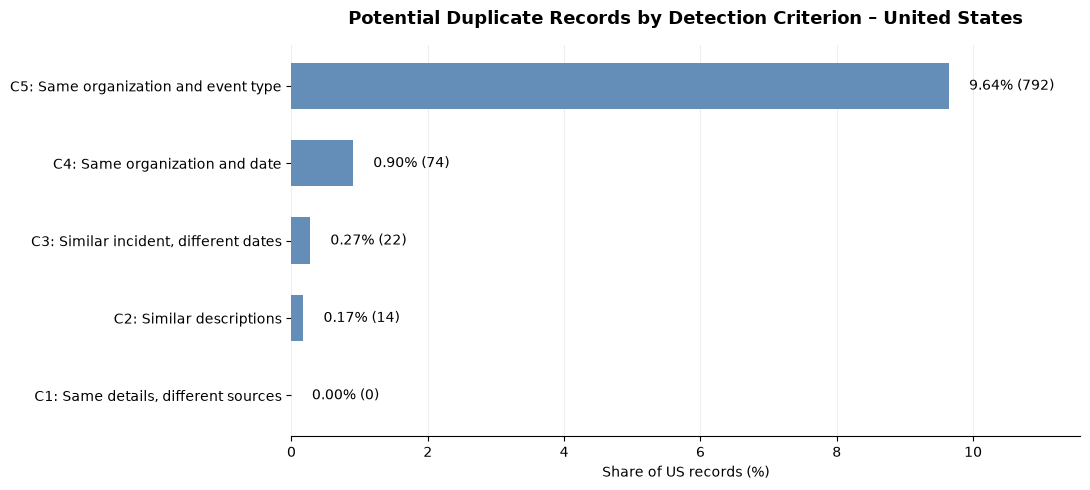

In [26]:
# Compare the share of US records flagged by each criterion
usa_duplicate_plot_data = (
    usa_duplicate_criteria_summary
    .sort_values("Share (%)", ascending=True)
)

fig_usa_duplicate_criteria, ax_usa_duplicate_criteria = plt.subplots(
    figsize=(11, 5)
)

bars = ax_usa_duplicate_criteria.barh(
    usa_duplicate_plot_data["Criterion"],
    usa_duplicate_plot_data["Share (%)"],
    color="#648DB7",
    height=0.6
)

for bar, share, count in zip(
    bars,
    usa_duplicate_plot_data["Share (%)"],
    usa_duplicate_plot_data["Records involved"]
):
    ax_usa_duplicate_criteria.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{share:.2f}% ({count:,})",
        va="center",
        fontsize=10
    )

ax_usa_duplicate_criteria.set_title(
    "Potential Duplicate Records by Detection Criterion – United States",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax_usa_duplicate_criteria.set_xlabel("Share of US records (%)")
ax_usa_duplicate_criteria.set_ylabel("")
ax_usa_duplicate_criteria.set_xlim(
    0,
    max(5, usa_duplicate_plot_data["Share (%)"].max() * 1.2)
)

ax_usa_duplicate_criteria.grid(axis="x", alpha=0.2)
ax_usa_duplicate_criteria.set_axisbelow(True)
ax_usa_duplicate_criteria.spines[
    ["top", "right", "left"]
].set_visible(False)

fig_usa_duplicate_criteria.tight_layout()
plt.show()

### 2.6 Conservative deduplication

Additional duplicate candidates are identified when all attributes except the record identifier and event date agree, with a date difference of no more than seven days. These cases are reviewed separately before deduplication. Ambiguous records are retained.

In [27]:
# Identify highly reliable duplicate candidates with differing event dates
date_duplicate_columns = [
    col for col in usa_clean.columns
    if col not in ["slug", "event_date", "year", "month"]
]

usa_date_duplicate_groups = []
usa_date_duplicate_review = []

for _, group in usa_clean.groupby(
    date_duplicate_columns, dropna=False, sort=False
):
    if len(group) != 2:
        continue

    group = group.sort_values(["event_date", "slug"])
    date_difference = (
        group["event_date"].iloc[1] - group["event_date"].iloc[0]
    ).days

    if not 0 < date_difference <= 7:
        continue

    group_id = len(usa_date_duplicate_groups) + 1
    usa_date_duplicate_groups.append(group["slug"].tolist())

    for _, record in group.iterrows():
        usa_date_duplicate_review.append({
            "Group": group_id,
            "Slug": record["slug"],
            "Event date": record["event_date"],
            "Date difference (days)": date_difference,
            "Organization": record["organization"],
            "Source URL": record["source_url"]
        })

usa_date_duplicate_review = pd.DataFrame(usa_date_duplicate_review)

print(f"Candidate pairs: {len(usa_date_duplicate_groups)}")
print(f"Records involved: {len(usa_date_duplicate_review)}")

display(usa_date_duplicate_review)

Candidate pairs: 10
Records involved: 20


,Group,Slug,Event date,Date difference (days),Organization,Source URL
0,1,0a94dc150101116e,2019-06-23,4,Village of Key Biscayne,https://www.scmagazine.com/home/security-news/...
1,1,294c47693c4e1998,2019-06-27,4,Village of Key Biscayne,https://www.scmagazine.com/home/security-news/...
2,2,36ae7bdcd838d5f4,2019-06-17,2,A. Duie Pyle,https://www.scmagazine.com/home/security-news/...
3,2,e23c652772cc4d37,2019-06-19,2,A. Duie Pyle,https://www.scmagazine.com/home/security-news/...
4,3,ec943be9d383c5bb,2019-06-15,1,Bella Thorne,https://securityaffairs.co/wordpress/87197/cyb...
5,3,40f19c254cfa18eb,2019-06-16,1,Bella Thorne,https://securityaffairs.co/wordpress/87197/cyb...
6,4,47820d469b743f8e,2019-06-14,4,Olean Medical Group,https://www.databreaches.net/ny-cyber-attacks-...
7,4,6a5bc29288f8c07a,2019-06-18,4,Olean Medical Group,https://www.databreaches.net/ny-cyber-attacks-...
8,5,c2fc31c0609a0a38,2019-06-13,1,N.E.O. Urology,https://www.databreaches.net/oh-n-e-o-urology-...
9,5,4adce619b8be6171,2019-06-14,1,N.E.O. Urology,https://www.databreaches.net/oh-n-e-o-urology-...


Ten additional pairs were identified with identical attributes except for their identifiers and event dates. **Since the dates differ by no more than five days, one record per pair is retained, using the earlier date as a consistent selection rule.** The discarded identifiers and alternative dates remain documented. All ambiguous candidates are retained.

In [28]:
# Retain the earlier-dated record from each confirmed duplicate pair
slugs_to_remove = {
    pair[1]
    for pair in usa_date_duplicate_groups
}

usa_final = usa_clean.loc[
    ~usa_clean["slug"].isin(slugs_to_remove)
].copy()

assert len(usa_date_duplicate_groups) == 10
assert len(slugs_to_remove) == 10
assert len(usa_final) == len(usa_clean) - 10
assert usa_final["slug"].is_unique

print(f"Original US records: {len(usa):,}")
print(f"Exact duplicates removed: {len(usa) - len(usa_clean):,}")
print(f"Additional duplicates removed: {len(slugs_to_remove):,}")
print(f"Final US records: {len(usa_final):,}")

Original US records: 8,274
Exact duplicates removed: 61
Additional duplicates removed: 10
Final US records: 8,203


## 3. Temporal coverage and incident trends

The temporal distribution of documented US cyber incidents is examined to assess dataset coverage, identify changes over time, and establish a basis for subsequent comparisons.

### 3.1 Annual incident distribution



In [29]:
# Examine annual incident counts in the deduplicated US dataset
usa_annual_counts = (
    usa_final.groupby("year")
    .size()
    .reset_index(name="Incidents")
    .sort_values("year")
)

usa_annual_counts["Share (%)"] = (
    usa_annual_counts["Incidents"] / len(usa_final) * 100
).round(2)

display(usa_annual_counts)

,year,Incidents,Share (%)
0,2014,283,3.45
1,2015,380,4.63
2,2016,456,5.56
3,2017,366,4.46
4,2018,450,5.49
5,2019,590,7.19
6,2020,927,11.30
7,2021,724,8.83
8,2022,933,11.37
9,2023,1388,16.92


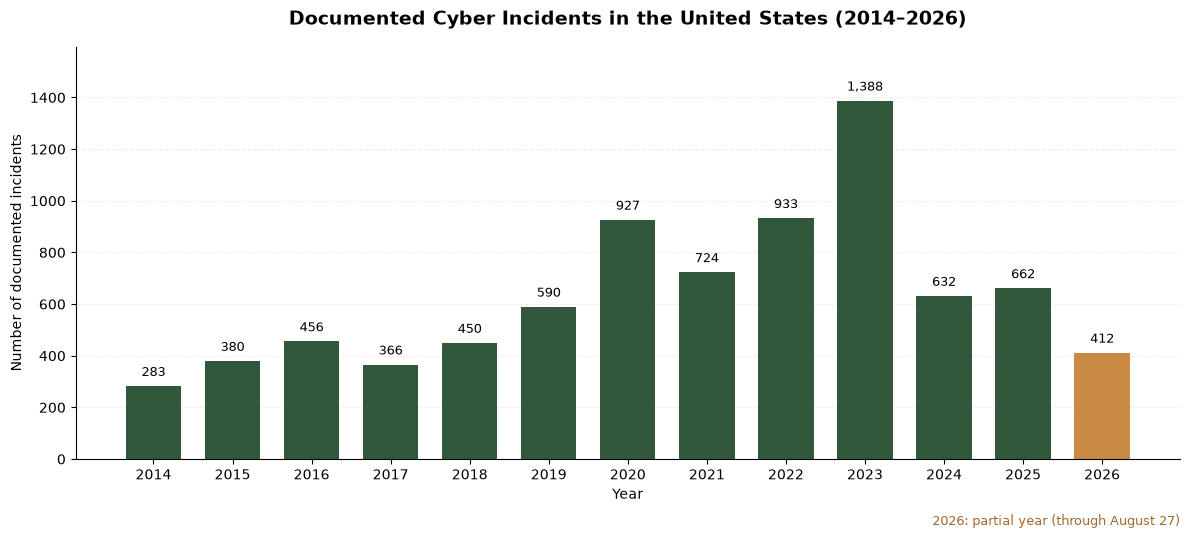

In [30]:
# Visualize annual documented cyber incidents in the United States
fig_usa_annual_incidents, ax_usa_annual_incidents = plt.subplots(
    figsize=(12, 5.5)
)

annual_colors = [
    "#31583B" if year != 2026 else "#C98A43"
    for year in usa_annual_counts["year"]
]

bars = ax_usa_annual_incidents.bar(
    usa_annual_counts["year"],
    usa_annual_counts["Incidents"],
    color=annual_colors,
    width=0.7
)

# Label annual incident counts
for bar in bars:
    ax_usa_annual_incidents.annotate(
        f"{int(bar.get_height()):,}",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_usa_annual_incidents.set_title(
    "Documented Cyber Incidents in the United States (2014–2026)",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax_usa_annual_incidents.set_xlabel("Year")
ax_usa_annual_incidents.set_ylabel("Number of documented incidents")
ax_usa_annual_incidents.set_xticks(
    usa_annual_counts["year"]
)

ax_usa_annual_incidents.set_ylim(
    0,
    usa_annual_counts["Incidents"].max() * 1.15
)

ax_usa_annual_incidents.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)
ax_usa_annual_incidents.set_axisbelow(True)

ax_usa_annual_incidents.spines[
    ["top", "right"]
].set_visible(False)

ax_usa_annual_incidents.annotate(
    "2026: partial year (through August 27)",
    xy=(1, -0.16),
    xycoords="axes fraction",
    ha="right",
    fontsize=9,
    color="#A06A2B"
)

fig_usa_annual_incidents.tight_layout()
plt.show()

### 3.2 Monthly and seasonal patterns

In [31]:
# Examine monthly incident counts for each year
usa_monthly_counts = (
    usa_final
    .groupby(["year", "month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

usa_monthly_counts.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(usa_monthly_counts)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2014,34,26,18,24,19,31,20,43,25,37,6,0
2015,42,32,51,24,33,19,32,35,28,27,30,27
2016,38,33,59,45,39,62,28,28,34,25,29,36
2017,52,28,15,37,34,32,30,23,28,25,29,33
2018,29,48,37,31,40,34,45,31,28,28,44,55
2019,36,38,53,53,40,33,66,50,49,62,50,60
2020,92,79,54,48,57,54,64,92,127,116,57,87
2021,70,99,110,54,50,56,40,48,53,50,41,53
2022,48,38,74,88,73,59,111,111,73,83,93,82


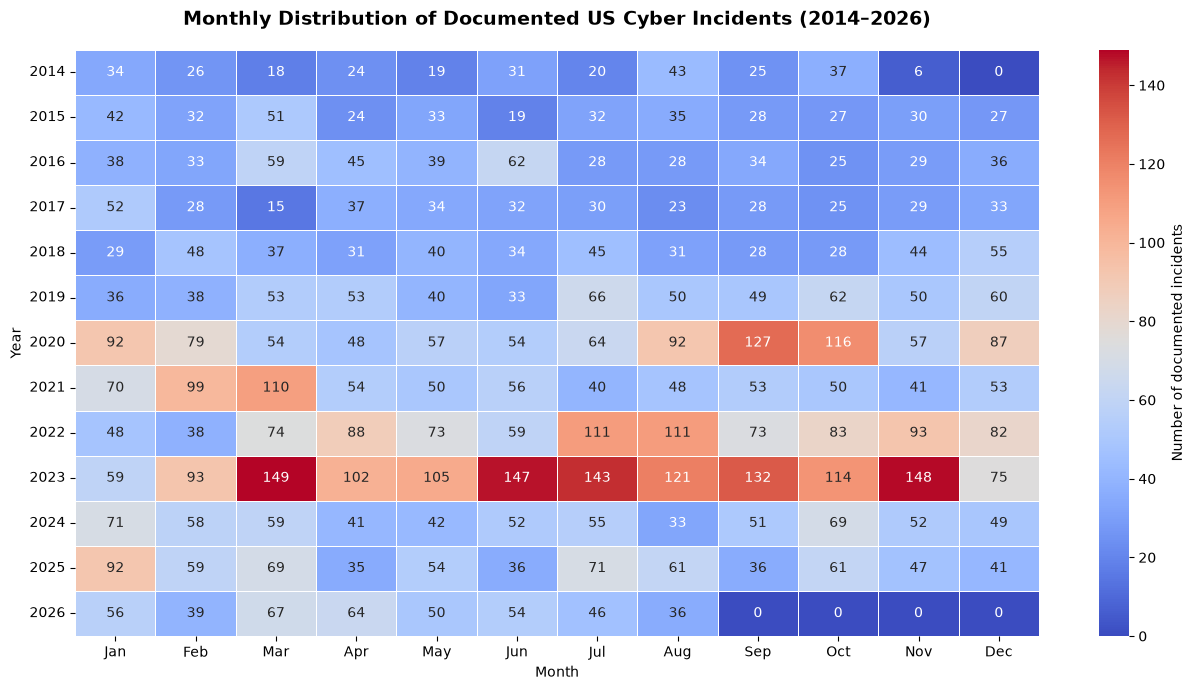

In [32]:
# Visualize monthly incident counts across years
fig_usa_monthly_heatmap, ax_usa_monthly_heatmap = plt.subplots(
    figsize=(13, 7)
)

sns.heatmap(
    usa_monthly_counts,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Number of documented incidents"},
    ax=ax_usa_monthly_heatmap
)

ax_usa_monthly_heatmap.set_title(
    "Monthly Distribution of Documented US Cyber Incidents (2014–2026)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax_usa_monthly_heatmap.set_xlabel("Month")
ax_usa_monthly_heatmap.set_ylabel("Year")

ax_usa_monthly_heatmap.tick_params(axis="x", rotation=0)
ax_usa_monthly_heatmap.tick_params(axis="y", rotation=0)

fig_usa_monthly_heatmap.tight_layout()
plt.show()

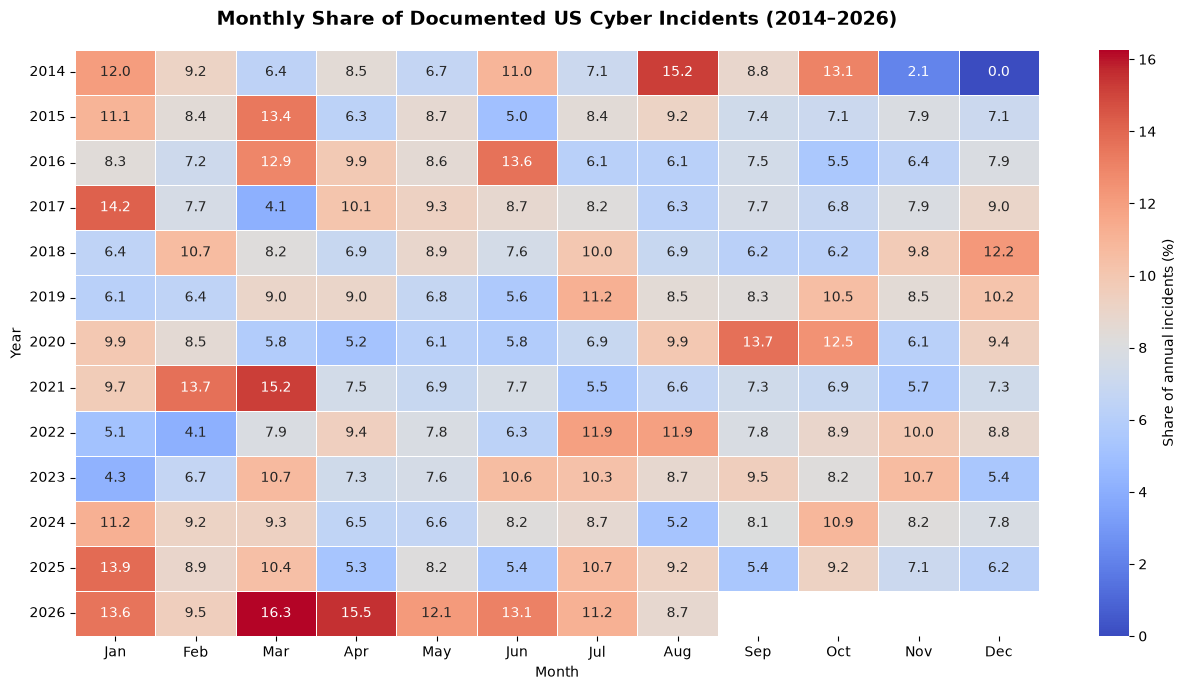

In [33]:
# Calculate each month's share of its annual incident total
usa_monthly_shares = (
    usa_monthly_counts
    .div(usa_monthly_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Exclude months outside the dataset's coverage period
usa_monthly_shares.loc[2026, ["Sep", "Oct", "Nov", "Dec"]] = np.nan

# Visualize monthly shares within each year
fig_usa_monthly_shares, ax_usa_monthly_shares = plt.subplots(
    figsize=(13, 7)
)

sns.heatmap(
    usa_monthly_shares,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.5,
    linecolor="white",
    mask=usa_monthly_shares.isna(),
    cbar_kws={"label": "Share of annual incidents (%)"},
    ax=ax_usa_monthly_shares
)

ax_usa_monthly_shares.set_title(
    "Monthly Share of Documented US Cyber Incidents (2014–2026)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax_usa_monthly_shares.set_xlabel("Month")
ax_usa_monthly_shares.set_ylabel("Year")

ax_usa_monthly_shares.tick_params(axis="x", rotation=0)
ax_usa_monthly_shares.tick_params(axis="y", rotation=0)

fig_usa_monthly_shares.tight_layout()
plt.show()

In [34]:
# Compare annual sector shares around the 2023 peak
usa_sector_2023_counts = (
    usa_final.loc[usa_final["year"].between(2022, 2024)]
    .groupby(["industry", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[2022, 2023, 2024], fill_value=0)
)

usa_sector_2023_shares = (
    usa_sector_2023_counts
    .div(usa_sector_2023_counts.sum(axis=0), axis=1)
    .mul(100)
)

usa_sector_2023_shares["Change 2022–2023 (pp)"] = (
    usa_sector_2023_shares[2023]
    - usa_sector_2023_shares[2022]
)

usa_sector_2023_shares = (
    usa_sector_2023_shares
    .sort_values("Change 2022–2023 (pp)", ascending=False)
)

display(usa_sector_2023_shares.round(2))

year,2022,2023,2024,Change 2022–2023 (pp)
industry,,,,
Finance and Insurance,9.43,15.06,11.87,5.63
Educational Services,10.72,12.82,8.23,2.11
Wholesale Trade,0.64,1.08,0.00,0.44
Public Administration,8.36,8.72,14.87,0.36
Management of Companies and Enterprises,0.00,0.22,0.00,0.22
"Mining, Quarrying, and Oil and Gas Extraction",0.32,0.50,0.47,0.18
"Arts, Entertainment, and Recreation",1.71,1.80,2.69,0.09
Undetermined,0.21,0.29,2.37,0.07
"Agriculture, Forestry, Fishing and Hunting",0.11,0.07,0.00,-0.04


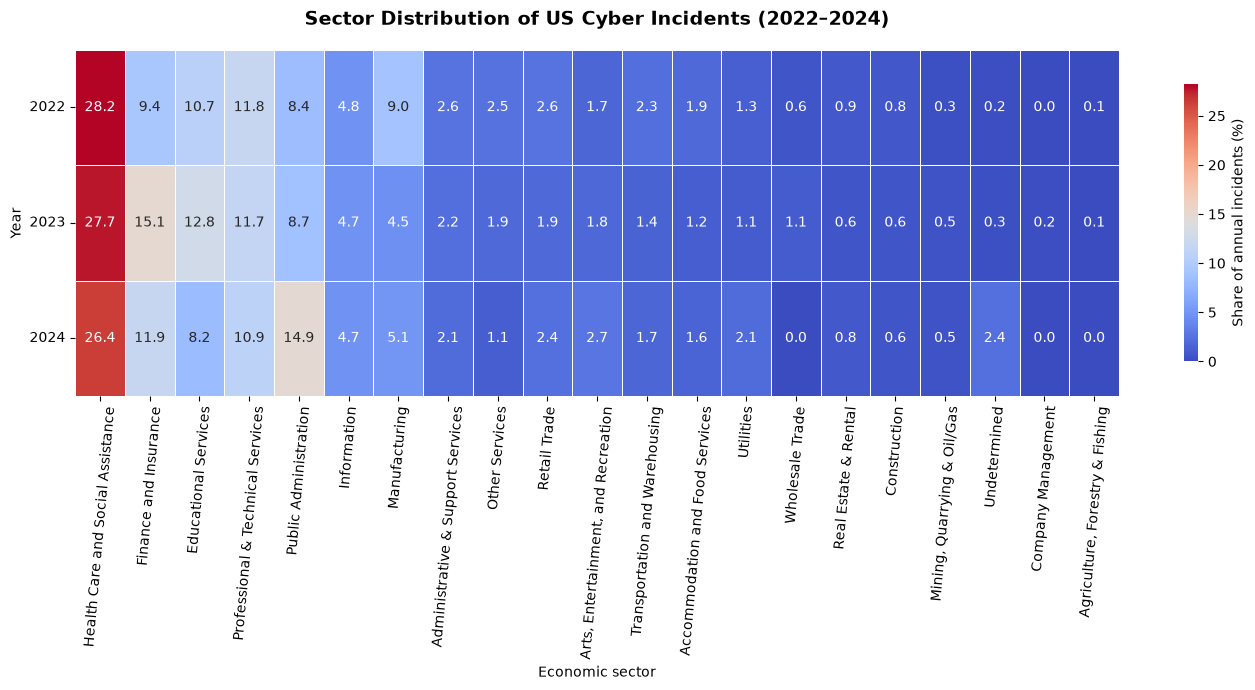

In [35]:
# Prepare shorter sector labels for visualization
usa_sector_heatmap_data = (
    usa_sector_2023_shares[[2022, 2023, 2024]]
    .sort_values(2023, ascending=False)
    .copy()
)

sector_display_names = {
    "Administrative and Support and Waste Management and Remediation Services":
        "Administrative & Support Services",
    "Professional, Scientific, and Technical Services":
        "Professional & Technical Services",
    "Mining, Quarrying, and Oil and Gas Extraction":
        "Mining, Quarrying & Oil/Gas",
    "Agriculture, Forestry, Fishing and Hunting":
        "Agriculture, Forestry & Fishing",
    "Real Estate and Rental and Leasing":
        "Real Estate & Rental",
    "Other Services (except Public Administration)":
        "Other Services",
    "Management of Companies and Enterprises":
        "Company Management"
}

usa_sector_heatmap_data = usa_sector_heatmap_data.rename(
    index=sector_display_names
)

# Visualize sector shares using a wider layout
fig_usa_sector_heatmap, ax_usa_sector_heatmap = plt.subplots(
    figsize=(14, 7)
)

sns.heatmap(
    usa_sector_heatmap_data.T,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Share of annual incidents (%)",
        "shrink": 0.8
    },
    ax=ax_usa_sector_heatmap
)

ax_usa_sector_heatmap.set_title(
    "Sector Distribution of US Cyber Incidents (2022–2024)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax_usa_sector_heatmap.set_xlabel("Economic sector")
ax_usa_sector_heatmap.set_ylabel("Year")

ax_usa_sector_heatmap.tick_params(axis="x", rotation=85)
ax_usa_sector_heatmap.tick_params(axis="y", rotation=0)

fig_usa_sector_heatmap.tight_layout()
plt.show()

In [36]:
# Examine annual incident counts across all economic sectors
usa_sector_annual_counts = (
    usa_final
    .groupby(["industry", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(2014, 2027), fill_value=0)
)

usa_sector_annual_counts["Total"] = (
    usa_sector_annual_counts.sum(axis=1)
)

usa_sector_annual_counts = (
    usa_sector_annual_counts
    .sort_values("Total", ascending=False)
)

display(usa_sector_annual_counts)

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
industry,,,,,,,,,,,,,,
Health Care and Social Assistance,17,23,34,57,108,147,214,238,263,384,167,184,65,1901
Public Administration,33,61,69,52,79,116,134,74,78,121,94,119,54,1084
Educational Services,28,50,31,51,59,101,167,108,100,178,52,61,31,1017
"Professional, Scientific, and Technical Services",16,9,72,36,12,44,91,71,110,162,69,45,24,761
Information,66,95,72,46,40,30,65,44,45,65,30,75,58,731
Finance and Insurance,6,16,21,13,22,24,40,32,88,209,75,65,35,646
Other Services (except Public Administration),40,42,85,33,32,27,49,15,23,26,7,5,5,389
Manufacturing,8,4,3,9,12,14,19,35,84,63,32,27,48,358
Retail Trade,23,18,14,12,17,19,30,27,24,26,15,20,15,260


In [37]:
# Calculate each sector's share of all documented incidents per year
usa_sector_annual_shares = (
    usa_sector_annual_counts
    .drop(columns="Total")
    .div(usa_annual_counts.set_index("year")["Incidents"], axis=1)
    .mul(100)
)

# Calculate sector shares across the entire observation period
usa_sector_annual_shares["Total (%)"] = (
    usa_sector_annual_counts["Total"] / len(usa_final) * 100
)

usa_sector_annual_shares = (
    usa_sector_annual_shares
    .sort_values("Total (%)", ascending=False)
)

display(usa_sector_annual_shares.round(2))

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total (%)
industry,,,,,,,,,,,,,,
Health Care and Social Assistance,6.01,6.05,7.46,15.57,24.00,24.92,23.09,32.87,28.19,27.67,26.42,27.79,15.78,23.17
Public Administration,11.66,16.05,15.13,14.21,17.56,19.66,14.46,10.22,8.36,8.72,14.87,17.98,13.11,13.21
Educational Services,9.89,13.16,6.80,13.93,13.11,17.12,18.02,14.92,10.72,12.82,8.23,9.21,7.52,12.40
"Professional, Scientific, and Technical Services",5.65,2.37,15.79,9.84,2.67,7.46,9.82,9.81,11.79,11.67,10.92,6.80,5.83,9.28
Information,23.32,25.00,15.79,12.57,8.89,5.08,7.01,6.08,4.82,4.68,4.75,11.33,14.08,8.91
Finance and Insurance,2.12,4.21,4.61,3.55,4.89,4.07,4.31,4.42,9.43,15.06,11.87,9.82,8.50,7.88
Other Services (except Public Administration),14.13,11.05,18.64,9.02,7.11,4.58,5.29,2.07,2.47,1.87,1.11,0.76,1.21,4.74
Manufacturing,2.83,1.05,0.66,2.46,2.67,2.37,2.05,4.83,9.00,4.54,5.06,4.08,11.65,4.36
Retail Trade,8.13,4.74,3.07,3.28,3.78,3.22,3.24,3.73,2.57,1.87,2.37,3.02,3.64,3.17


In [38]:
# Define concise sector labels for visualizations
sector_display_names = {
    "Health Care and Social Assistance": "Health Care",
    "Public Administration": "Public Administration",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional & Technical",
    "Information": "Information",
    "Finance and Insurance": "Finance & Insurance",
    "Other Services (except Public Administration)": "Other Services",
    "Manufacturing": "Manufacturing",
    "Retail Trade": "Retail Trade",
    "Arts, Entertainment, and Recreation": "Arts & Recreation",
    "Accommodation and Food Services": "Accommodation & Food",
    "Transportation and Warehousing": "Transport & Warehousing",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative & Support",
    "Utilities": "Utilities",
    "Undetermined": "Undetermined",
    "Wholesale Trade": "Wholesale Trade",
    "Real Estate and Rental and Leasing": "Real Estate",
    "Construction": "Construction",
    "Mining, Quarrying, and Oil and Gas Extraction": "Mining & Oil/Gas",
    "Agriculture, Forestry, Fishing and Hunting": "Agriculture & Forestry",
    "Management of Companies and Enterprises": "Company Management"
}

assert len(sector_display_names) == len(usa_sector_annual_counts)
assert set(sector_display_names) == set(usa_sector_annual_counts.index)

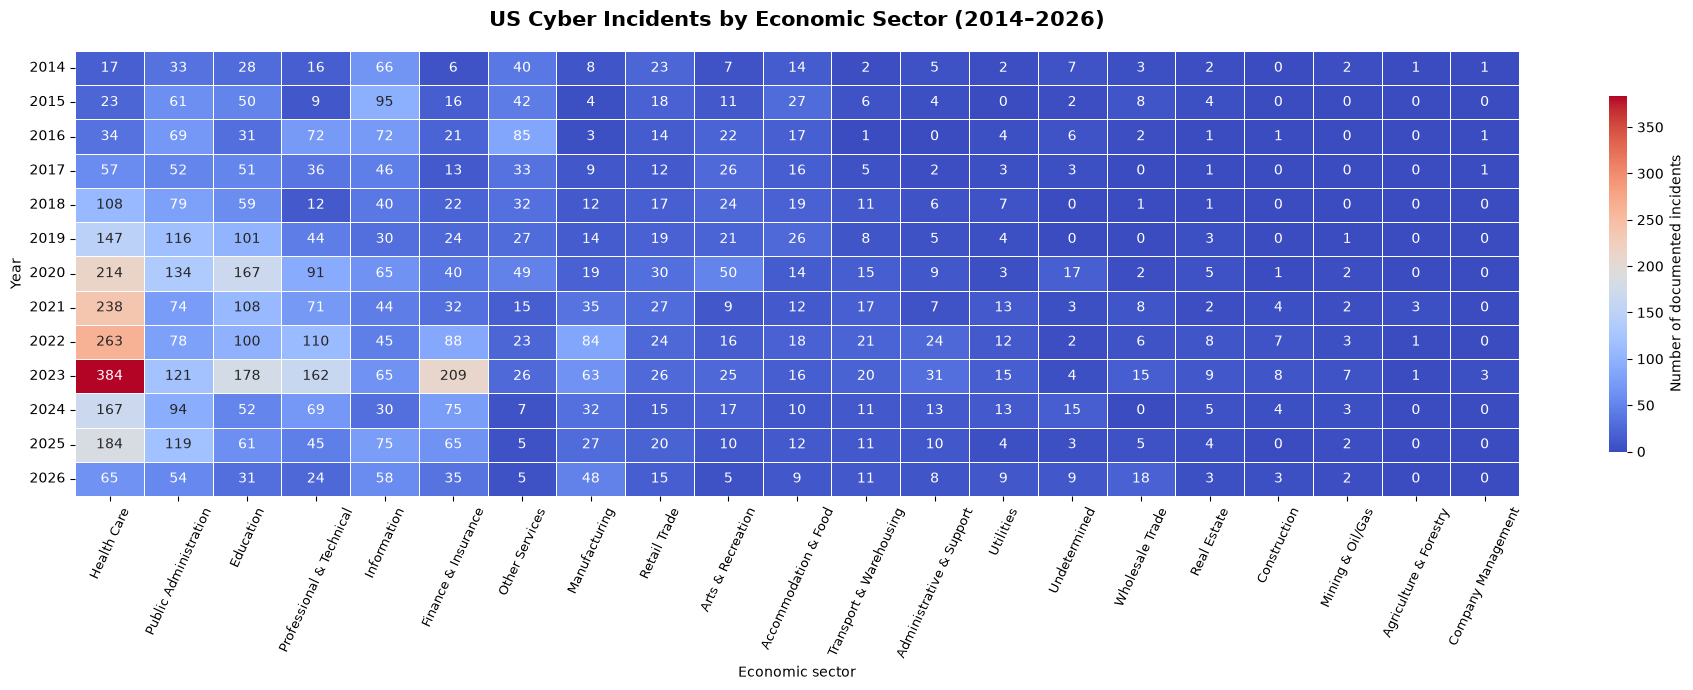

In [39]:
# Visualize annual incident counts by economic sector
usa_sector_counts_heatmap_data = (
    usa_sector_annual_counts
    .drop(columns="Total")
    .rename(index=sector_display_names)
    .T
)

fig_usa_sector_counts_heatmap, ax_usa_sector_counts_heatmap = (
    plt.subplots(figsize=(19, 7))
)

sns.heatmap(
    usa_sector_counts_heatmap_data,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Number of documented incidents",
        "shrink": 0.8
    },
    ax=ax_usa_sector_counts_heatmap
)

ax_usa_sector_counts_heatmap.set_title(
    "US Cyber Incidents by Economic Sector (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_sector_counts_heatmap.set_xlabel("Economic sector")
ax_usa_sector_counts_heatmap.set_ylabel("Year")

ax_usa_sector_counts_heatmap.tick_params(
    axis="x", rotation=65, labelsize=9
)
ax_usa_sector_counts_heatmap.tick_params(
    axis="y", rotation=0
)

fig_usa_sector_counts_heatmap.tight_layout()
plt.show()

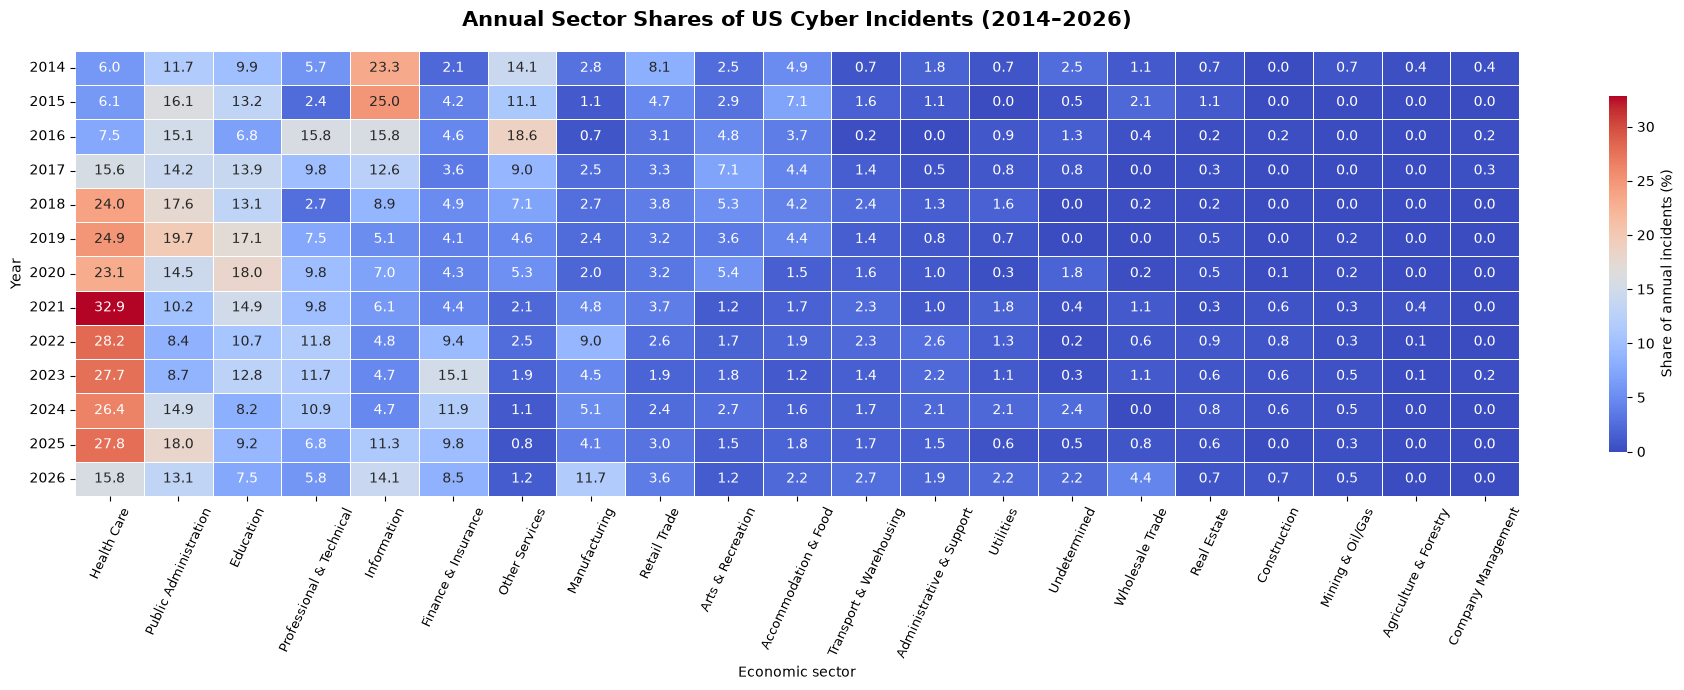

In [40]:
# Visualize sector shares within each year
usa_sector_shares_heatmap_data = (
    usa_sector_annual_shares
    .drop(columns="Total (%)")
    .rename(index=sector_display_names)
    .T
)

fig_usa_sector_shares_heatmap, ax_usa_sector_shares_heatmap = (
    plt.subplots(figsize=(19, 7))
)

sns.heatmap(
    usa_sector_shares_heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Share of annual incidents (%)",
        "shrink": 0.8
    },
    ax=ax_usa_sector_shares_heatmap
)

ax_usa_sector_shares_heatmap.set_title(
    "Annual Sector Shares of US Cyber Incidents (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_sector_shares_heatmap.set_xlabel("Economic sector")
ax_usa_sector_shares_heatmap.set_ylabel("Year")

ax_usa_sector_shares_heatmap.tick_params(
    axis="x", rotation=65, labelsize=9
)
ax_usa_sector_shares_heatmap.tick_params(
    axis="y", rotation=0
)

fig_usa_sector_shares_heatmap.tight_layout()
plt.show()

#### Observations and potential explanations

The visualizations reveal several patterns in the sectoral distribution of documented US cyber incidents between 2014 and 2026:

- **Health Care and Social Assistance:** The sector becomes increasingly prominent from 2017 onward and accounts for a substantial share of documented incidents between 2018 and 2025.
- **Educational Services:** Relatively high shares are observed between 2019 and 2021, particularly in 2020 (18.0%). The transition to remote education during the COVID-19 pandemic is a possible factor worth investigating.
- **Information:** The sector accounts for approximately one-quarter of documented incidents in 2014–2015, followed by a considerable decline in its relative share. Changes in reporting coverage, sector classification, or the composition of documented incidents may help explain this pattern.
- **Finance and Insurance:** A pronounced increase is observed in 2023 (15.1%). Further examination of incident types and affected organizations may help explain this concentration.
- **Public Administration:** The sector maintains a substantial presence throughout the observation period, with notable variation between years.
- **Other Services:** The sector is particularly prominent in 2016 (18.6%), raising questions about which organizations and activities contributed to this concentration.

These observations describe patterns in the UMD dataset rather than changes in actual cyberattack risk. Potential explanations remain hypotheses for further investigation, particularly through incident types, subtypes, affected organizations, and reporting practices.

## 4. Geographical distribution

The geographical distribution of documented US cyber incidents is examined across states and years to identify differences in reporting coverage, geographical concentration, and changes over time.

### 4.1 Incidents by state

The number of documented incidents is compared across states, while unspecified locations and US territories are retained as separate categories.

In [41]:
# Examine the geographical distribution of documented US incidents
usa_state_counts = (
    usa_final["state"]
    .fillna("Missing")
    .replace({
        "undetermined": "Undetermined"
    })
    .value_counts()
    .rename_axis("State")
    .reset_index(name="Incidents")
)

usa_state_counts["Share (%)"] = (
    usa_state_counts["Incidents"] / len(usa_final) * 100
).round(2)

display(usa_state_counts)

,State,Incidents,Share (%)
0,Undetermined,1441,17.57
1,California,925,11.28
2,Texas,546,6.66
3,New York,488,5.95
4,Florida,332,4.05
5,Illinois,279,3.40
6,Pennsylvania,236,2.88
7,Georgia,235,2.86
8,Massachusetts,232,2.83
9,Washington,196,2.39


### 4.2 State-level coverage by year

Annual incident counts are examined across US states to identify geographical concentrations, changes in reporting coverage, and states with unusually high numbers of documented incidents in particular years.

In [42]:
# Examine annual incident counts across US states and territories
usa_state_annual_counts = (
    usa_final.assign(
        state_label=usa_final["state"]
        .fillna("Missing")
        .replace({"undetermined": "Undetermined"})
    )
    .groupby(["state_label", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(2014, 2027), fill_value=0)
)

usa_state_annual_counts["Total"] = (
    usa_state_annual_counts.sum(axis=1)
)

usa_state_annual_counts = (
    usa_state_annual_counts
    .sort_values("Total", ascending=False)
)

display(usa_state_annual_counts)

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
state_label,,,,,,,,,,,,,,
Undetermined,62,100,151,103,116,139,223,96,105,84,121,103,38,1441
California,47,46,59,49,49,36,88,83,111,184,75,54,44,925
Texas,11,16,15,26,20,28,56,44,82,107,48,57,36,546
New York,18,26,27,14,26,31,63,41,50,95,28,40,29,488
Florida,7,7,18,6,23,27,43,34,38,55,29,28,17,332
Illinois,11,13,5,8,10,9,29,41,35,68,19,16,15,279
Pennsylvania,9,7,1,5,7,16,28,25,29,50,19,29,11,236
Georgia,4,4,10,15,9,19,21,21,37,47,15,19,14,235
Massachusetts,7,8,11,8,7,14,23,26,29,48,20,16,15,232


In [43]:
excluded_locations = [
    "Undetermined", "Missing", "Multiple",
    "Washington D.C.", "Puerto Rico",
    "Virgin Islands", "Guam"
]

In [44]:
# Prepare incident counts for the 50 US states
usa_state_heatmap_counts = (
    usa_state_annual_counts
    .drop(index=excluded_locations, errors="ignore")
    .drop(columns="Total")
    .sort_values(
        by=list(range(2014, 2027)),
        axis=0,
        key=None
    )
)

# Order states by their total documented incident count
usa_state_heatmap_counts = usa_state_heatmap_counts.loc[
    usa_state_heatmap_counts.sum(axis=1).sort_values(ascending=False).index
]

# Calculate shares among incidents assigned to the 50 states
usa_state_heatmap_shares = (
    usa_state_heatmap_counts
    .div(usa_state_heatmap_counts.sum(axis=0), axis=1)
    .mul(100)
)

print("States included:", len(usa_state_heatmap_counts))
print(
    "Annual share totals (%):",
    usa_state_heatmap_shares.sum(axis=0).round(2).to_dict()
)

States included: 50
Annual share totals (%): {2014: 100.0, 2015: 100.0, 2016: 100.0, 2017: 100.0, 2018: 100.0, 2019: 100.0, 2020: 100.0, 2021: 100.0, 2022: 100.0, 2023: 100.0, 2024: 100.0, 2025: 100.0, 2026: 100.0}


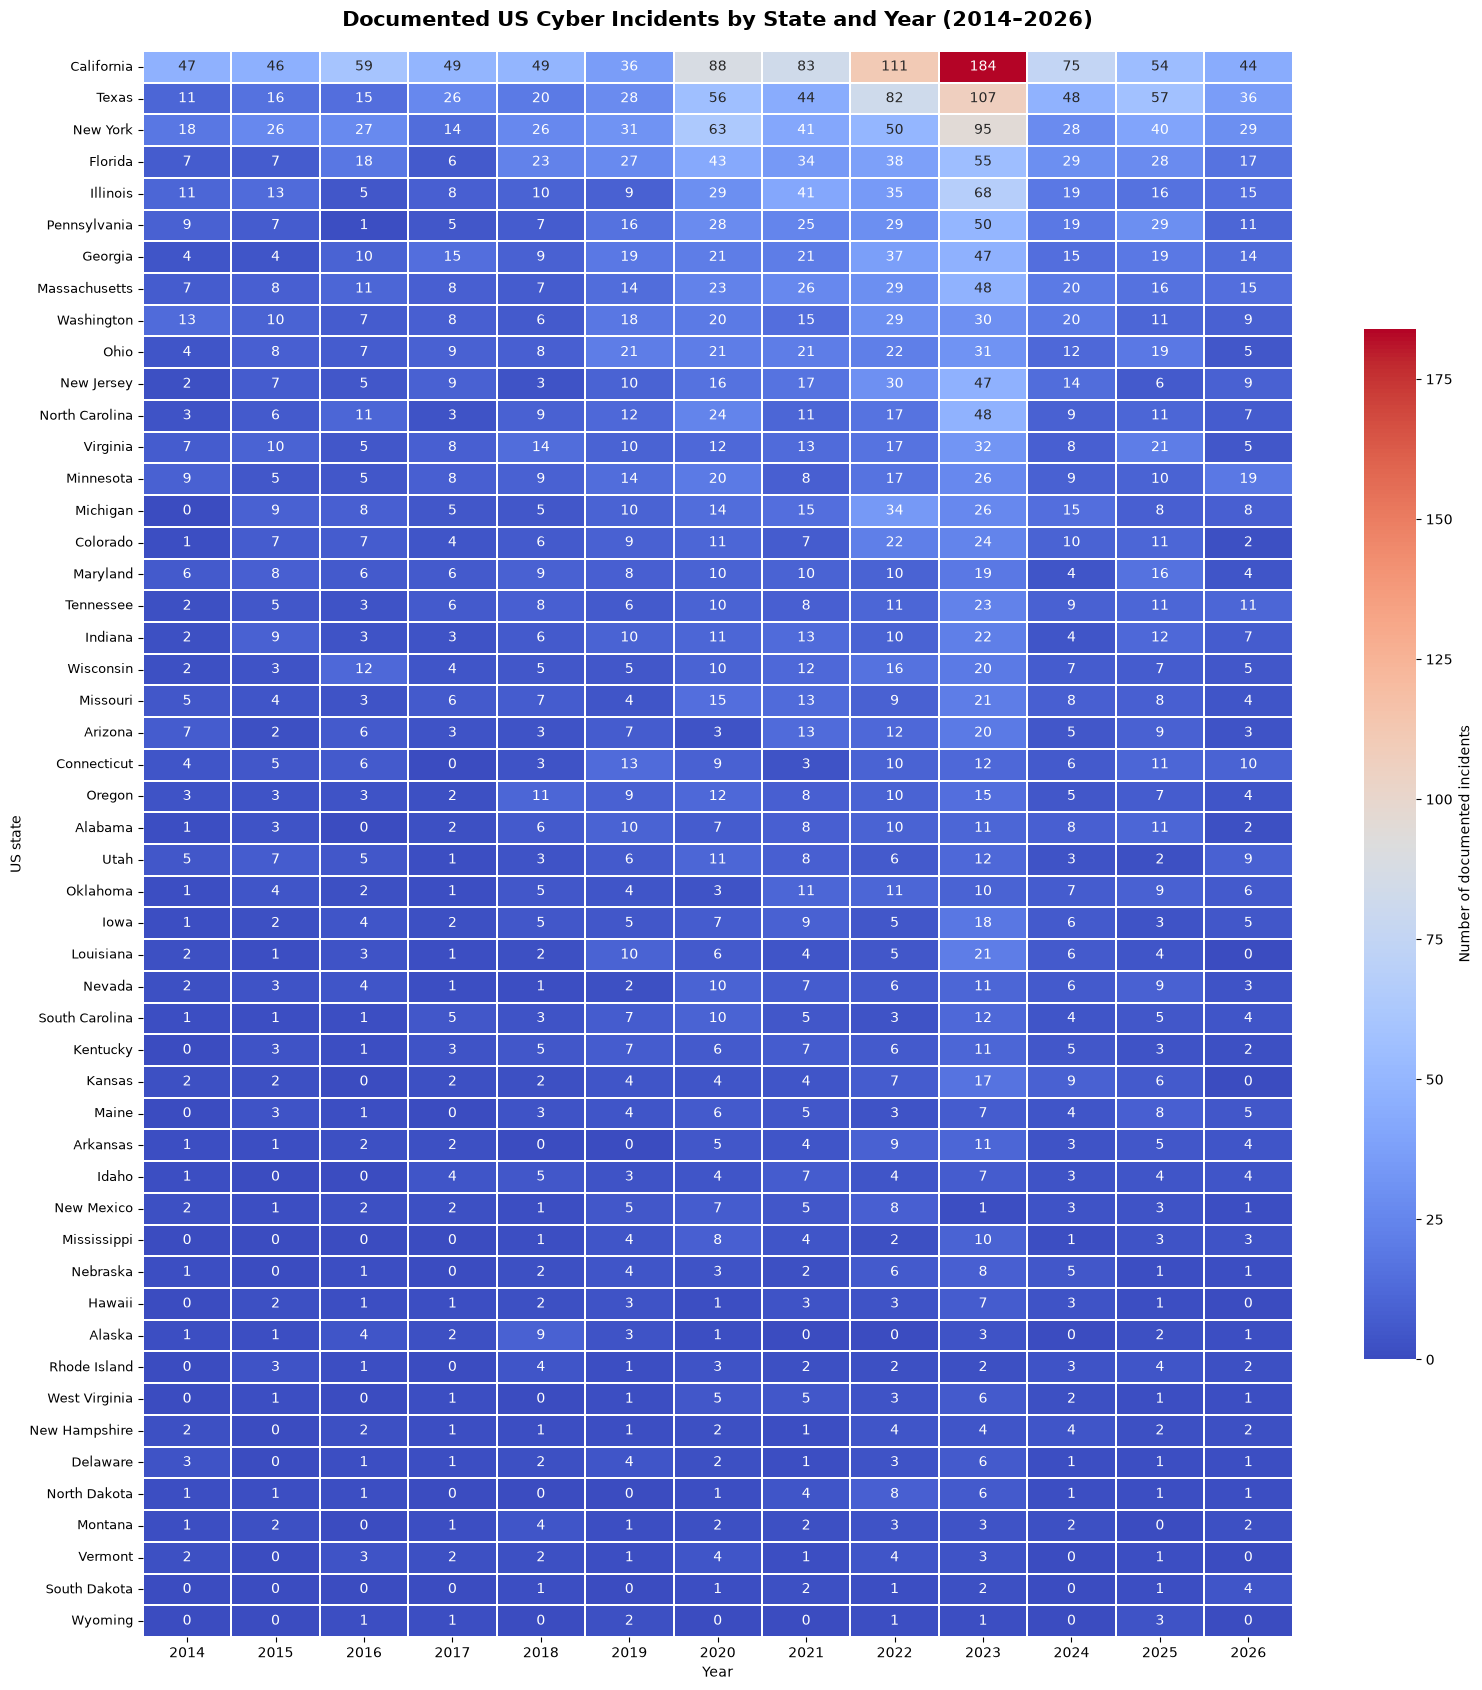

In [45]:
fig_usa_state_counts_heatmap, ax_usa_state_counts_heatmap = (
    plt.subplots(figsize=(16, 17))
)

sns.heatmap(
    usa_state_heatmap_counts,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=0.35,
    linecolor="white",
    cbar_kws={
        "label": "Number of documented incidents",
        "shrink": 0.65
    },
    ax=ax_usa_state_counts_heatmap
)

ax_usa_state_counts_heatmap.set_title(
    "Documented US Cyber Incidents by State and Year (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_state_counts_heatmap.set_xlabel("Year")
ax_usa_state_counts_heatmap.set_ylabel("US state")

ax_usa_state_counts_heatmap.tick_params(axis="x", rotation=0)
ax_usa_state_counts_heatmap.tick_params(axis="y", rotation=0, labelsize=9)

fig_usa_state_counts_heatmap.tight_layout()
plt.show()

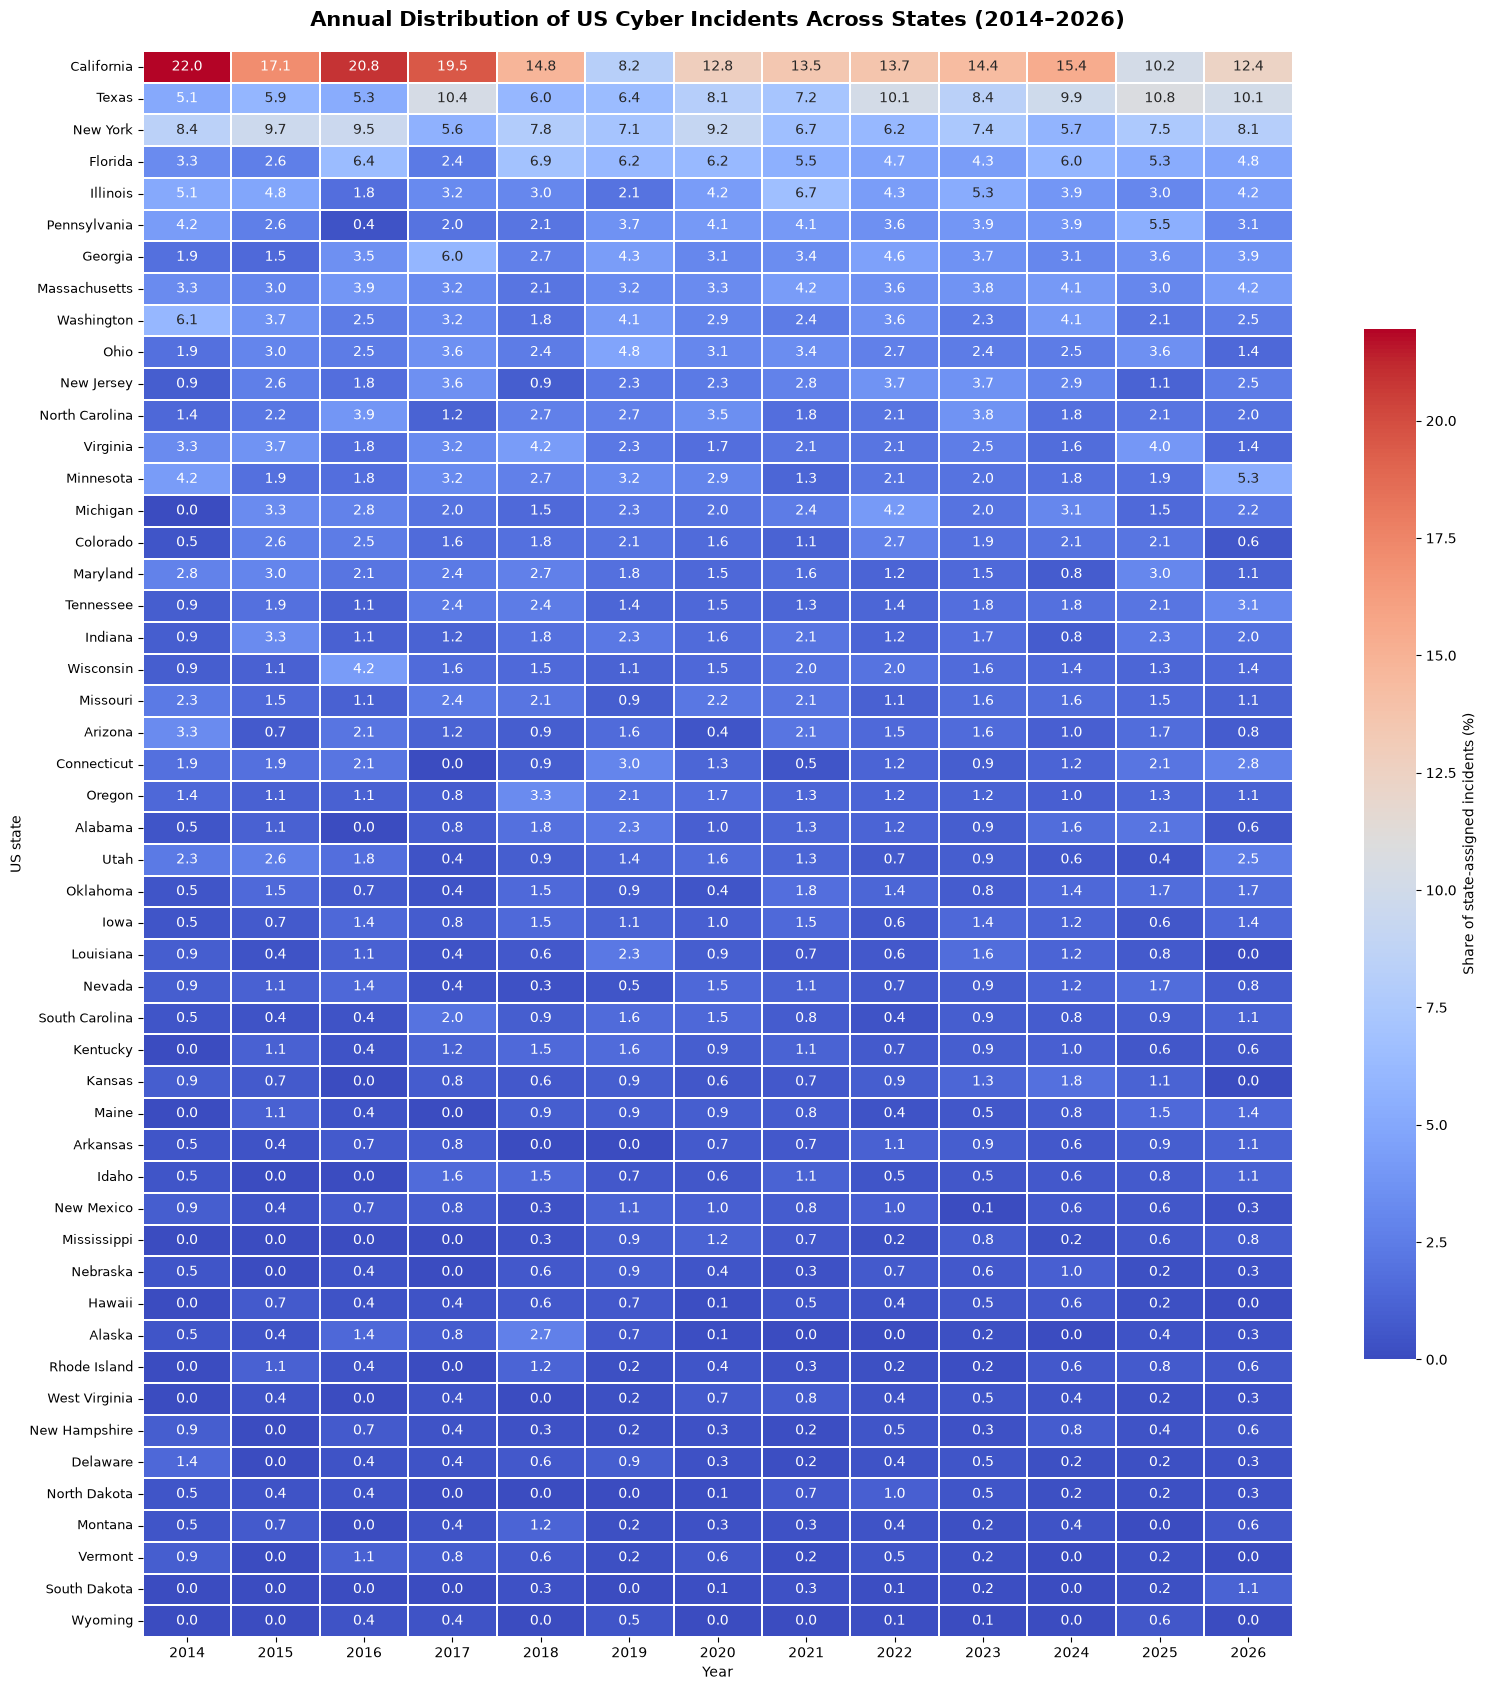

In [46]:
fig_usa_state_shares_heatmap, ax_usa_state_shares_heatmap = (
    plt.subplots(figsize=(16, 17))
)

sns.heatmap(
    usa_state_heatmap_shares,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    linewidths=0.35,
    linecolor="white",
    cbar_kws={
        "label": "Share of state-assigned incidents (%)",
        "shrink": 0.65
    },
    ax=ax_usa_state_shares_heatmap
)

ax_usa_state_shares_heatmap.set_title(
    "Annual Distribution of US Cyber Incidents Across States (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_state_shares_heatmap.set_xlabel("Year")
ax_usa_state_shares_heatmap.set_ylabel("US state")

ax_usa_state_shares_heatmap.tick_params(axis="x", rotation=0)
ax_usa_state_shares_heatmap.tick_params(axis="y", rotation=0, labelsize=9)

fig_usa_state_shares_heatmap.tight_layout()
plt.show()

#### 4.2.1 Top three states by year

In [47]:
# Identify the three most represented US states in each year

usa_top3_states_by_year = (
    usa_state_annual_counts
    .drop(index=excluded_locations, errors="ignore")
    .drop(columns="Total")
    .stack()
    .reset_index(name="Incidents")
    .rename(columns={"state_label": "State", "year": "Year"})
)

usa_top3_states_by_year = (
    usa_top3_states_by_year
    .sort_values(
        ["Year", "Incidents", "State"],
        ascending=[True, False, True]
    )
    .groupby("Year")
    .head(3)
    .copy()
)

usa_top3_states_by_year["Rank"] = (
    usa_top3_states_by_year.groupby("Year").cumcount() + 1
)

usa_top3_states_by_year["Share of annual US incidents (%)"] = (
    usa_top3_states_by_year["Incidents"]
    / usa_top3_states_by_year["Year"].map(
        usa_annual_counts.set_index("year")["Incidents"]
    )
    * 100
).round(2)

display(
    usa_top3_states_by_year[
        ["Year", "Rank", "State", "Incidents",
         "Share of annual US incidents (%)"]
    ].reset_index(drop=True)
)

,Year,Rank,State,Incidents,Share of annual US incidents (%)
0,2014,1,California,47,16.61
1,2014,2,New York,18,6.36
2,2014,3,Washington,13,4.59
3,2015,1,California,46,12.11
4,2015,2,New York,26,6.84
5,2015,3,Texas,16,4.21
6,2016,1,California,59,12.94
7,2016,2,New York,27,5.92
8,2016,3,Florida,18,3.95
9,2017,1,California,49,13.39


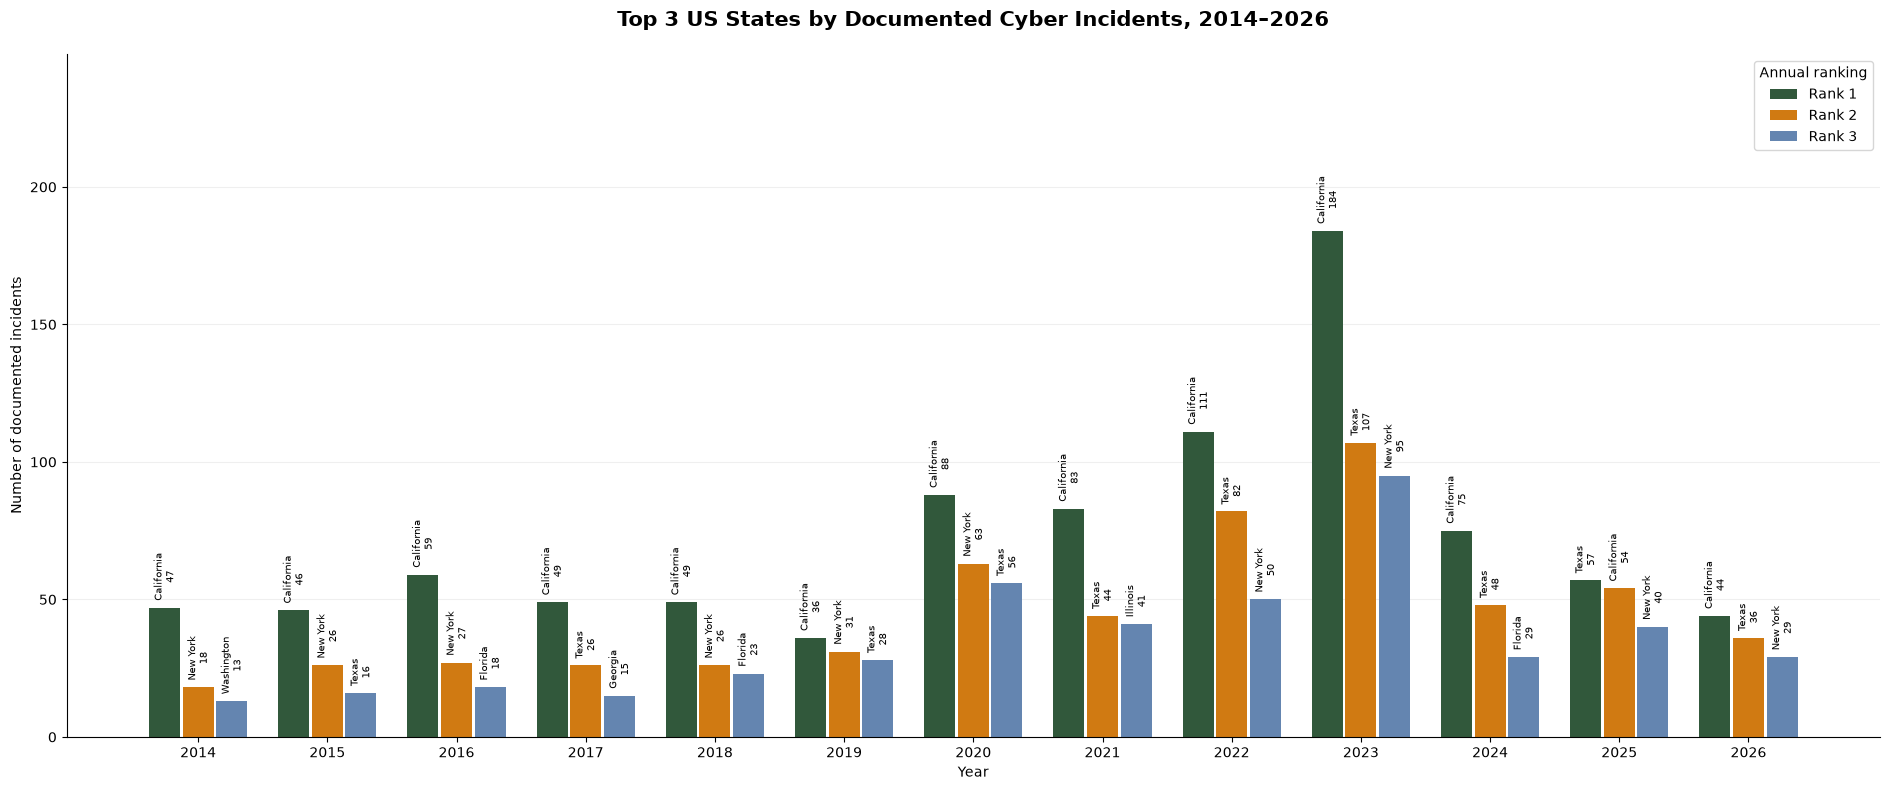

In [48]:
# Visualize the top three US states by incident count for each year
fig_usa_top3_states, ax_usa_top3_states = plt.subplots(
    figsize=(19, 8)
)

rank_colors = {
    1: "#31583b",
    2: "#d07a12",
    3: "#6485b0"
}

for rank in [1, 2, 3]:
    rank_data = usa_top3_states_by_year[
        usa_top3_states_by_year["Rank"] == rank
    ].sort_values("Year")

    positions = (
        np.arange(len(rank_data))
        + (rank - 2) * 0.26
    )

    bars = ax_usa_top3_states.bar(
        positions,
        rank_data["Incidents"],
        width=0.24,
        color=rank_colors[rank],
        label=f"Rank {rank}"
    )

    for bar, state, incidents in zip(
        bars, rank_data["State"], rank_data["Incidents"]
    ):
        ax_usa_top3_states.annotate(
            f"{state}\n{incidents}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90
        )

years = sorted(usa_top3_states_by_year["Year"].unique())

ax_usa_top3_states.set_xticks(np.arange(len(years)))
ax_usa_top3_states.set_xticklabels(years)

ax_usa_top3_states.set_title(
    "Top 3 US States by Documented Cyber Incidents, 2014–2026",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax_usa_top3_states.set_xlabel("Year")
ax_usa_top3_states.set_ylabel("Number of documented incidents")

ax_usa_top3_states.legend(title="Annual ranking")
ax_usa_top3_states.grid(axis="y", alpha=0.2)
ax_usa_top3_states.set_axisbelow(True)

ax_usa_top3_states.set_ylim(
    0,
    usa_top3_states_by_year["Incidents"].max() * 1.35
)

ax_usa_top3_states.spines["top"].set_visible(False)
ax_usa_top3_states.spines["right"].set_visible(False)

fig_usa_top3_states.tight_layout()
plt.show()

Observations and further investigation

California consistently appears among the states with the highest numbers of documented cyber incidents, ranking first in 12 of the 13 observed years. Its highest annual count occurs in 2023, with 184 documented incidents. Texas and New York are also frequently represented among the top three states.

Several factors may contribute to these patterns, including differences in population size, economic structure, geographical attribution, and incident reporting practices.

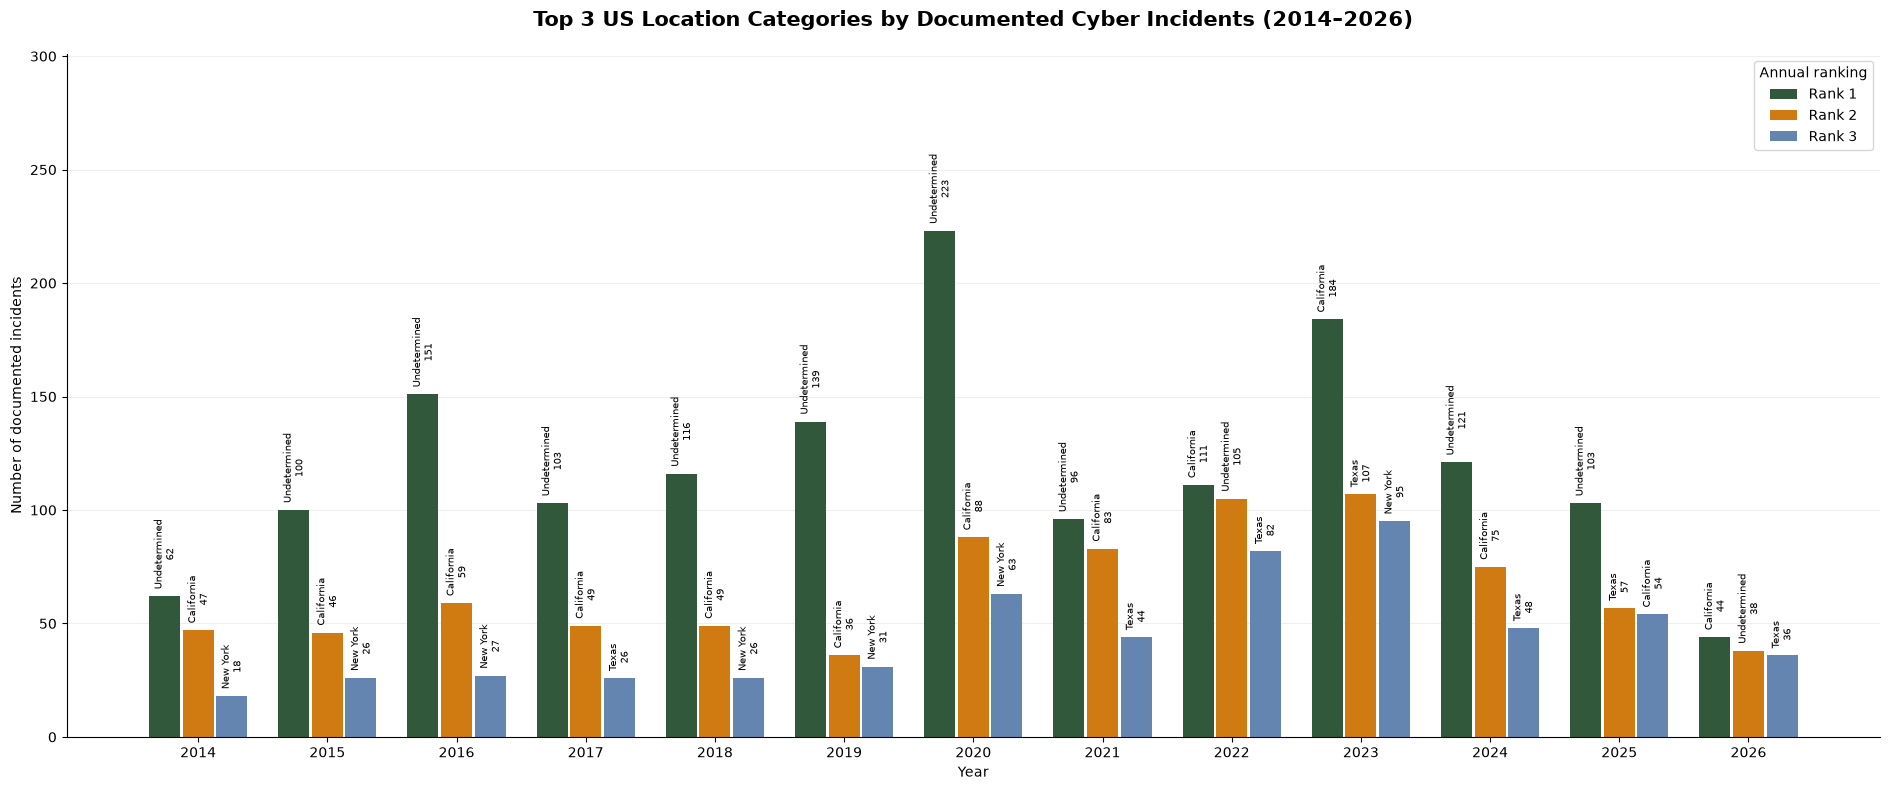

In [49]:
# Identify the top three location categories for every year
usa_top3_all_locations = (
    usa_state_annual_counts
    .drop(columns="Total")
    .stack()
    .reset_index(name="Incidents")
    .rename(columns={
        "state_label": "State",
        "year": "Year"
    })
    .sort_values(
        ["Year", "Incidents", "State"],
        ascending=[True, False, True]
    )
    .groupby("Year")
    .head(3)
    .copy()
)

usa_top3_all_locations["Rank"] = (
    usa_top3_all_locations.groupby("Year").cumcount() + 1
)

# Plot three bars per year
fig_usa_top3_all_locations, ax_usa_top3_all_locations = (
    plt.subplots(figsize=(19, 8))
)

rank_colors = {
    1: "#31583b",
    2: "#d07a12",
    3: "#6485b0"
}

years = sorted(usa_top3_all_locations["Year"].unique())

for rank in [1, 2, 3]:
    rank_data = (
        usa_top3_all_locations[
            usa_top3_all_locations["Rank"] == rank
        ]
        .sort_values("Year")
    )

    positions = np.arange(len(years)) + (rank - 2) * 0.26

    bars = ax_usa_top3_all_locations.bar(
        positions,
        rank_data["Incidents"],
        width=0.24,
        color=rank_colors[rank],
        label=f"Rank {rank}"
    )

    for bar, state, incidents in zip(
        bars, rank_data["State"], rank_data["Incidents"]
    ):
        ax_usa_top3_all_locations.annotate(
            f"{state}\n{incidents}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90
        )

ax_usa_top3_all_locations.set_xticks(np.arange(len(years)))
ax_usa_top3_all_locations.set_xticklabels(years)

ax_usa_top3_all_locations.set_title(
    "Top 3 US Location Categories by Documented Cyber Incidents (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax_usa_top3_all_locations.set_xlabel("Year")
ax_usa_top3_all_locations.set_ylabel("Number of documented incidents")

ax_usa_top3_all_locations.legend(title="Annual ranking")
ax_usa_top3_all_locations.grid(axis="y", alpha=0.2)
ax_usa_top3_all_locations.set_axisbelow(True)

ax_usa_top3_all_locations.set_ylim(
    0,
    usa_top3_all_locations["Incidents"].max() * 1.35
)

ax_usa_top3_all_locations.spines["top"].set_visible(False)
ax_usa_top3_all_locations.spines["right"].set_visible(False)

fig_usa_top3_all_locations.tight_layout()
plt.show()

In [50]:
# Map US state names to their postal abbreviations
usa_state_abbreviations = dict(zip(
    [
        "Alabama", "Alaska", "Arizona", "Arkansas", "California",
        "Colorado", "Connecticut", "Delaware", "Florida", "Georgia",
        "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa",
        "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland",
        "Massachusetts", "Michigan", "Minnesota", "Mississippi",
        "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
        "New Jersey", "New Mexico", "New York", "North Carolina",
        "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
        "Rhode Island", "South Carolina", "South Dakota", "Tennessee",
        "Texas", "Utah", "Vermont", "Virginia", "Washington",
        "West Virginia", "Wisconsin", "Wyoming"
    ],
    [
        "AL", "AK", "AZ", "AR", "CA",
        "CO", "CT", "DE", "FL", "GA",
        "HI", "ID", "IL", "IN", "IA",
        "KS", "KY", "LA", "ME", "MD",
        "MA", "MI", "MN", "MS",
        "MO", "MT", "NE", "NV", "NH",
        "NJ", "NM", "NY", "NC",
        "ND", "OH", "OK", "OR", "PA",
        "RI", "SC", "SD", "TN",
        "TX", "UT", "VT", "VA", "WA",
        "WV", "WI", "WY"
    ]
))

In [51]:
# Prepare state-year records for interactive mapping
usa_state_map_data = (
    usa_state_heatmap_counts
    .rename_axis("State")
    .reset_index()
    .melt(
        id_vars="State",
        var_name="Year",
        value_name="Incidents"
    )
)

usa_state_map_data["Code"] = (
    usa_state_map_data["State"]
    .map(usa_state_abbreviations)
)

usa_state_map_data["Year"] = (
    usa_state_map_data["Year"].astype(int)
)

assert usa_state_map_data["Code"].notna().all()

fig_usa_state_annual_map = px.choropleth(
    usa_state_map_data,
    locations="Code",
    locationmode="USA-states",
    scope="usa",
    color="Incidents",
    animation_frame="Year",
    hover_name="State",
    hover_data={
        "Code": False,
        "Year": True,
        "Incidents": True
    },
    color_continuous_scale="RdBu_r",
    range_color=(
        0,
        usa_state_map_data["Incidents"].max()
    ),
    labels={"Incidents": "Documented incidents"},
    title="Geographical Distribution of US Cyber Incidents (2014–2026)"
)

fig_usa_state_annual_map.update_geos(
    showlakes=False,
    showland=True
)

fig_usa_state_annual_map.update_layout(
    height=650,
    title_x=0.5,
    margin=dict(l=20, r=20, t=70, b=80),
    coloraxis_colorbar=dict(
        title="Incidents"
    )
)

fig_usa_state_annual_map.show()

### 4.4 State-level case studies

The geographical analysis identifies California, Texas, and New York as the three states with the highest overall numbers of documented cyber incidents. Their temporal distributions and incident characteristics will be examined in separate notebooks.

The case studies investigate economic sectors, affected organizations, incident types and subtypes, threat actors, and potential factors contributing to differences in documented incident counts.

**Detailed analyses:**
- [California](usa_states/01_california.ipynb)
- [Texas](usa_states/02_texas.ipynb)
- [New York](usa_states/03_new_york.ipynb)


## 5. Incident types and subtypes

This section examines the classification of documented cyber incidents in the United States, focusing on incident types, their subtypes, and changes in their distribution over time.

The analysis aims to identify dominant categories, differences in their frequency, and potential temporal patterns. Findings describe documented incidents rather than the actual prevalence of cyber threats.

### 5.1 Distribution of incident types


In [52]:
# Examine the distribution of documented incident types
usa_event_type_distribution = (
    usa_final["event_type"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("Incident type")
    .reset_index(name="Incidents")
)

usa_event_type_distribution["Share (%)"] = (
    usa_event_type_distribution["Incidents"]
    / len(usa_final)
    * 100
).round(2)

display(usa_event_type_distribution)

,Incident type,Incidents,Share (%)
0,Exploitive,4903,59.77
1,Disruptive,1776,21.65
2,Mixed,1446,17.63
3,Undetermined,78,0.95



### 5.2 Distribution of incident subtypes

In [53]:
# Examine the distribution of documented incident subtypes
usa_event_subtype_distribution = (
    usa_final["event_subtype"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("Incident subtype")
    .reset_index(name="Incidents")
)

usa_event_subtype_distribution["Share (%)"] = (
    usa_event_subtype_distribution["Incidents"]
    / len(usa_final) * 100
).round(2)

display(usa_event_subtype_distribution)

,Incident subtype,Incidents,Share (%)
0,Exploitation of Application Server,3505,42.73
1,Data Attack,1440,17.55
2,Exploitation of End Hosts,797,9.72
3,"Data Attack,Exploitation of Application Server",528,6.44
4,Undetermined,521,6.35
5,Message Manipulation,444,5.41
6,External Denial of Service,313,3.82
7,"Exploitation of Application Server,Exploitatio...",134,1.63
8,Exploitation of Sensors,132,1.61
9,Internal Denial of Service,76,0.93


In [54]:
# Split combined subtypes and count each subtype once per incident
usa_incident_subtypes = (
    usa_final[["slug", "event_subtype"]]
    .assign(
        subtype=lambda data: (
            data["event_subtype"]
            .fillna("Missing")
            .str.split(r"[,;]")
        )
    )
    .explode("subtype")
)

usa_incident_subtypes["subtype"] = (
    usa_incident_subtypes["subtype"].str.strip()
)

usa_incident_subtypes = (
    usa_incident_subtypes
    .loc[usa_incident_subtypes["subtype"].ne("")]
    .drop_duplicates(subset=["slug", "subtype"])
)

usa_subtype_incident_counts = (
    usa_incident_subtypes["subtype"]
    .value_counts()
    .rename_axis("Incident subtype")
    .reset_index(name="Incidents")
)

usa_subtype_incident_counts["Share of US incidents (%)"] = (
    usa_subtype_incident_counts["Incidents"]
    / len(usa_final) * 100
).round(2)

display(usa_subtype_incident_counts)

,Incident subtype,Incidents,Share of US incidents (%)
0,Exploitation of Application Server,4258,51.91
1,Data Attack,2079,25.34
2,Exploitation of End Hosts,973,11.86
3,Undetermined,555,6.77
4,Message Manipulation,507,6.18
5,External Denial of Service,388,4.73
6,Exploitation of Sensors,140,1.71
7,Internal Denial of Service,121,1.48
8,Exploitation of Network Infrastructure,41,0.50
9,Exploitation of Data in Transit,30,0.37


Data Preparation & Observations

Initial analysis of the event_subtype column showed 56 entries, many containing multi-value combinations. **To ensure accuracy, combined values were split into individual subtypes, counted at most once per incident, and recalculated.** This reduced the classification to **13** distinct subtypes.

Key Findings:
- Exploitation of Application Server: 4,258 incidents (51.91%)
- Data Attack: 2,079 incidents (25.34%)
- Exploitation of End Hosts: 973 incidents (11.86%)
- Minor naming inconsistencies (e.g., Server vs. Servers) remain.

Note: Percentages represent the proportion of incidents per subtype and do not sum to 100% due to multi-label incidents. Original data remains unchanged.

An additional naming inconsistency was identified between `Exploitation of Application Server` and `Exploitation of Application Servers`. These labels were consolidated into a single category, as they differ only in grammatical number. The less common `Exploitation of Network Server` label was retained separately pending further verification.


In [55]:
# Consolidate equivalent incident subtype labels
subtype_name_mapping = {
    "Exploitation of Application Servers": "Exploitation of Application Server"
}

usa_incident_subtypes["subtype"] = (
    usa_incident_subtypes["subtype"]
    .replace(subtype_name_mapping)
)

# Ensure each subtype is counted only once per incident
usa_incident_subtypes = (
    usa_incident_subtypes
    .drop_duplicates(subset=["slug", "subtype"])
)

# Recalculate subtype frequencies after consolidation
usa_subtype_incident_counts = (
    usa_incident_subtypes["subtype"]
    .value_counts()
    .rename_axis("Incident subtype")
    .reset_index(name="Incidents")
)

usa_subtype_incident_counts["Share of US incidents (%)"] = (
    usa_subtype_incident_counts["Incidents"]
    / len(usa_final) * 100
).round(2)

display(usa_subtype_incident_counts)

,Incident subtype,Incidents,Share of US incidents (%)
0,Exploitation of Application Server,4260,51.93
1,Data Attack,2079,25.34
2,Exploitation of End Hosts,973,11.86
3,Undetermined,555,6.77
4,Message Manipulation,507,6.18
5,External Denial of Service,388,4.73
6,Exploitation of Sensors,140,1.71
7,Internal Denial of Service,121,1.48
8,Exploitation of Network Infrastructure,41,0.50
9,Exploitation of Data in Transit,30,0.37


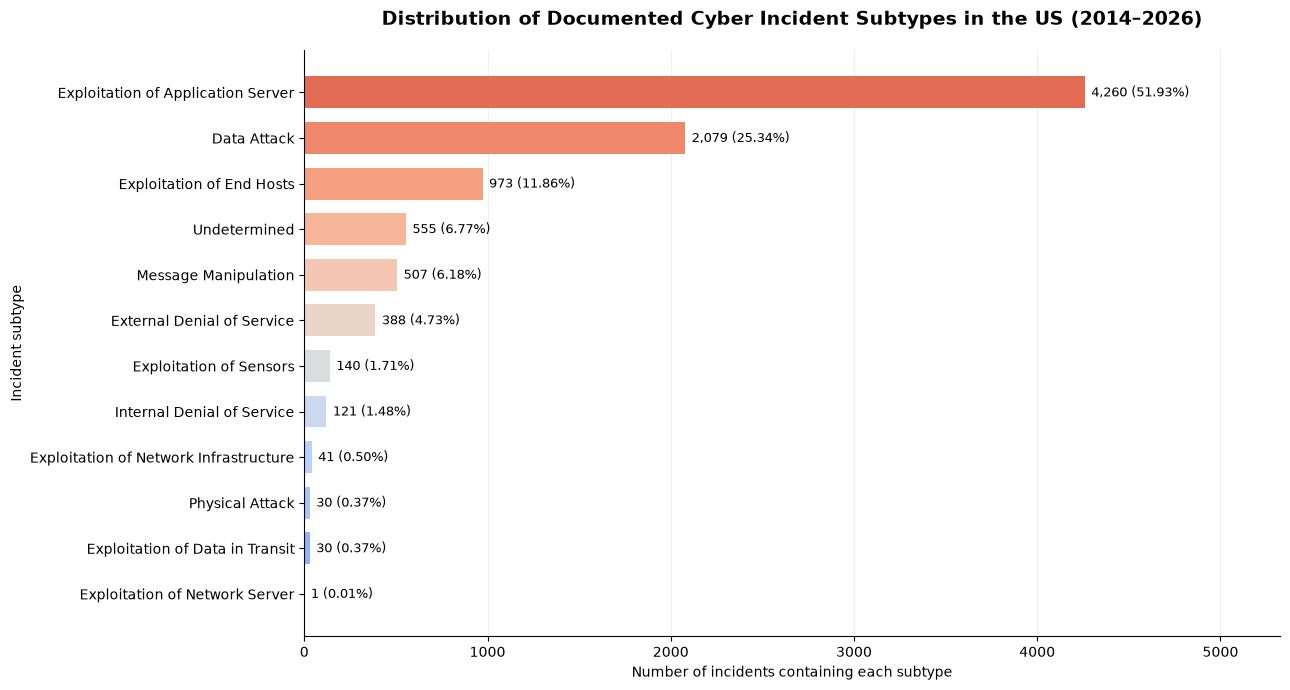

In [56]:
# Visualize the distribution of individual incident subtypes
usa_subtype_plot_data = (
    usa_subtype_incident_counts
    .sort_values("Incidents", ascending=True)
)

fig_usa_subtype_distribution, ax_usa_subtype_distribution = (
    plt.subplots(figsize=(13, 7))
)

bars_usa_subtypes = ax_usa_subtype_distribution.barh(
    usa_subtype_plot_data["Incident subtype"],
    usa_subtype_plot_data["Incidents"],
    color=plt.cm.coolwarm(
        np.linspace(0.2, 0.85, len(usa_subtype_plot_data))
    ),
    height=0.7
)

for bar, incidents, share in zip(
    bars_usa_subtypes,
    usa_subtype_plot_data["Incidents"],
    usa_subtype_plot_data["Share of US incidents (%)"]
):
    ax_usa_subtype_distribution.text(
        bar.get_width() + 35,
        bar.get_y() + bar.get_height() / 2,
        f"{incidents:,} ({share:.2f}%)",
        ha="left",
        va="center",
        fontsize=9
    )

ax_usa_subtype_distribution.set_title(
    "Distribution of Documented Cyber Incident Subtypes in the US (2014–2026)",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax_usa_subtype_distribution.set_xlabel(
    "Number of incidents containing each subtype"
)
ax_usa_subtype_distribution.set_ylabel("Incident subtype")

ax_usa_subtype_distribution.set_xlim(
    0,
    usa_subtype_plot_data["Incidents"].max() * 1.25
)

ax_usa_subtype_distribution.grid(axis="x", alpha=0.2)
ax_usa_subtype_distribution.set_axisbelow(True)

ax_usa_subtype_distribution.spines["top"].set_visible(False)
ax_usa_subtype_distribution.spines["right"].set_visible(False)

fig_usa_subtype_distribution.tight_layout()
plt.show()

### 5.3 Relationships between incident types and subtypes

This analysis examines how individual incident subtypes are distributed across the four main incident types. Since incidents may contain multiple subtypes, the relationships are analyzed using distinct incident–subtype associations rather than assuming that each incident belongs to exactly one subtype.

In [57]:
# Count distinct incident–subtype associations by main incident type
usa_type_subtype_data = (
    usa_incident_subtypes[["slug", "subtype"]]
    .merge(
        usa_final[["slug", "event_type"]],
        on="slug",
        how="left",
        validate="many_to_one"
    )
)

usa_type_subtype_counts = (
    usa_type_subtype_data
    .groupby(["event_type", "subtype"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=["Exploitive", "Disruptive", "Mixed", "Undetermined"],
        fill_value=0
    )
)

display(usa_type_subtype_counts)

subtype,Data Attack,Exploitation of Application Server,Exploitation of Data in Transit,Exploitation of End Hosts,Exploitation of Network Infrastructure,Exploitation of Network Server,Exploitation of Sensors,External Denial of Service,Internal Denial of Service,Message Manipulation,Physical Attack,Undetermined
event_type,,,,,,,,,,,,
Exploitive,1,3521,28,937,38,1,140,0,0,0,0,393
Disruptive,864,5,0,1,0,0,0,372,93,448,27,42
Mixed,1214,734,2,35,3,0,0,16,28,59,3,42
Undetermined,0,0,0,0,0,0,0,0,0,0,0,78


### 5.3 Relationships between incident types and subtypes


In [58]:
# Convert the type–subtype matrix into Sankey links
usa_sankey_links = (
    usa_type_subtype_counts
    .stack()
    .reset_index(name="Incidents")
    .query("Incidents > 0")
)

usa_sankey_types = list(usa_type_subtype_counts.index)
usa_sankey_subtypes = list(usa_type_subtype_counts.columns)

usa_sankey_nodes = (
    usa_sankey_types + usa_sankey_subtypes
)

usa_sankey_node_ids = {
    name: i for i, name in enumerate(usa_sankey_nodes)
}

usa_sankey_colors = {
    "Exploitive": "#4C78A8",
    "Disruptive": "#E28B52",
    "Mixed": "#8274BD",
    "Undetermined": "#8C8C8C"
}

usa_sankey_link_colors = {
    "Exploitive": "rgba(76, 120, 168, 0.35)",
    "Disruptive": "rgba(226, 139, 82, 0.35)",
    "Mixed": "rgba(130, 116, 189, 0.35)",
    "Undetermined": "rgba(140, 140, 140, 0.35)"
}

fig_usa_type_subtype_sankey = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=18,
                thickness=18,
                line=dict(color="white", width=0.8),
                label=usa_sankey_nodes,
                color=(
                    [usa_sankey_colors[t] for t in usa_sankey_types]
                    + ["#A8B5C6"] * len(usa_sankey_subtypes)
                ),
                hovertemplate="%{label}<extra></extra>"
            ),
            link=dict(
                source=[
                    usa_sankey_node_ids[t]
                    for t in usa_sankey_links["event_type"]
                ],
                target=[
                    usa_sankey_node_ids[s]
                    for s in usa_sankey_links["subtype"]
                ],
                value=usa_sankey_links["Incidents"],
                color=[
                    usa_sankey_link_colors[t]
                    for t in usa_sankey_links["event_type"]
                ],
                customdata=usa_sankey_links[
                    ["event_type", "subtype"]
                ].to_numpy(),
                hovertemplate=(
                    "%{customdata[0]} → %{customdata[1]}"
                    "<br>Incident–subtype associations: %{value:,}"
                    "<extra></extra>"
                )
            )
        )
    ]
)

fig_usa_type_subtype_sankey.update_layout(
    title=dict(
        text="US Cyber Incidents: Types and Subtypes (2014–2026)",
        x=0.5
    ),
    font=dict(size=11),
    height=750,
    width=1250,
    margin=dict(l=30, r=260, t=85, b=30),
    paper_bgcolor="white"
)

fig_usa_type_subtype_sankey.show()

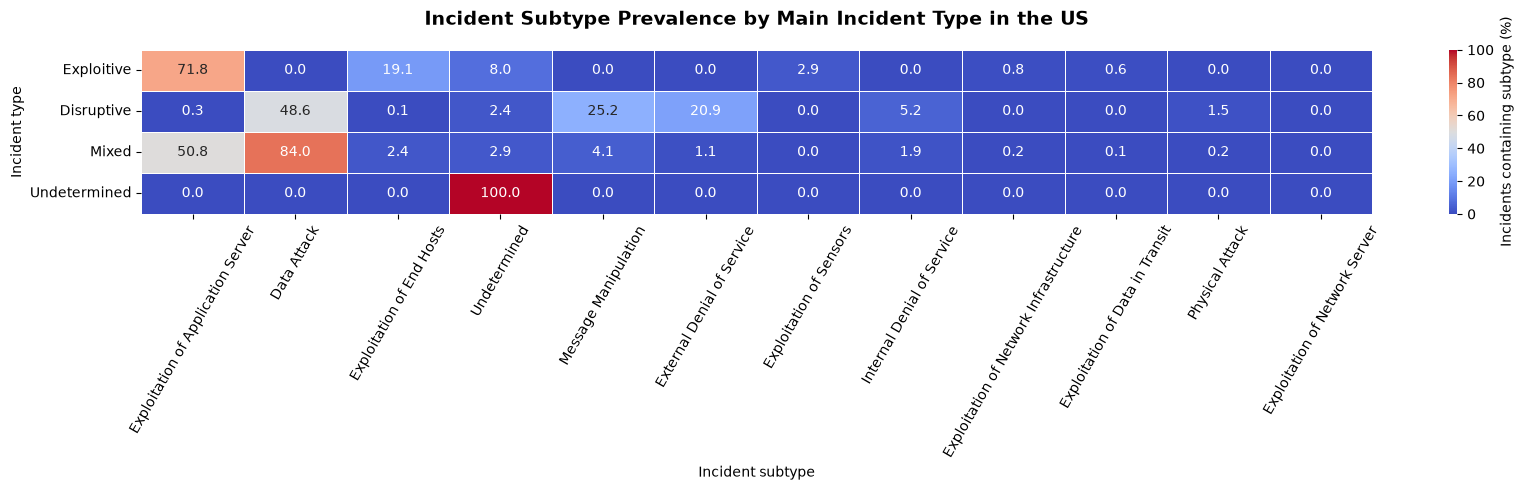

In [59]:
# Calculate subtype prevalence within each main incident type
usa_type_subtype_shares = (
    usa_type_subtype_counts
    .div(
        usa_final["event_type"].value_counts()
        .reindex(usa_type_subtype_counts.index),
        axis=0
    )
    .mul(100)
)

# Order subtypes by overall frequency
usa_type_subtype_shares = usa_type_subtype_shares[
    usa_subtype_incident_counts["Incident subtype"]
]

fig_usa_type_subtype_heatmap, ax_usa_type_subtype_heatmap = (
    plt.subplots(figsize=(17, 5))
)

sns.heatmap(
    usa_type_subtype_shares,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Incidents containing subtype (%)"},
    ax=ax_usa_type_subtype_heatmap
)

ax_usa_type_subtype_heatmap.set_title(
    "Incident Subtype Prevalence by Main Incident Type in the US",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax_usa_type_subtype_heatmap.set_xlabel("Incident subtype")
ax_usa_type_subtype_heatmap.set_ylabel("Incident type")
ax_usa_type_subtype_heatmap.tick_params(axis="x", rotation=60)
ax_usa_type_subtype_heatmap.tick_params(axis="y", rotation=0)

fig_usa_type_subtype_heatmap.tight_layout()
plt.show()

### 5.4 Changes in incident types and subtypes over time

In [60]:
# Count incidents by year and main incident type
usa_type_annual_counts = (
    usa_final
    .groupby(["year", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(2014, 2027), fill_value=0)
)

usa_type_annual_shares = (
    usa_type_annual_counts
    .div(usa_type_annual_counts.sum(axis=1), axis=0)
    .mul(100)
)

display(usa_type_annual_shares.round(2))

event_type,Disruptive,Exploitive,Mixed,Undetermined
year,,,,
2014,26.15,72.08,1.77,0.00
2015,31.05,67.37,1.58,0.00
2016,28.51,68.42,3.07,0.00
2017,34.15,61.48,4.37,0.00
2018,24.22,73.11,2.67,0.00
2019,42.71,54.92,2.37,0.00
2020,32.90,49.41,17.69,0.00
2021,19.20,46.27,32.73,1.80
2022,14.90,52.30,30.65,2.14


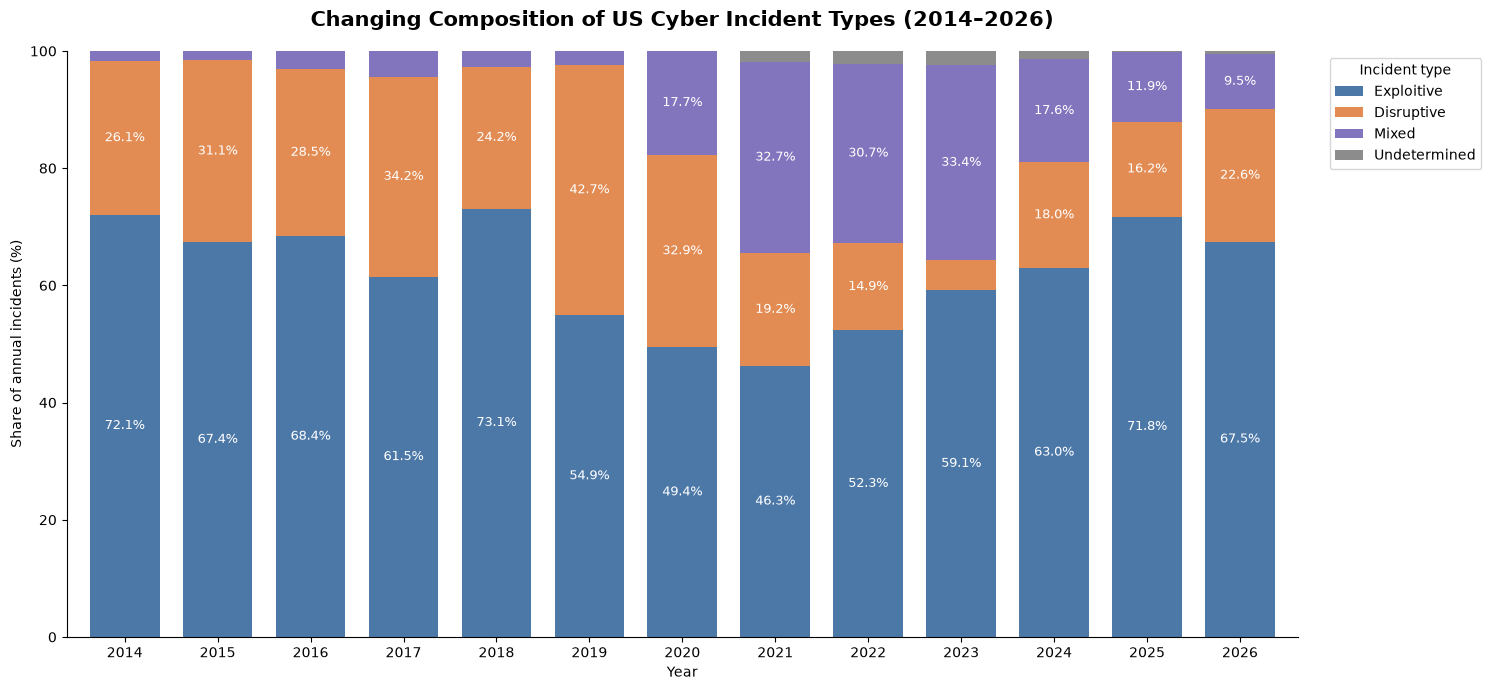

In [61]:
# Visualize annual changes in the distribution of incident types
usa_type_plot_data = usa_type_annual_shares[
    ["Exploitive", "Disruptive", "Mixed", "Undetermined"]
]

usa_type_colors = {
    "Exploitive": "#4C78A8",
    "Disruptive": "#E28B52",
    "Mixed": "#8274BD",
    "Undetermined": "#8C8C8C"
}

fig_usa_type_annual_shares, ax_usa_type_annual_shares = (
    plt.subplots(figsize=(15, 7))
)

usa_type_plot_data.plot(
    kind="bar",
    stacked=True,
    color=[
        usa_type_colors[col]
        for col in usa_type_plot_data.columns
    ],
    width=0.75,
    ax=ax_usa_type_annual_shares
)

# Label sufficiently large segments
for container in ax_usa_type_annual_shares.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 7 else ""
        for bar in container
    ]

    ax_usa_type_annual_shares.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="white"
    )

ax_usa_type_annual_shares.set_title(
    "Changing Composition of US Cyber Incident Types (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_type_annual_shares.set_xlabel("Year")
ax_usa_type_annual_shares.set_ylabel("Share of annual incidents (%)")
ax_usa_type_annual_shares.set_ylim(0, 100)

ax_usa_type_annual_shares.tick_params(
    axis="x", rotation=0
)

ax_usa_type_annual_shares.legend(
    title="Incident type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax_usa_type_annual_shares.spines["top"].set_visible(False)
ax_usa_type_annual_shares.spines["right"].set_visible(False)

fig_usa_type_annual_shares.tight_layout()
plt.show()

In [62]:
# Attach event years to the consolidated incident-subtype data
usa_subtype_annual_data = (
    usa_incident_subtypes[["slug", "subtype"]]
    .merge(
        usa_final[["slug", "year"]],
        on="slug",
        how="left",
        validate="many_to_one"
    )
)

# Count incidents containing each subtype by year
usa_subtype_annual_counts = (
    usa_subtype_annual_data
    .groupby(["subtype", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(2014, 2027), fill_value=0)
)

# Calculate subtype prevalence among all incidents in each year
usa_subtype_annual_shares = (
    usa_subtype_annual_counts
    .div(
        usa_final["year"].value_counts(),
        axis=1
    )
    .mul(100)
)

display(usa_subtype_annual_shares.round(2))

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
subtype,,,,,,,,,,,,,
Data Attack,1.41,1.58,1.54,20.22,16.67,36.27,35.17,44.48,38.69,25.43,24.53,18.73,14.08
Exploitation of Application Server,57.60,56.32,57.89,49.18,59.56,32.03,59.87,51.38,30.87,47.19,61.71,73.72,56.80
Exploitation of Data in Transit,0.35,0.26,0.44,0.82,2.22,0.00,0.22,0.41,0.11,0.14,0.00,0.15,0.97
Exploitation of End Hosts,7.77,6.84,13.16,14.48,20.22,28.47,9.06,14.78,15.65,6.41,9.81,5.44,7.04
Exploitation of Network Infrastructure,0.35,0.26,0.88,0.00,0.00,0.51,0.43,1.24,0.43,0.29,0.95,0.45,0.49
Exploitation of Network Server,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.07,0.00,0.00,0.00
Exploitation of Sensors,9.54,6.58,4.61,4.37,2.44,3.39,0.76,0.97,0.32,0.07,0.00,0.30,0.00
External Denial of Service,13.43,10.00,14.04,3.83,4.67,4.92,7.98,2.49,4.61,1.15,1.90,1.96,1.94
Internal Denial of Service,0.35,0.79,0.88,1.91,1.11,1.69,1.08,0.28,0.00,0.86,1.27,3.93,8.01


In [63]:
import plotly.graph_objects as go

# Visualize changes in annual subtype prevalence
usa_subtype_trend_data = usa_subtype_annual_shares.T

top_subtypes = (
    usa_subtype_incident_counts
    .head(4)["Incident subtype"]
    .tolist()
)

fig_usa_subtype_trends = go.Figure()

for subtype in usa_subtype_incident_counts["Incident subtype"]:

    fig_usa_subtype_trends.add_trace(
        go.Scatter(
            x=usa_subtype_trend_data.index,
            y=usa_subtype_trend_data[subtype],
            mode="lines+markers",
            name=subtype,
            visible=True if subtype in top_subtypes else "legendonly",
            line=dict(width=2.8),
            marker=dict(size=7),
            hovertemplate=(
                "<b>%{fullData.name}</b>"
                "<br>Year: %{x}"
                "<br>Share: %{y:.2f}%"
                "<extra></extra>"
            )
        )
    )

fig_usa_subtype_trends.update_layout(
    title=dict(
        text="Temporal Changes in US Cyber Incident Subtypes (2014–2026)",
        x=0.5
    ),
    xaxis=dict(
        title="Year",
        tickmode="linear",
        dtick=1
    ),
    yaxis=dict(
        title="Share of annual incidents (%)",
        rangemode="tozero",
        ticksuffix="%"
    ),
    legend=dict(
        title="Incident subtype",
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top"
    ),
    hovermode="x unified",
    height=650,
    width=1200,
    margin=dict(l=65, r=310, t=85, b=65),
    template="plotly_white"
)

fig_usa_subtype_trends.show()

**Incident classification reference**

The UMD Cyber Events Database distinguishes between *Exploitive*, *Disruptive*, *Mixed*, and *Undetermined* incident types. Individual incidents may be associated with multiple subtypes.

Detailed definitions, interpretations, and examples of each category are documented separately.

- [Incident types and subtypes — interpretation](../../docs/incident_types_and_subtypes.md)
- [UMD Cyber Events Database Codebook (March 2026)](../../docs/codebooks/Cyber%20Events%20Database%20Codebook_March%202026.pdf)

In [64]:
# Investigate ransomware mentions among Data Attack incidents
usa_data_attack_slugs = set(
    usa_incident_subtypes.loc[
        usa_incident_subtypes["subtype"] == "Data Attack",
        "slug"
    ]
)

usa_data_attack_details = (
    usa_final.loc[
        usa_final["slug"].isin(usa_data_attack_slugs)
    ].copy()
)

usa_data_attack_details["Ransomware mentioned"] = (
    usa_data_attack_details["description"]
    .fillna("")
    .str.contains(r"ransomware|ransom-ware", case=False, regex=True)
)

usa_data_attack_ransomware = (
    usa_data_attack_details
    .groupby("year")["Ransomware mentioned"]
    .agg(
        Incidents="size",
        Ransomware_mentions="sum"
    )
)

usa_data_attack_ransomware["Mention share (%)"] = (
    usa_data_attack_ransomware["Ransomware_mentions"]
    / usa_data_attack_ransomware["Incidents"] * 100
).round(2)

display(usa_data_attack_ransomware)

,Incidents,Ransomware_mentions,Mention share (%)
year,,,
2014,4,0,0.00
2015,6,0,0.00
2016,7,3,42.86
2017,74,53,71.62
2018,75,58,77.33
2019,214,198,92.52
2020,326,268,82.21
2021,322,257,79.81
2022,361,215,59.56


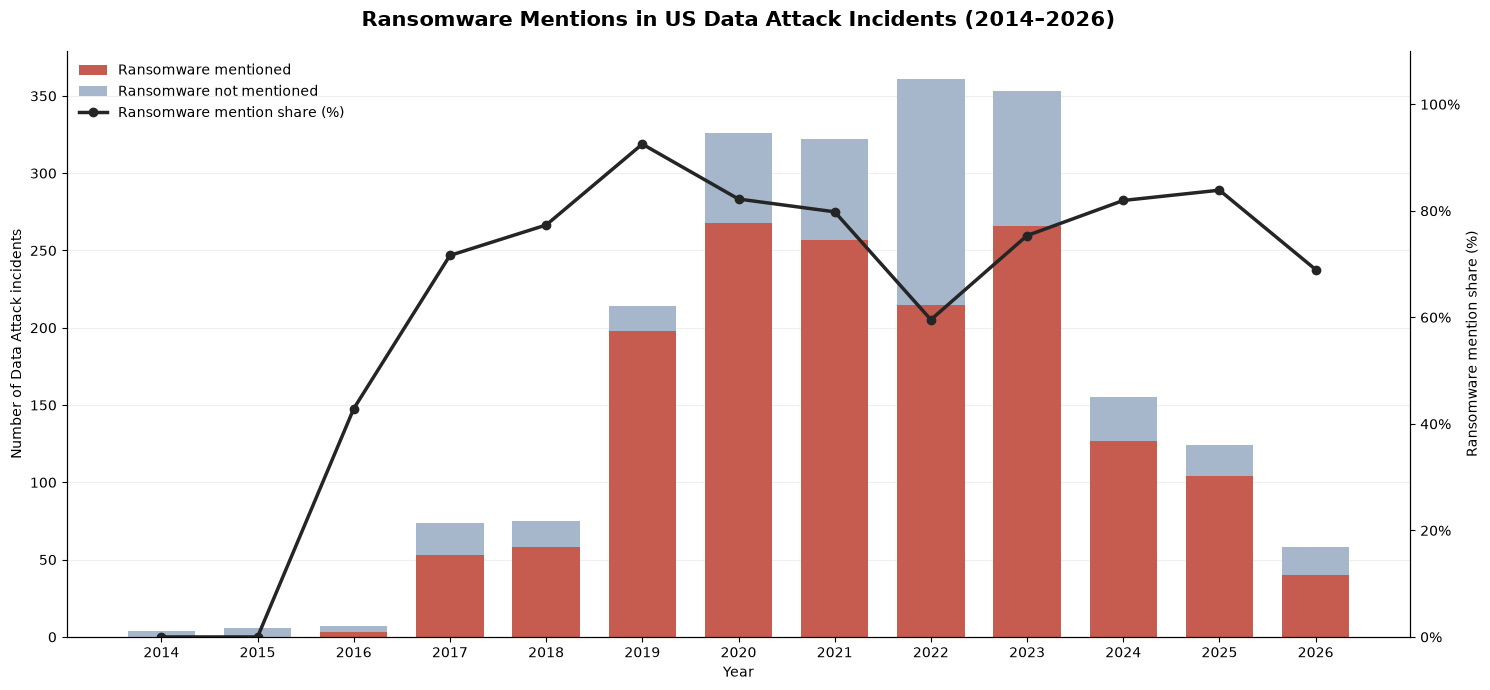

In [65]:
# Visualize ransomware mentions among Data Attack incidents
usa_ransomware_plot_data = usa_data_attack_ransomware.copy()

usa_ransomware_plot_data["Other incidents"] = (
    usa_ransomware_plot_data["Incidents"]
    - usa_ransomware_plot_data["Ransomware_mentions"]
)

fig_usa_ransomware_trends, ax_usa_ransomware_counts = (
    plt.subplots(figsize=(15, 7))
)

years = usa_ransomware_plot_data.index.to_numpy()

bars_ransomware = ax_usa_ransomware_counts.bar(
    years,
    usa_ransomware_plot_data["Ransomware_mentions"],
    color="#c65b50",
    width=0.7,
    label="Ransomware mentioned"
)

bars_other = ax_usa_ransomware_counts.bar(
    years,
    usa_ransomware_plot_data["Other incidents"],
    bottom=usa_ransomware_plot_data["Ransomware_mentions"],
    color="#a6b7cb",
    width=0.7,
    label="Ransomware not mentioned"
)

ax_usa_ransomware_share = ax_usa_ransomware_counts.twinx()

line_ransomware_share, = ax_usa_ransomware_share.plot(
    years,
    usa_ransomware_plot_data["Mention share (%)"],
    color="#252525",
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="Ransomware mention share (%)"
)

ax_usa_ransomware_counts.set_title(
    "Ransomware Mentions in US Data Attack Incidents (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_ransomware_counts.set_xlabel("Year")
ax_usa_ransomware_counts.set_ylabel("Number of Data Attack incidents")
ax_usa_ransomware_share.set_ylabel("Ransomware mention share (%)")

ax_usa_ransomware_counts.set_xticks(years)
ax_usa_ransomware_share.set_ylim(0, 110)
ax_usa_ransomware_share.set_yticks(range(0, 101, 20))
ax_usa_ransomware_share.set_yticklabels(
    [f"{value}%" for value in range(0, 101, 20)]
)

ax_usa_ransomware_counts.grid(axis="y", alpha=0.2)
ax_usa_ransomware_counts.set_axisbelow(True)

handles = [
    bars_ransomware,
    bars_other,
    line_ransomware_share
]

ax_usa_ransomware_counts.legend(
    handles=handles,
    loc="upper left",
    frameon=False
)

ax_usa_ransomware_counts.spines["top"].set_visible(False)
ax_usa_ransomware_share.spines["top"].set_visible(False)

fig_usa_ransomware_trends.tight_layout()
plt.show()

### Observations and external context

The proportion of *Data Attack* incidents explicitly mentioning ransomware is particularly high between 2017 and 2025, reaching 92.5% in 2019.

This suggests that ransomware-related incidents may contribute substantially to the observed temporal distribution of the Data Attack subtype.

Official US reporting provides additional context:

- **FBI IC3:** Ransomware complaints increased from 2,825 in 2023 to 3,611 in 2025.
- **US intelligence reporting:** Documented ransomware activity increased substantially between 2020 and 2022, with variation between individual years.
- **CISA:** Remote work, remote education, vulnerability exploitation, and ransomware-as-a-service have been identified as relevant factors in ransomware activity.

**Interpretation:** The UMD results are consistent with ransomware being an important component of documented Data Attack incidents. However, the datasets differ in coverage, classification, and reporting methodology. Therefore, similarities or differences in trends should not be interpreted as direct evidence of causation.

**Further research:** Examine ransomware-related incidents across economic sectors and affected organizations, particularly during 2019–2023.

**External references:**

- [FBI IC3 — 2025 Annual Report](https://www.ic3.gov/AnnualReport/Reports/2025_IC3Report.pdf)
- [US Intelligence — Ransomware Attacks, 2020–2022](https://www.dni.gov/files/CTIIC/documents/products/Ransomware_Attacks_in_the_US_and_the_Rest_of_the_World__January_2020_December_2022.pdf)
- [CISA — 2021 Ransomware Trends](https://www.cisa.gov/sites/default/files/publications/AA22-040A_2021_Trends_Show_Increased_Globalized_Threat_of_Ransomware_508.pdf)

## 6. Targeted economic sectors

This section examines how documented cyber incident characteristics differ across economic sectors in the United States.

The analysis builds on the sectoral distributions presented earlier and focuses on differences in incident types, subtypes, and ransomware-related activity.

### 6.1 Incident types across economic sectors



In [66]:
# Examine incident type composition within each economic sector
usa_sector_type_counts = (
    usa_final
    .groupby(["industry", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Exploitive", "Disruptive", "Mixed", "Undetermined"],
        fill_value=0
    )
)

usa_sector_type_shares = (
    usa_sector_type_counts
    .div(usa_sector_type_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Sort sectors by their total number of documented incidents
usa_sector_type_shares = usa_sector_type_shares.loc[
    usa_sector_type_counts.sum(axis=1).sort_values(ascending=False).index
]

display(usa_sector_type_shares.round(2))

event_type,Exploitive,Disruptive,Mixed,Undetermined
industry,,,,
Health Care and Social Assistance,65.70,12.52,20.88,0.89
Public Administration,43.17,39.85,14.85,2.12
Educational Services,46.12,32.15,20.16,1.57
"Professional, Scientific, and Technical Services",67.28,10.78,21.42,0.53
Information,60.19,30.92,8.89,0.00
Finance and Insurance,78.33,6.19,15.02,0.46
Other Services (except Public Administration),59.38,32.90,7.46,0.26
Manufacturing,48.60,13.13,36.59,1.68
Retail Trade,78.08,7.69,14.23,0.00


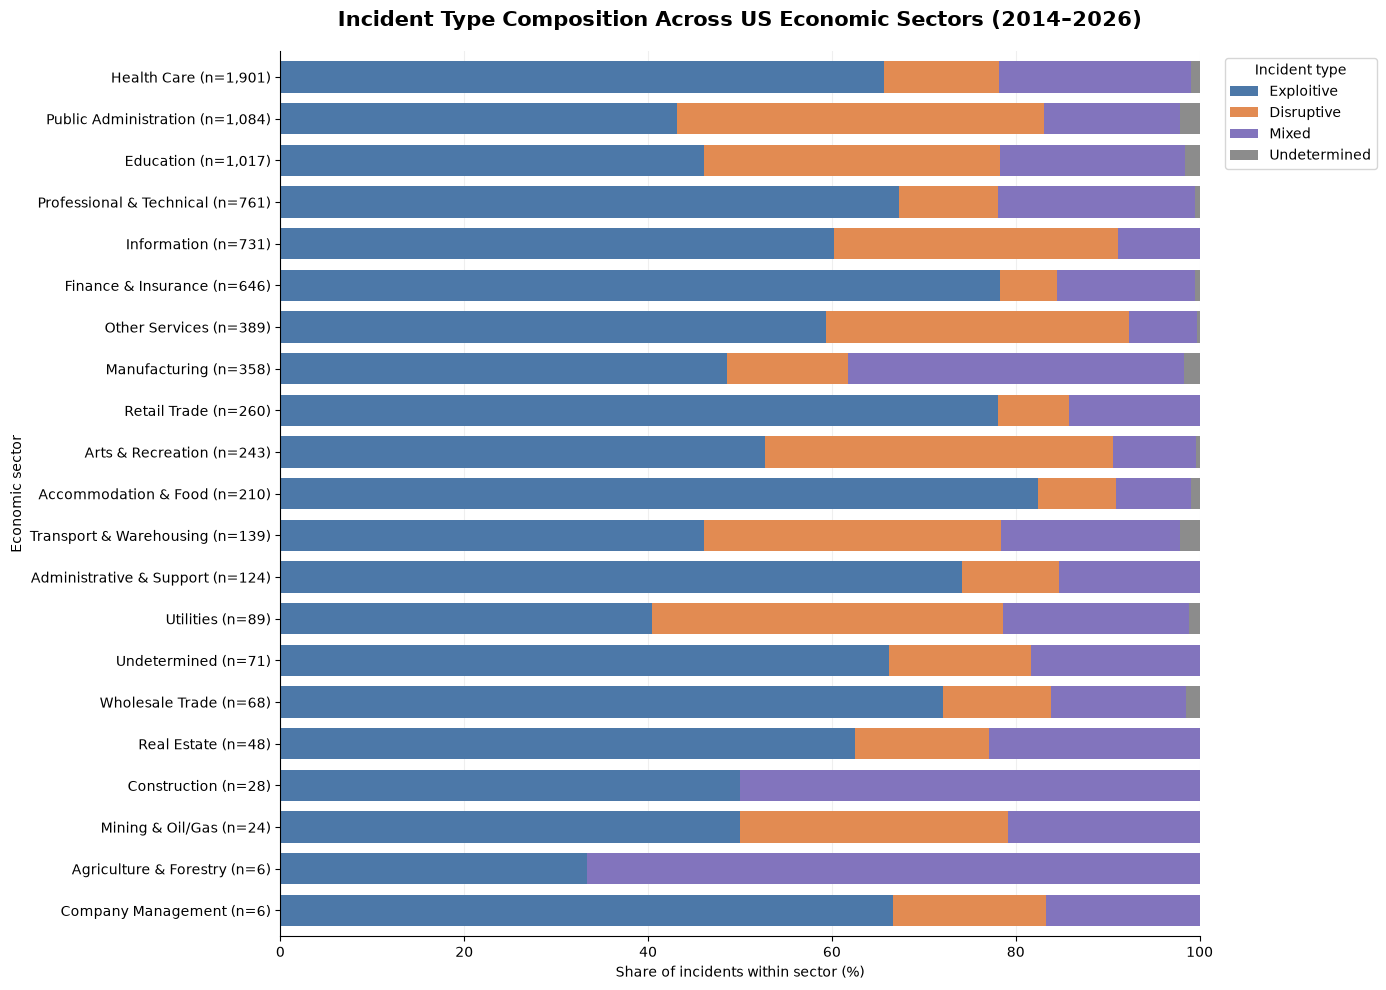

In [67]:
# Compare incident-type composition across economic sectors

# Add sector sample sizes to the chart labels
usa_sector_sample_sizes = usa_sector_type_counts.sum(axis=1)

usa_sector_type_plot_data = usa_sector_type_shares.copy()

usa_sector_type_plot_data.index = [
    f"{sector_display_names.get(sector, sector)} (n={usa_sector_sample_sizes[sector]:,})"
    for sector in usa_sector_type_plot_data.index
]

fig_usa_sector_type_composition, ax_usa_sector_type_composition = (
    plt.subplots(figsize=(14, 10))
)

usa_sector_type_plot_data.plot(
    kind="barh",
    stacked=True,
    color=[
        "#4C78A8",
        "#E28B52",
        "#8274BD",
        "#8C8C8C"
    ],
    width=0.75,
    ax=ax_usa_sector_type_composition
)

ax_usa_sector_type_composition.invert_yaxis()

ax_usa_sector_type_composition.set_title(
    "Incident Type Composition Across US Economic Sectors (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_sector_type_composition.set_xlabel(
    "Share of incidents within sector (%)"
)
ax_usa_sector_type_composition.set_ylabel("Economic sector")
ax_usa_sector_type_composition.set_xlim(0, 100)

ax_usa_sector_type_composition.legend(
    title="Incident type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax_usa_sector_type_composition.grid(axis="x", alpha=0.2)
ax_usa_sector_type_composition.set_axisbelow(True)

ax_usa_sector_type_composition.spines["top"].set_visible(False)
ax_usa_sector_type_composition.spines["right"].set_visible(False)

fig_usa_sector_type_composition.tight_layout()
plt.show()

### Observations

The composition of documented incident types varies considerably across economic sectors.

- **Finance and Insurance** has a particularly high proportion of Exploitive incidents (78.3%).
- **Public Administration** shows a relatively balanced distribution of Exploitive (43.2%) and Disruptive (39.9%) incidents.
- **Educational Services** has substantial proportions of Disruptive (32.2%) and Mixed (20.2%) incidents.
- **Manufacturing** stands out for its relatively high proportion of Mixed incidents (36.6%).
- **Health Care and Social Assistance**, the sector with the largest number of documented incidents, is predominantly associated with Exploitive incidents (65.7%).

These differences raise questions about sector-specific incident characteristics, including the possible roles of ransomware, data theft, and operational disruption.

The chart includes sector sample sizes (`n`). Percentages for sectors with few documented incidents should be interpreted cautiously.

#### 6.4.1 Incident subtypes across economic sectors

The distribution of incident subtypes is examined across economic sectors to identify differences in documented incident characteristics.

Subtype prevalence is calculated within each sector, allowing comparisons between sectors with different numbers of documented incidents. Since a single incident may contain multiple subtypes, the percentages are not mutually exclusive.

In [68]:
# Connect consolidated incident subtypes with economic sectors
usa_sector_subtype_data = (
    usa_incident_subtypes[["slug", "subtype"]]
    .merge(
        usa_final[["slug", "industry"]],
        on="slug",
        how="left",
        validate="many_to_one"
    )
)

# Count incidents containing each subtype within each sector
usa_sector_subtype_counts = (
    usa_sector_subtype_data
    .groupby(["industry", "subtype"])
    .size()
    .unstack(fill_value=0)
)

# Use the total number of incidents in each sector as denominator
usa_sector_sizes = usa_final["industry"].value_counts()

usa_sector_subtype_shares = (
    usa_sector_subtype_counts
    .div(usa_sector_sizes, axis=0)
    .mul(100)
)

# Order sectors and subtypes by their overall frequency
usa_sector_subtype_shares = (
    usa_sector_subtype_shares
    .reindex(index=usa_sector_sizes.index)
    .reindex(
        columns=usa_subtype_incident_counts["Incident subtype"],
        fill_value=0
    )
)

display(usa_sector_subtype_shares.round(2))

Incident subtype,Exploitation of Application Server,Data Attack,Exploitation of End Hosts,Undetermined,Message Manipulation,External Denial of Service,Exploitation of Sensors,Internal Denial of Service,Exploitation of Network Infrastructure,Exploitation of Data in Transit,Physical Attack,Exploitation of Network Server
industry,,,,,,,,,,,,
Health Care and Social Assistance,57.23,28.93,15.52,8.31,0.68,0.63,0.05,0.84,0.32,0.11,0.05,0.05
Public Administration,38.28,33.12,11.07,6.64,9.59,8.30,0.09,3.14,0.65,0.00,0.37,0.00
Educational Services,46.71,34.51,9.93,5.90,8.36,5.41,0.10,3.05,0.20,0.10,0.20,0.00
"Professional, Scientific, and Technical Services",62.42,25.49,9.72,7.62,2.10,1.84,0.39,0.39,1.18,0.26,0.00,0.00
Information,53.76,10.94,10.26,2.33,11.63,15.05,0.14,1.64,1.09,0.68,0.14,0.00
Finance and Insurance,62.23,14.55,13.31,10.84,2.17,2.48,1.08,0.31,0.15,0.93,0.31,0.00
Other Services (except Public Administration),46.02,10.03,17.99,2.06,21.59,8.74,1.80,0.26,0.00,1.03,0.00,0.00
Manufacturing,49.72,41.06,7.26,7.54,1.68,1.96,0.28,2.51,0.00,0.00,0.28,0.00
Retail Trade,56.15,15.77,16.15,5.38,2.31,2.31,10.00,1.15,0.38,0.38,0.00,0.00


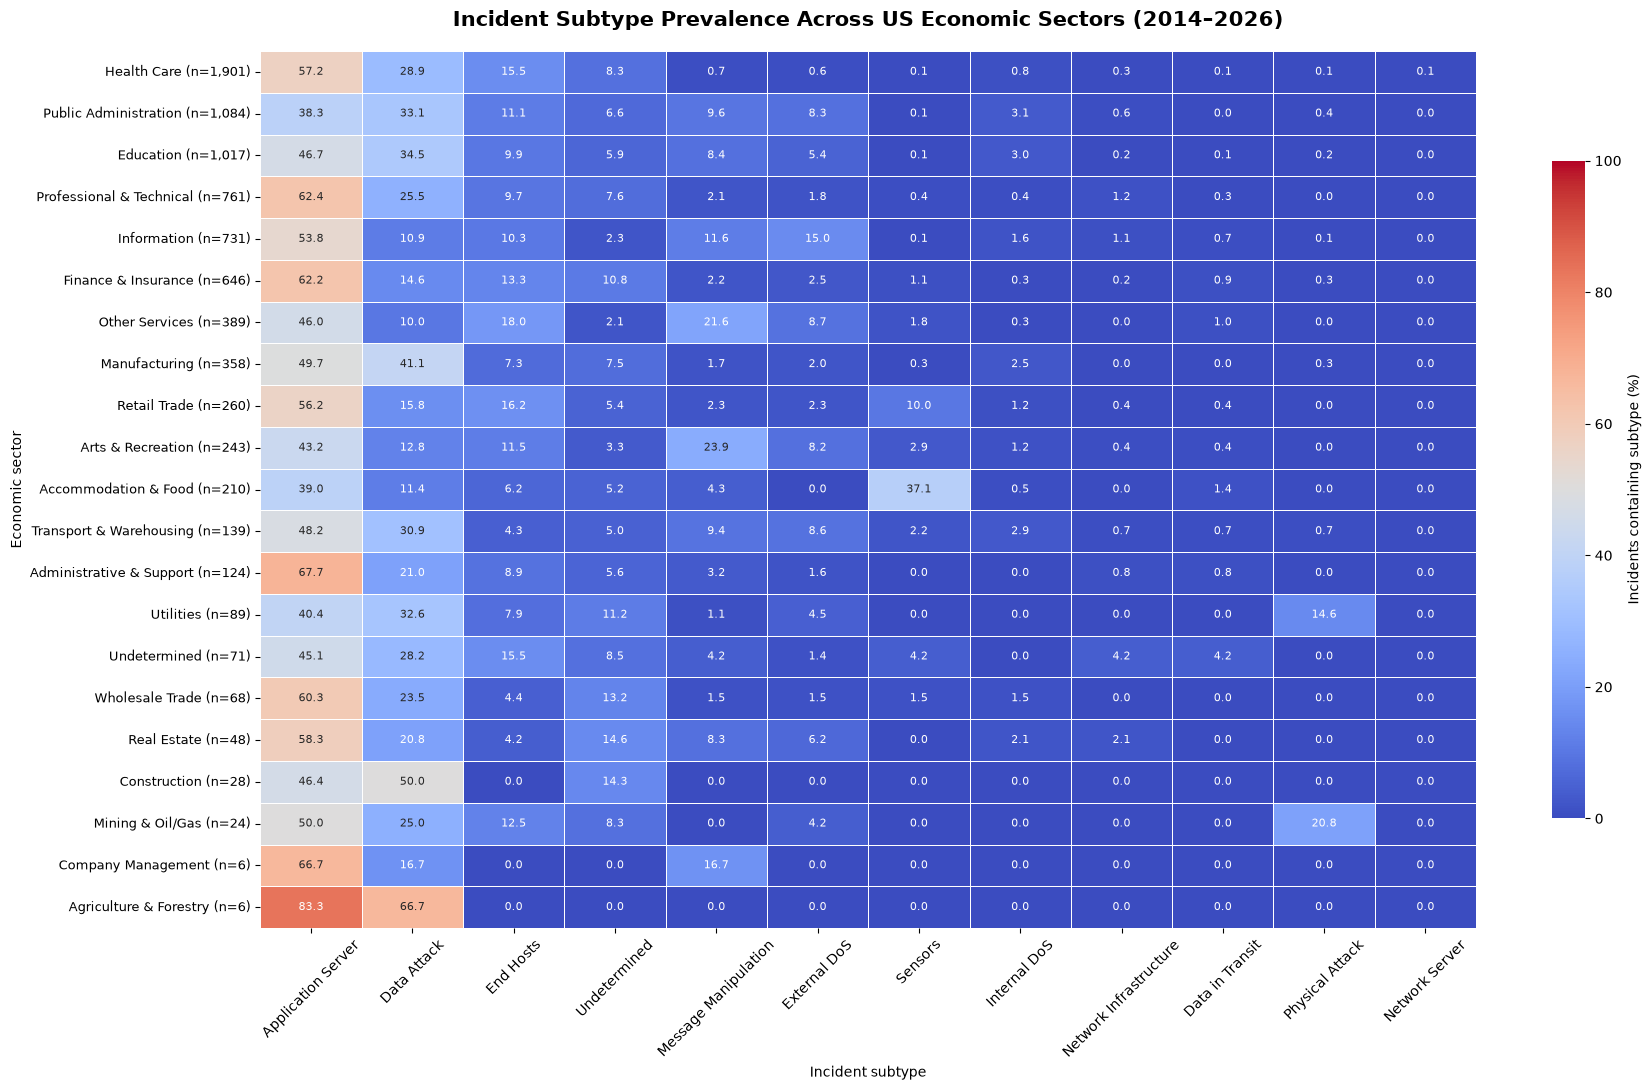

In [69]:
# Prepare a readable sector–subtype prevalence matrix
usa_subtype_short_names = {
    "Exploitation of Application Server": "Application Server",
    "Data Attack": "Data Attack",
    "Exploitation of End Hosts": "End Hosts",
    "Undetermined": "Undetermined",
    "Message Manipulation": "Message Manipulation",
    "External Denial of Service": "External DoS",
    "Exploitation of Sensors": "Sensors",
    "Internal Denial of Service": "Internal DoS",
    "Exploitation of Network Infrastructure": "Network Infrastructure",
    "Exploitation of Data in Transit": "Data in Transit",
    "Physical Attack": "Physical Attack",
    "Exploitation of Network Server": "Network Server"
}

usa_sector_subtype_heatmap_data = (
    usa_sector_subtype_shares
    .rename(columns=usa_subtype_short_names)
    .copy()
)

usa_sector_subtype_heatmap_data.index = [
    f"{sector_display_names.get(sector, sector)} (n={usa_sector_sizes[sector]:,})"
    for sector in usa_sector_subtype_heatmap_data.index
]

# Draw the heatmap
fig_usa_sector_subtype_heatmap, ax_usa_sector_subtype_heatmap = (
    plt.subplots(figsize=(18, 11))
)

sns.heatmap(
    usa_sector_subtype_heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={
        "label": "Incidents containing subtype (%)",
        "shrink": 0.75
    },
    annot_kws={"fontsize": 8},
    ax=ax_usa_sector_subtype_heatmap
)

ax_usa_sector_subtype_heatmap.set_title(
    "Incident Subtype Prevalence Across US Economic Sectors (2014–2026)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax_usa_sector_subtype_heatmap.set_xlabel("Incident subtype")
ax_usa_sector_subtype_heatmap.set_ylabel("Economic sector")

ax_usa_sector_subtype_heatmap.tick_params(
    axis="x", rotation=45, labelsize=10
)
ax_usa_sector_subtype_heatmap.tick_params(
    axis="y", rotation=0, labelsize=9
)

fig_usa_sector_subtype_heatmap.tight_layout()
plt.show()

### Observations and potential explanations

The prevalence of documented incident subtypes differs across economic sectors.

- **Data Attack** is particularly prominent in Manufacturing (41.1%), Educational Services (34.5%), and Public Administration (33.1%). Its possible association with ransomware-related activity warrants further investigation.
- **Exploitation of Sensors** accounts for 37.1% of incidents in Accommodation and Food Services. Compromised payment systems and connected devices are potential explanations to examine.
- **External Denial of Service** is relatively prominent in Information (15.0%).
- **Physical Attack** represents 14.6% of incidents in Utilities, raising questions about incidents involving operational technology and industrial control systems.
- **Exploitation of Application Server** is highly represented across many sectors, although its prevalence varies substantially.

These observations provide directions for further investigation rather than explanations of the underlying causes.

Sector sample sizes are shown alongside sector names. Percentages represent the share of incidents within each sector containing a particular subtype and may sum to more than 100% because incidents can have multiple subtypes.

### 6.4 Ransomware-related incidents by economic sector

Ransomware-related terminology is examined across all documented US cyber incidents, regardless of their assigned incident type or subtype.

The analysis compares both the absolute number of incidents mentioning ransomware and their proportion within each economic sector.

Keyword matches are treated as exploratory indicators rather than confirmed ransomware classifications.

In [70]:
# Identify ransomware mentions across all documented US incidents
usa_ransomware_data = usa_final.copy()

usa_ransomware_data["ransomware_mentioned"] = (
    usa_ransomware_data["description"]
    .fillna("")
    .str.contains(
        r"\bransom[\s-]?ware\b",
        case=False,
        regex=True
    )
)

# Summarize ransomware mentions by economic sector
usa_ransomware_sector_summary = (
    usa_ransomware_data
    .groupby("industry")
    .agg(
        Total_incidents=("slug", "size"),
        Ransomware_mentions=("ransomware_mentioned", "sum")
    )
)

usa_ransomware_sector_summary["Other_incidents"] = (
    usa_ransomware_sector_summary["Total_incidents"]
    - usa_ransomware_sector_summary["Ransomware_mentions"]
)

usa_ransomware_sector_summary["Mention_share (%)"] = (
    usa_ransomware_sector_summary["Ransomware_mentions"]
    / usa_ransomware_sector_summary["Total_incidents"]
    * 100
).round(2)

# Order sectors by their ransomware mention counts
usa_ransomware_sector_summary = (
    usa_ransomware_sector_summary
    .sort_values("Ransomware_mentions", ascending=False)
)

display(usa_ransomware_sector_summary)

,Total_incidents,Ransomware_mentions,Other_incidents,Mention_share (%)
industry,,,,
Health Care and Social Assistance,1901,570,1331,29.98
Educational Services,1017,353,664,34.71
Public Administration,1084,333,751,30.72
"Professional, Scientific, and Technical Services",761,186,575,24.44
Manufacturing,358,132,226,36.87
Finance and Insurance,646,103,543,15.94
Information,731,73,658,9.99
Transportation and Warehousing,139,38,101,27.34
Other Services (except Public Administration),389,36,353,9.25


### 6.5 Geographical distribution of ransomware-related incidents

This section examines the geographical distribution of ransomware mentions across US states and territories.

Two complementary measures are considered:

- **Absolute frequency:** The number of documented incidents mentioning ransomware in each location.
- **Relative frequency:** The percentage of all documented incidents within each location that mention ransomware.

Unknown and unspecified locations are retained separately to assess geographical data coverage.

Ransomware mentions are identified using incident descriptions and should not be interpreted as independently verified ransomware classifications.

In [71]:
# Summarize ransomware mentions across US geographical locations
usa_ransomware_state_summary = (
    usa_ransomware_data
    .assign(
        state_label=lambda data: (
            data["state"]
            .fillna("Missing")
            .replace({"undetermined": "Undetermined"})
        )
    )
    .groupby("state_label")
    .agg(
        Total_incidents=("slug", "size"),
        Ransomware_mentions=("ransomware_mentioned", "sum")
    )
)

usa_ransomware_state_summary["Other_incidents"] = (
    usa_ransomware_state_summary["Total_incidents"]
    - usa_ransomware_state_summary["Ransomware_mentions"]
)

usa_ransomware_state_summary["Mention_share (%)"] = (
    usa_ransomware_state_summary["Ransomware_mentions"]
    / usa_ransomware_state_summary["Total_incidents"]
    * 100
).round(2)

usa_ransomware_state_summary = (
    usa_ransomware_state_summary
    .sort_values("Ransomware_mentions", ascending=False)
)

display(usa_ransomware_state_summary)

,Total_incidents,Ransomware_mentions,Other_incidents,Mention_share (%)
state_label,,,,
Undetermined,1441,200,1241,13.88
California,925,174,751,18.81
Texas,546,150,396,27.47
New York,488,129,359,26.43
Florida,332,93,239,28.01
Illinois,279,83,196,29.75
Georgia,235,82,153,34.89
Pennsylvania,236,75,161,31.78
Ohio,188,65,123,34.57


In [72]:
# Prepare annual ransomware statistics for US states
usa_ransomware_state_annual = (
    usa_ransomware_data
    .assign(
        state_label=lambda data: (
            data["state"]
            .fillna("Missing")
            .replace({"undetermined": "Undetermined"})
        )
    )
    .groupby(["state_label", "year"])
    .agg(
        Total_incidents=("slug", "size"),
        Ransomware_mentions=("ransomware_mentioned", "sum")
    )
    .reset_index()
)

usa_ransomware_state_annual["Mention_share (%)"] = (
    usa_ransomware_state_annual["Ransomware_mentions"]
    / usa_ransomware_state_annual["Total_incidents"]
    * 100
).round(2)

display(
    usa_ransomware_state_annual
    .sort_values(
        ["year", "Ransomware_mentions"],
        ascending=[True, False]
    )
    .head(20)
)

,state_label,year,Total_incidents,Ransomware_mentions,Mention_share (%)
0,Alabama,2014,1,0,0.0
12,Alaska,2014,1,0,0.0
22,Arizona,2014,7,0,0.0
35,Arkansas,2014,1,0,0.0
46,California,2014,47,0,0.0
59,Colorado,2014,1,0,0.0
72,Connecticut,2014,4,0,0.0
84,Delaware,2014,3,0,0.0
96,Florida,2014,7,0,0.0
109,Georgia,2014,4,0,0.0


In [73]:
# Prepare a complete state-year grid, including years without incidents
usa_ransomware_map_data = (
    pd.MultiIndex.from_product(
        [usa_state_abbreviations.keys(), range(2014, 2027)],
        names=["state_label", "year"]
    )
    .to_frame(index=False)
    .merge(
        usa_ransomware_state_annual,
        on=["state_label", "year"],
        how="left",
        validate="one_to_one"
    )
)

usa_ransomware_map_data[
    ["Total_incidents", "Ransomware_mentions"]
] = usa_ransomware_map_data[
    ["Total_incidents", "Ransomware_mentions"]
].fillna(0).astype(int)

usa_ransomware_map_data["Mention_share (%)"] = (
    usa_ransomware_map_data["Ransomware_mentions"]
    .div(
        usa_ransomware_map_data["Total_incidents"].replace(0, np.nan)
    )
    .mul(100)
)

usa_ransomware_map_data["Code"] = (
    usa_ransomware_map_data["state_label"]
    .map(usa_state_abbreviations)
)

usa_ransomware_map_data["Year"] = (
    usa_ransomware_map_data["year"].astype(str)
)

In [74]:
# Interactive choropleth of ransomware mention counts
fig_usa_ransomware_counts_map = px.choropleth(
    usa_ransomware_map_data,
    locations="Code",
    locationmode="USA-states",
    scope="usa",
    color="Ransomware_mentions",
    animation_frame="Year",
    hover_name="state_label",
    hover_data={
        "Code": False,
        "Year": False,
        "Total_incidents": True,
        "Ransomware_mentions": True,
        "Mention_share (%)": ":.2f"
    },
    color_continuous_scale="RdBu_r",
    range_color=(
        0,
        usa_ransomware_map_data["Ransomware_mentions"].max()
    ),
    labels={
        "Ransomware_mentions": "Ransomware mentions",
        "Total_incidents": "Total incidents",
        "Mention_share (%)": "Mention share (%)"
    },
    title="Ransomware Mentions Across US States (2014–2026)"
)

fig_usa_ransomware_counts_map.update_layout(
    height=650,
    title_x=0.5,
    margin=dict(l=20, r=20, t=70, b=80)
)

fig_usa_ransomware_counts_map.show()

In [75]:
# Interactive choropleth of ransomware mention shares
fig_usa_ransomware_shares_map = px.choropleth(
    usa_ransomware_map_data,
    locations="Code",
    locationmode="USA-states",
    scope="usa",
    color="Mention_share (%)",
    animation_frame="Year",
    hover_name="state_label",
    hover_data={
        "Code": False,
        "Year": False,
        "Total_incidents": True,
        "Ransomware_mentions": True,
        "Mention_share (%)": ":.2f"
    },
    color_continuous_scale="RdBu_r",
    range_color=(0, 100),
    labels={
        "Ransomware_mentions": "Ransomware mentions",
        "Total_incidents": "Total incidents",
        "Mention_share (%)": "Mention share (%)"
    },
    title="Ransomware Mention Shares Across US States (2014–2026)"
)

fig_usa_ransomware_shares_map.update_layout(
    height=650,
    title_x=0.5,
    margin=dict(l=20, r=20, t=70, b=80)
)

fig_usa_ransomware_shares_map.show()


## 7. Targeted organizations

This section examines how documented cyber incidents are distributed across organizations, focusing on incident concentration, repeated occurrences, and organizational characteristics.

### 7.1 Organization name consolidation

Organization names are standardized using a manually reviewed mapping of naming variants, abbreviations, and related services. Original values are preserved for traceability.


In [76]:
# Consolidate organization names
organization_mapping_path = Path(
    "../src/organization_name_mapping.csv"
)

usa_final = consolidate_organizations(
    usa_final,
    mapping_path=organization_mapping_path
)

assert len(usa_final) == 8203


In [77]:
# Summarize organization name consolidation
original_names = usa_final["organization"].astype("string").str.strip()
clean_names = usa_final["organization_clean"].astype("string")

identified_mask = usa_final["organization_status"].ne("unknown")

changed_mask = (
    identified_mask
    & original_names.ne(clean_names).fillna(False)
)

organization_summary = pd.DataFrame({
    "Metric": [
        "Total incidents",
        "Original distinct names",
        "Distinct names before consolidation (identified)",
        "Distinct names after consolidation (identified)",
        "Records with standardized names",
        "Reduction in distinct identified names",
        "Unidentified incidents"
    ],
    "Value": [
        len(usa_final),
        original_names.nunique(),
        original_names[identified_mask].nunique(),
        clean_names[identified_mask].nunique(),
        int(changed_mask.sum()),
        int(
            original_names[identified_mask].nunique()
            - clean_names[identified_mask].nunique()
        ),
        int((~identified_mask).sum())
    ]
})

display(organization_summary)


,Metric,Value
0,Total incidents,8203
1,Original distinct names,7574
2,Distinct names before consolidation (identified),7473
3,Distinct names after consolidation (identified),7327
4,Records with standardized names,208
5,Reduction in distinct identified names,146
6,Unidentified incidents,104


In [78]:
# Show representative consolidation examples
selected_names = [
    "Auto Zone",
    "Hewlett Packard Enterprise (HPE)",
    "Boeing Commercial Airplanes",
    "Google News",
    "Microsoft News",
    "Amazon users",
    "Bank of America customers",
    "The Wayback Machine"
]

organization_examples = (
    usa_final.loc[
        usa_final["organization"].isin(selected_names) & changed_mask,
        ["organization", "organization_clean"]
    ]
    .drop_duplicates()
    .rename(columns={
        "organization": "Original name",
        "organization_clean": "Consolidated name"
    })
    .sort_values("Original name")
)

display(organization_examples)


,Original name,Consolidated name
14427,Amazon users,Amazon
1185,Auto Zone,AutoZone
5942,Bank of America customers,Bank of America
2876,Boeing Commercial Airplanes,Boeing
2979,Google News,Google
13595,Hewlett Packard Enterprise (HPE),Hewlett Packard Enterprise
32,Microsoft News,Microsoft
14310,The Wayback Machine,Internet Archive


Organization name consolidation standardized 208 of 8,203 incident records (2.54%) and reduced the number of distinct identified names from 7,473 to 7,327 (1.95%). A total of 104 incidents had unidentified targets. Original names were retained to preserve information about the affected services, accounts, or users.



#### Export of the deduplicated and consolidated US dataset

Export the final US incident-level dataset after duplicate removal and organization name standardization. Original values are retained for traceability, while unresolved and missing values remain unchanged.

The exported dataset serves as the consistent input for subsequent analyses of US states and external explanatory factors.


In [79]:
# Export the deduplicated and organization-standardized US dataset
PROCESSED_USA_DIR = Path("../data/processed/umd_usa").resolve()
PROCESSED_USA_DIR.mkdir(parents=True, exist_ok=True)

USA_EXPORT_PATH = (
    PROCESSED_USA_DIR
    / "umd_usa_deduplicated_consolidated.csv"
)

# Validate the final dataset before export
assert len(usa_final) == 8203
assert usa_final["slug"].is_unique
assert usa_final["country_iso3"].eq("USA").all()
assert {"organization_clean", "organization_status"}.issubset(
    usa_final.columns
)

# Export all columns and records
usa_final.to_csv(
    USA_EXPORT_PATH,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print(f"Exported dataset: {USA_EXPORT_PATH}")
print(f"Records: {len(usa_final):,}")
print(f"Columns: {len(usa_final.columns)}")


Exported dataset: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\data\processed\umd_usa\umd_usa_deduplicated_consolidated.csv
Records: 8,203
Columns: 49


### 7.2 Organization-level incident concentration

Identify the organizations most frequently associated with documented cyber incidents and examine the concentration of incidents across organizations.


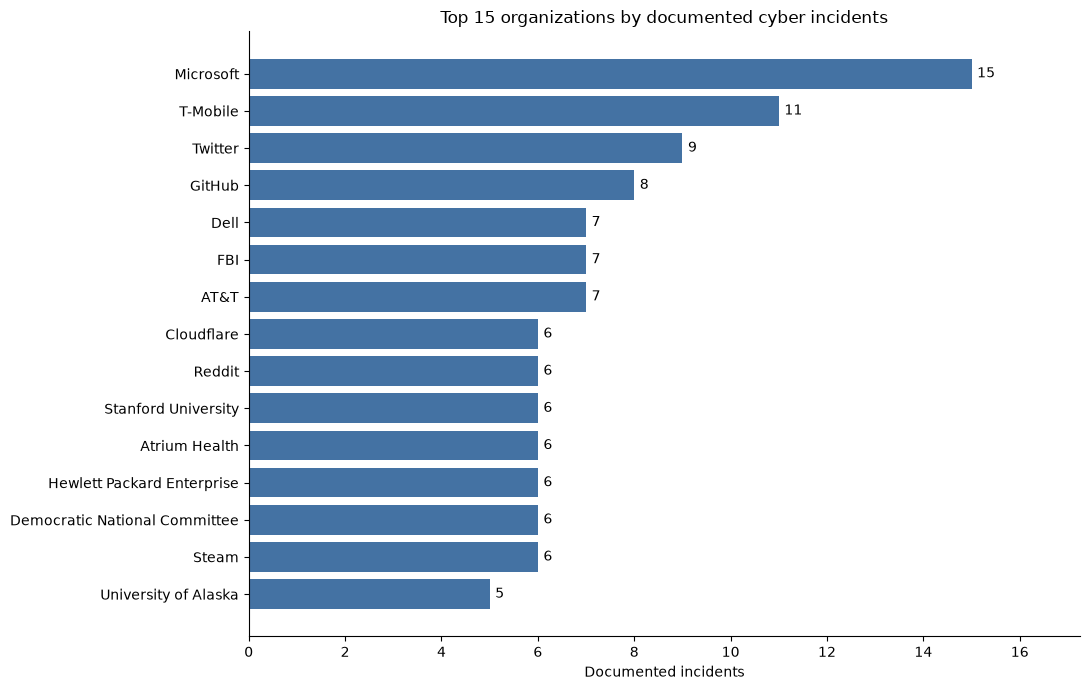

In [80]:
# Identify the most frequently documented organizations
organization_incident_counts = (
    usa_final.loc[
        usa_final["organization_status"].ne("unknown"),
        "organization_clean"
    ]
    .dropna()
    .value_counts()
)

top_organizations = organization_incident_counts.head(15).sort_values()

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_organizations.index,
    top_organizations.values,
    color="#4472A3"
)

ax.bar_label(bars, padding=4)
ax.set_xlabel("Documented incidents")
ax.set_ylabel("")
ax.set_title("Top 15 organizations by documented cyber incidents")
ax.set_xlim(0, top_organizations.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


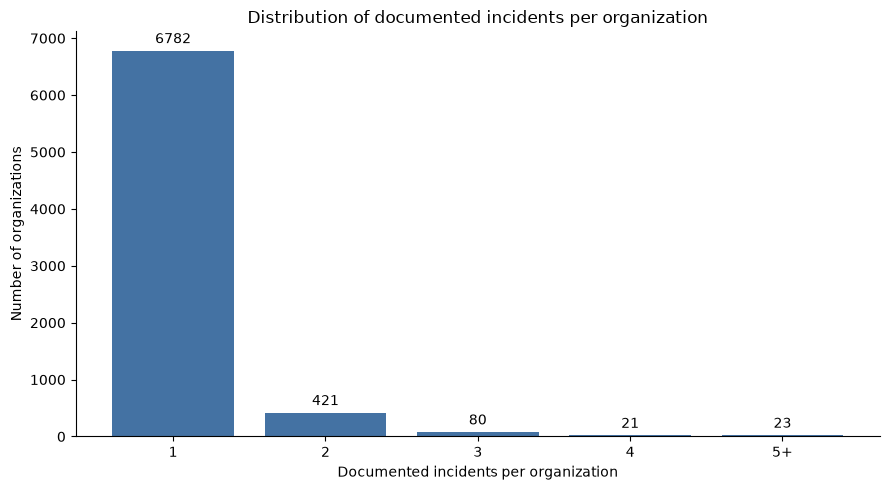

In [81]:
# Examine the distribution of incident counts per organization
organization_frequency = (
    organization_incident_counts
    .value_counts()
    .sort_index()
)

organization_frequency_plot = organization_frequency.copy()
organization_frequency_plot.index = organization_frequency_plot.index.map(
    lambda count: str(count) if count < 5 else "5+"
)

organization_frequency_plot = (
    organization_frequency_plot.groupby(level=0).sum()
    .reindex(["1", "2", "3", "4", "5+"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    organization_frequency_plot.index,
    organization_frequency_plot.values,
    color="#4472A3"
)

ax.bar_label(bars, padding=3)
ax.set_xlabel("Documented incidents per organization")
ax.set_ylabel("Number of organizations")
ax.set_title("Distribution of documented incidents per organization")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


Most consolidated organizations (6,782; 92.6%) appear in only one documented incident. Only 545 organizations (7.4%) appear more than once, indicating a highly dispersed distribution of recorded incidents. Repeated appearances do not necessarily represent independent attacks or greater organizational vulnerability.



### 7.3 Repeated incidents over time

Examine whether organizations with multiple documented incidents are represented within a single year or across several years.



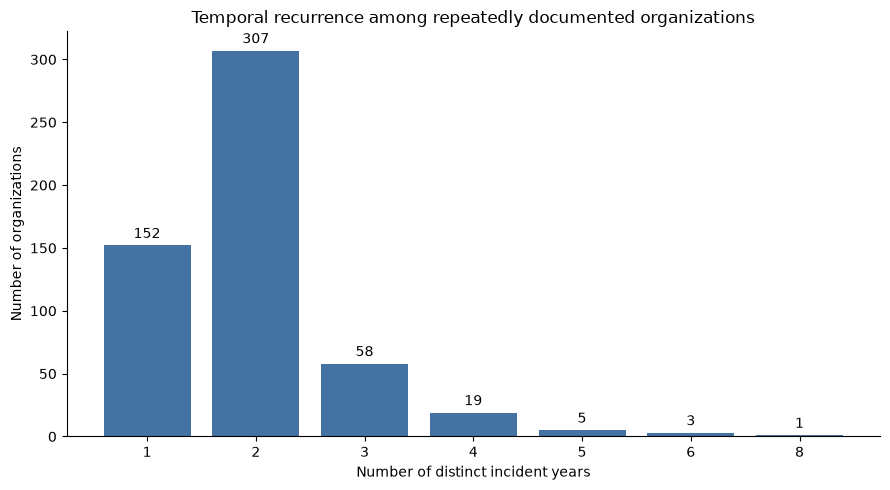

In [82]:
# Count distinct incident years for repeatedly documented organizations
repeated_organizations = organization_incident_counts[
    organization_incident_counts > 1
].index

repeated_organization_years = (
    usa_final.loc[
        usa_final["organization_clean"].isin(repeated_organizations)
    ]
    .groupby("organization_clean")["year"]
    .nunique()
)

year_distribution = (
    repeated_organization_years
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    year_distribution.index.astype(str),
    year_distribution.values,
    color="#4472A3"
)

ax.bar_label(bars, padding=3)
ax.set_xlabel("Number of distinct incident years")
ax.set_ylabel("Number of organizations")
ax.set_title("Temporal recurrence among repeatedly documented organizations")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


Among the 545 organizations with multiple documented incidents, 393 (72.1%) appear across at least two distinct years, while 152 (27.9%) have multiple records within a single year. One organization appears in eight different years, indicating that repeated documentation can extend over a substantial period.


In [83]:
# Identify organizations appearing in the most distinct years
max_incident_years = repeated_organization_years.max()

longest_recurrence = repeated_organization_years[
    repeated_organization_years == max_incident_years
].index

longest_recurrence_incidents = (
    usa_final.loc[
        usa_final["organization_clean"].isin(longest_recurrence),
        [
            "organization_clean",
            "event_date",
            "event_type",
            "event_subtype",
            "description"
        ]
    ]
    .sort_values(["organization_clean", "event_date"])
)

display(longest_recurrence_incidents)


,organization_clean,event_date,event_type,event_subtype,description
3291,T-Mobile,2017-10-27,Exploitive,Exploitation of End Hosts,T-Mobile warns customers targeted by hackers t...
3928,T-Mobile,2018-08-23,Exploitive,Exploitation of Application Server,T-Mobile reveals that hackers stole some of th...
5172,T-Mobile,2019-11-22,Exploitive,Exploitation of Application Server,The US branch of telecommunications giant T-Mo...
5575,T-Mobile,2020-03-04,Exploitive,Exploitation of Application Server,US telecommunications giant T-Mobile discloses...
7017,T-Mobile,2020-12-30,Exploitive,Exploitation of Application Server,T-Mobile has revealed a data breach that has e...
7380,T-Mobile,2021-02-26,Exploitive,Exploitation of Application Server,T-Mobile discloses a data breach after an unkn...
8077,T-Mobile,2021-08-14,Exploitive,Exploitation of Application Server,Hacker claims to have breached T-Mobile's serv...
9097,T-Mobile,2022-04-22,Exploitive,Exploitation of End Hosts,T-Mobile confirms that the Lapsus$ extortion g...
11053,T-Mobile,2023-01-05,Exploitive,Exploitation of Application Server,T-Mobile discloses a new data breach after a t...
11618,T-Mobile,2023-03-31,Exploitive,Exploitation of Application Server,T-Mobile discloses the second data breach of 2...


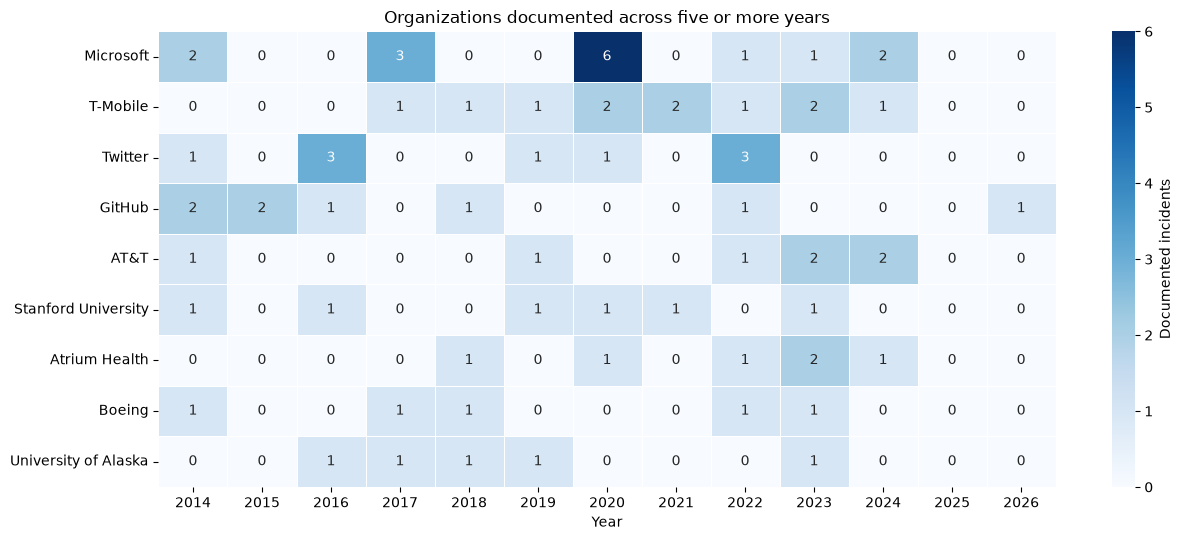

In [84]:
# Select organizations documented in at least five distinct years
long_term_organizations = repeated_organization_years[
    repeated_organization_years >= 5
].index

organization_year_matrix = (
    usa_final.loc[
        usa_final["organization_clean"].isin(long_term_organizations)
    ]
    .groupby(["organization_clean", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=sorted(usa_final["year"].dropna().unique()), fill_value=0)
)

organization_year_matrix = organization_year_matrix.loc[
    organization_year_matrix.sum(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(13, 5.5))

sns.heatmap(
    organization_year_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Documented incidents"},
    ax=ax
)

ax.set_title("Organizations documented across five or more years")
ax.set_xlabel("Year")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


Nine organizations appear in at least five distinct years. T-Mobile shows the longest continuous recurrence, with incidents documented annually from 2017 to 2024. Microsoft has the highest incident count (15), including six incidents in 2020, while Boeing and the University of Alaska each have one documented incident in five separate years.



#### Do organizations with repeated incidents experience the same types of cyberattacks or different ones?


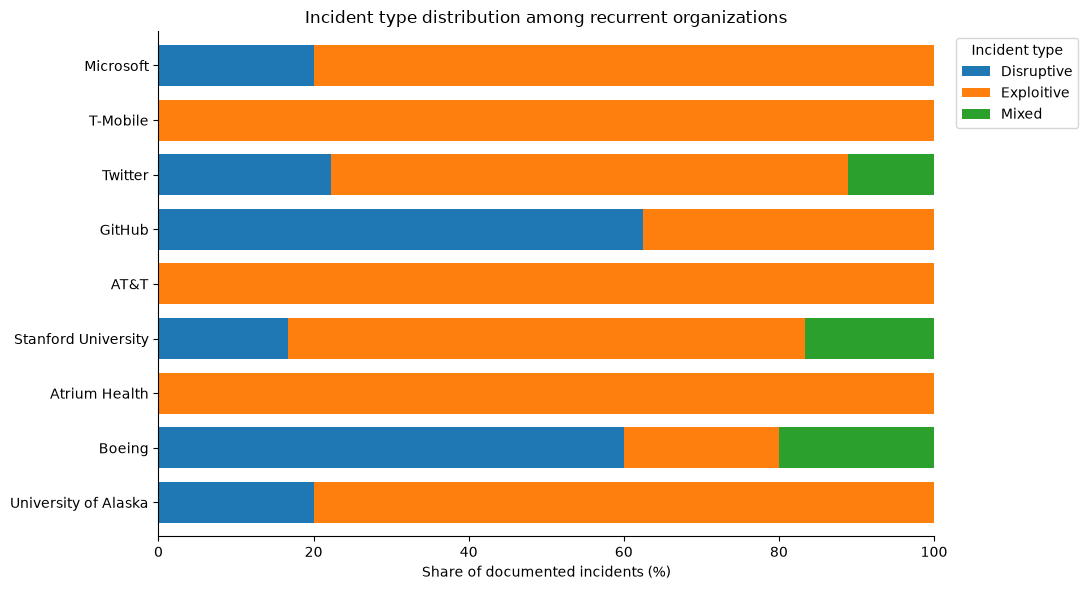

In [85]:
# Compare incident types among organizations documented in at least five years
organization_type_counts = pd.crosstab(
    usa_final.loc[
        usa_final["organization_clean"].isin(long_term_organizations),
        "organization_clean"
    ],
    usa_final.loc[
        usa_final["organization_clean"].isin(long_term_organizations),
        "event_type"
    ]
)

organization_type_shares = (
    organization_type_counts
    .div(organization_type_counts.sum(axis=1), axis=0)
    .mul(100)
    .reindex(organization_year_matrix.index)
)

ax = organization_type_shares.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    width=0.75
)

ax.invert_yaxis()
ax.set_xlabel("Share of documented incidents (%)")
ax.set_ylabel("")
ax.set_title("Incident type distribution among recurrent organizations")
ax.legend(title="Incident type", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


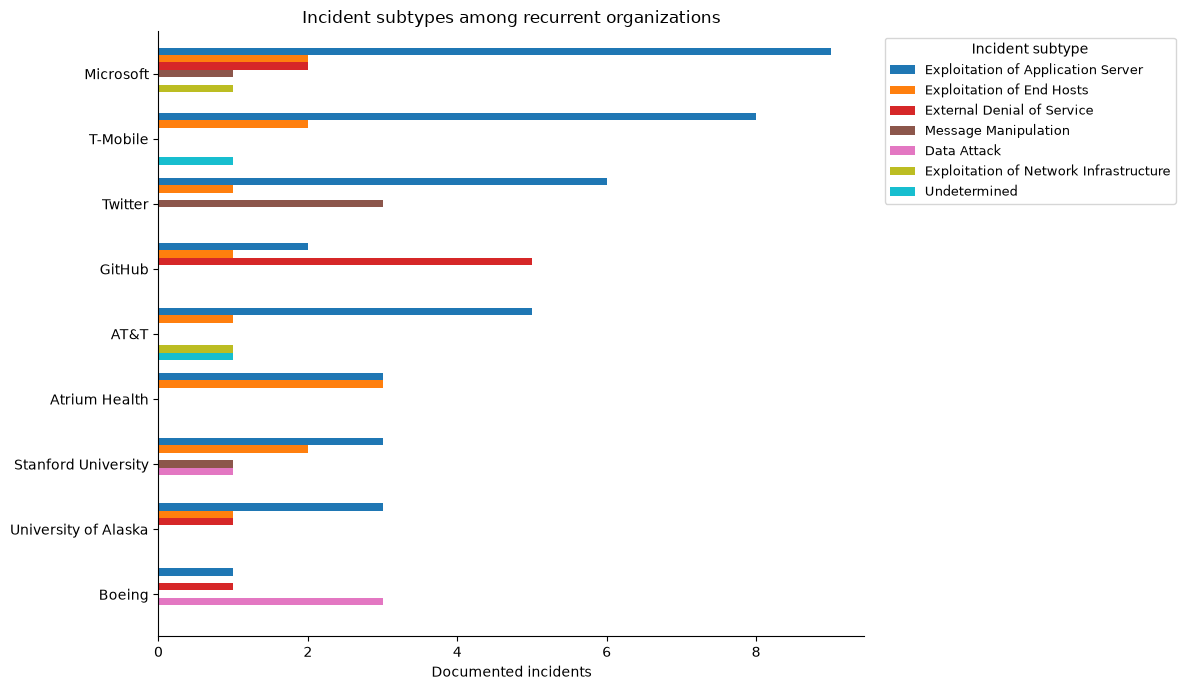

In [86]:

# Visualize standardized incident subtypes across recurrent organizations

# Select organizations appearing in at least five distinct years
organization_year_counts = (
    usa_final.dropna(subset=["organization_clean"])
    .groupby("organization_clean")["year"]
    .nunique()
)

long_term_organizations = organization_year_counts[
    organization_year_counts >= 5
].index

# Order organizations by their total number of documented incidents
organization_order = (
    usa_final.loc[
        usa_final["organization_clean"].isin(long_term_organizations),
        "organization_clean"
    ]
    .value_counts()
    .index
)

# Link already standardized incident subtypes to organizations
organization_subtypes = (
    usa_incident_subtypes[["slug", "subtype"]]
    .merge(
        usa_final[["slug", "organization_clean"]],
        on="slug",
        how="inner",
        validate="many_to_one"
    )
)

organization_subtypes = organization_subtypes.loc[
    organization_subtypes["organization_clean"].isin(long_term_organizations)
]

# Count each standardized subtype per organization
organization_subtype_matrix = pd.crosstab(
    organization_subtypes["organization_clean"],
    organization_subtypes["subtype"]
).reindex(organization_order, fill_value=0)

# Sort subtypes by overall frequency
subtype_plot = organization_subtype_matrix.loc[
    :,
    organization_subtype_matrix.sum().sort_values(ascending=False).index
]

# Visualize subtype counts
ax = subtype_plot.plot(
    kind="barh",
    stacked=False,
    figsize=(12, 7),
    width=0.8,
    colormap="tab10"
)

ax.invert_yaxis()
ax.set_xlabel("Documented incidents")
ax.set_ylabel("")
ax.set_title("Incident subtypes among recurrent organizations")
ax.legend(
    title="Incident subtype",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


Incident subtype distributions vary across recurrent organizations. Exploitation of Application Server dominates at Microsoft (9 incidents) and T-Mobile (8), while External Denial of Service is most frequent at GitHub (5). Twitter also shows Message Manipulation (3), whereas Data Attack is the most common subtype at Boeing (3). Individual incidents may have multiple subtype labels.


**Do organizations with repeated incidents experience the same types of cyberattacks or different ones?**

Answer: *Different incident types and subtypes are documented, although exploitation-related incidents dominate for several organizations.*


### 7.4 Organizations by sector and state

Examine the distribution of consolidated organizations across economic sectors and U.S. states, with particular attention to organizations associated with multiple documented incidents.

#### Which economic sectors have the highest concentration of repeatedly documented organizations?


In [87]:
# Compare organizations with repeated incidents across economic sectors
organization_sector_data = usa_final.loc[
    usa_final["organization_clean"].notna(),
    ["organization_clean", "industry"]
].drop_duplicates().copy()

organization_sector_data["repeated"] = (
    organization_sector_data["organization_clean"]
    .isin(repeated_organizations)
)

organization_sector_summary = (
    organization_sector_data
    .groupby("industry", dropna=False)
    .agg(
        Organizations=("organization_clean", "nunique"),
        Repeated_organizations=("repeated", "sum")
    )
    .reset_index()
)

organization_sector_summary["Repeated share (%)"] = (
    organization_sector_summary["Repeated_organizations"]
    / organization_sector_summary["Organizations"] * 100
).round(2)

organization_sector_summary = (
    organization_sector_summary
    .sort_values("Repeated_organizations", ascending=False)
)

display(organization_sector_summary)


,industry,Organizations,Repeated_organizations,Repeated share (%)
7,Health Care and Social Assistance,1750,137,7.83
8,Information,575,83,14.43
5,Educational Services,904,82,9.07
13,"Professional, Scientific, and Technical Services",689,64,9.29
14,Public Administration,996,59,5.92
6,Finance and Insurance,593,47,7.93
10,Manufacturing,329,26,7.90
3,"Arts, Entertainment, and Recreation",221,23,10.41
12,Other Services (except Public Administration),363,22,6.06
16,Retail Trade,229,20,8.73



### 7.4 Organizations by sector and state

Examine the geographical and sectoral distribution of distinct consolidated organizations associated with documented cyber incidents.

#### How are affected organizations distributed across economic sectors?


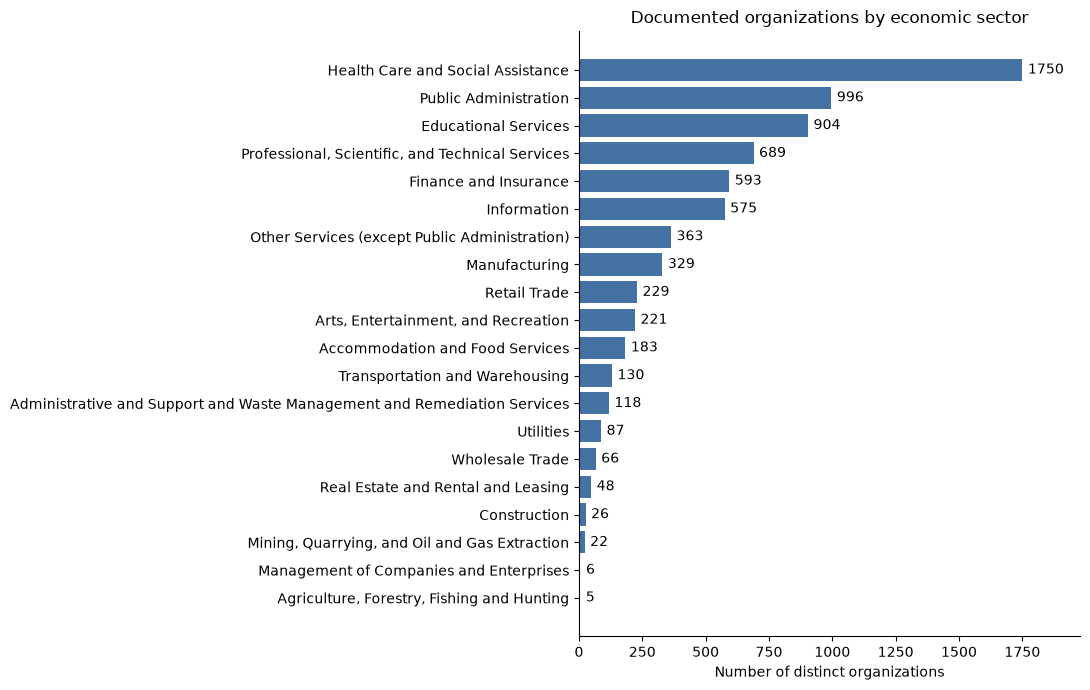

In [88]:
# Count distinct organizations by economic sector
organizations_by_sector = (
    usa_final.loc[
        usa_final["organization_clean"].notna()
        & usa_final["industry"].notna()
        & usa_final["industry"].ne("Undetermined")
    ]
    .groupby("industry")["organization_clean"]
    .nunique()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    organizations_by_sector.index,
    organizations_by_sector.values,
    color="#4472A3"
)

ax.bar_label(bars, padding=4)
ax.set_xlabel("Number of distinct organizations")
ax.set_ylabel("")
ax.set_title("Documented organizations by economic sector")
ax.set_xlim(0, organizations_by_sector.max() * 1.13)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()



#### In which U.S. states are the most documented organizations located?

Map the number of distinct consolidated organizations associated with incidents in each state. Organizations appearing in multiple states are counted once per state.


In [89]:
# Count distinct organizations by U.S. state
state_abbreviations = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ",
    "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE", "Florida": "FL",
    "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA",
    "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE",
    "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY", "North Carolina": "NC",
    "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI",
    "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
    "District of Columbia": "DC"
}

organizations_by_state = (
    usa_final.loc[usa_final["organization_clean"].notna()]
    .groupby("state")["organization_clean"]
    .nunique()
    .rename("Organizations")
    .reset_index()
)

organizations_by_state["State code"] = (
    organizations_by_state["state"].map(state_abbreviations)
)

organizations_by_state_map = organizations_by_state.dropna(
    subset=["State code"]
)

fig = px.choropleth(
    organizations_by_state_map,
    locations="State code",
    locationmode="USA-states",
    color="Organizations",
    hover_name="state",
    scope="usa",
    color_continuous_scale="Blues",
    title="Distinct documented organizations by U.S. state"
)

fig.update_layout(
    height=620,
    margin=dict(l=0, r=0, t=60, b=0),
    coloraxis_colorbar_title="Organizations"
)

fig.show()


#### How does the geographical distribution of cyber incidents differ across economic sectors?



In [90]:
# Prepare incident counts by state and economic sector
sector_state_data = usa_final.loc[
    usa_final["state"].isin(state_abbreviations)
    & usa_final["industry"].notna()
    & usa_final["industry"].ne("Undetermined")
]

sector_state_counts = pd.crosstab(
    sector_state_data["state"],
    sector_state_data["industry"]
).reindex(state_abbreviations.keys(), fill_value=0)

sector_options = ["All sectors"] + (
    sector_state_data["industry"].value_counts().index.tolist()
)

fig = go.Figure()

for i, sector in enumerate(sector_options):
    counts = (
        sector_state_counts.sum(axis=1)
        if sector == "All sectors"
        else sector_state_counts[sector]
    )

    fig.add_trace(go.Choropleth(
        locations=[state_abbreviations[s] for s in counts.index],
        z=counts.values,
        text=counts.index,
        locationmode="USA-states",
        colorscale="Blues",
        zmin=0,
        zmax=max(int(counts.max()), 1),
        marker_line_color="white",
        marker_line_width=0.5,
        colorbar_title="Incidents",
        hovertemplate="<b>%{text}</b><br>Incidents: %{z}<extra></extra>",
        visible=(i == 0)
    ))

buttons = [
    dict(
        label=sector,
        method="update",
        args=[
            {"visible": [j == i for j in range(len(sector_options))]},
            {"title": f"Documented cyber incidents by state — {sector}"}
        ]
    )
    for i, sector in enumerate(sector_options)
]

fig.update_layout(
    title="Documented cyber incidents by state — All sectors",
    geo=dict(scope="usa"),
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        x=0.02,
        y=1.03,
        xanchor="left",
        yanchor="bottom",
        showactive=True
    )],
    height=650,
    margin=dict(l=0, r=0, t=115, b=0)
)

fig.show()


### 7.5 Organizational incident histories

Examine selected organizations with recurring documented incidents to identify temporal patterns and differences in incident classifications.

#### How do incident histories differ between Microsoft, T-Mobile, and GitHub?


In [91]:

# Visualize incident histories of selected organizations
import textwrap
import plotly.express as px

selected_organizations = ["Microsoft", "T-Mobile", "GitHub"]

# Prepare incident data
organization_histories = usa_final.loc[
    usa_final["organization_clean"].isin(selected_organizations),
    [
        "organization_clean", "event_date", "event_type",
        "event_subtype", "description"
    ]
].copy()

organization_histories["event_date"] = pd.to_datetime(
    organization_histories["event_date"],
    errors="coerce"
)

organization_histories = organization_histories.dropna(
    subset=["event_date"]
)

# Wrap descriptions for readable hover tooltips
organization_histories["description_wrapped"] = (
    organization_histories["description"]
    .fillna("No description available")
    .apply(
        lambda text: "<br>".join(
            textwrap.wrap(str(text), width=65)
        )
    )
)

organization_histories["event_subtype"] = (
    organization_histories["event_subtype"]
    .fillna("Undetermined")
)

# Create interactive timeline
fig = px.scatter(
    organization_histories,
    x="event_date",
    y="organization_clean",
    color="event_type",
    category_orders={
        "organization_clean": selected_organizations
    },
    custom_data=["event_subtype", "description_wrapped"],
    title="Documented incident timelines of selected organizations",
    labels={
        "event_date": "Incident date",
        "organization_clean": "",
        "event_type": "Incident type"
    },
    height=450
)

fig.update_traces(
    marker=dict(size=13, opacity=0.85),
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Date: %{x|%Y-%m-%d}<br>"
        "Subtype: %{customdata[0]}<br>"
        "<br><b>Description</b><br>"
        "%{customdata[1]}"
        "<extra></extra>"
    )
)

fig.update_layout(
    xaxis=dict(dtick="M12", tickformat="%Y"),
    hoverlabel=dict(
        bgcolor="white",
        font_size=11,
        font_family="Arial",
        align="left"
    ),
    legend_title_text="Incident type",
    margin=dict(l=20, r=20, t=65, b=30)
)

fig.show()



## 8. Threat actors and motivations

This section examines reported threat actors, their classifications, geographical attribution, and motives, while assessing uncertainty in attribution data.

### 8.1 Distribution of actor types

Examine the distribution of documented actor categories and the proportion of incidents with undetermined classifications.


In [92]:
# Examine the distribution of threat actor categories
actor_type_distribution = (
    usa_final["actor_type"]
    .fillna("Undetermined")
    .value_counts()
    .rename_axis("Actor type")
    .reset_index(name="Incidents")
)

actor_type_distribution["Share (%)"] = (
    actor_type_distribution["Incidents"]
    / len(usa_final) * 100
).round(2)

display(actor_type_distribution)


,Actor type,Incidents,Share (%)
0,Criminal,7281,88.76
1,Undetermined,329,4.01
2,Hacktivist,290,3.54
3,Nation-State,178,2.17
4,Hobbyist,116,1.41
5,Terrorist,8,0.10
6,Language Model,1,0.01


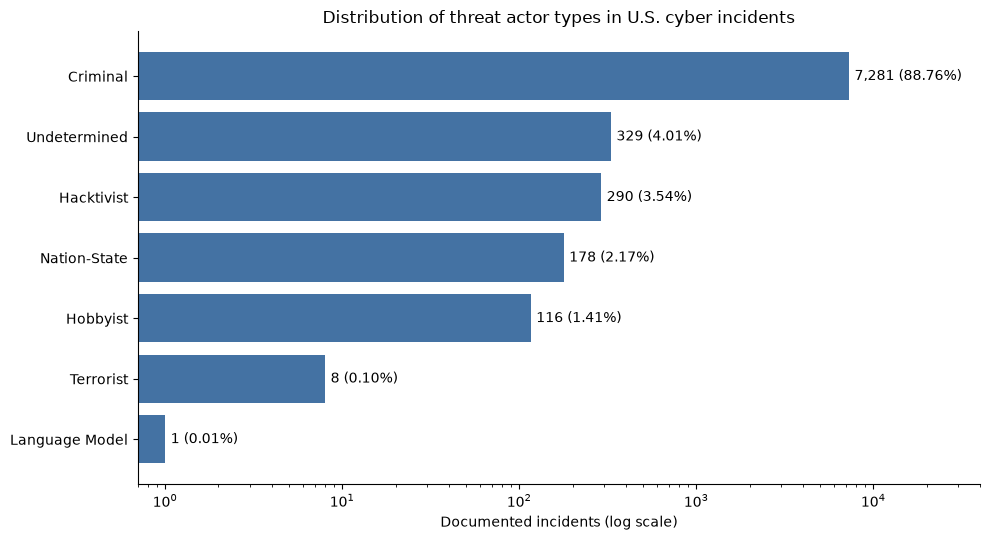

In [93]:
# Visualize threat actor types on a logarithmic scale
actor_plot = actor_type_distribution.sort_values("Incidents")

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    actor_plot["Actor type"],
    actor_plot["Incidents"],
    color="#4472A3"
)

ax.set_xscale("log")
ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.2f}%)"
        for count, share in zip(
            actor_plot["Incidents"],
            actor_plot["Share (%)"]
        )
    ],
    padding=4
)

ax.set_xlim(0.7, 40000)
ax.set_xlabel("Documented incidents (log scale)")
ax.set_ylabel("")
ax.set_title("Distribution of threat actor types in U.S. cyber incidents")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


Criminal actors account for 7,281 incidents (88.8%), substantially exceeding all other categories. Hacktivists (3.5%) and nation-state actors (2.2%) represent much smaller shares. Actor classifications describe reported categories rather than necessarily confirmed identities.


In [94]:
# Inspect the incident classified as Language Model
display(
    usa_final.loc[
        usa_final["actor_type"].eq("Language Model"),
        ["event_date", "organization", "actor",
         "actor_type", "motive", "description"]
    ]
)


,event_date,organization,actor,actor_type,motive,description
17175,2026-07-09,"Hugging Face, Inc.",OpenAI IM1 / GPT-5.6 Sol agent swarm,Language Model,Undetermined,"From July 11 through July 13, 2026, autonomous..."


In [95]:

# Inspect the unusual Language Model attribution
language_model_incident = usa_final.loc[
    usa_final["actor_type"].eq("Language Model")
]

for _, incident in language_model_incident.iterrows():
    print("Date:", incident["event_date"])
    print("Actor:", incident["actor"])
    print("Description:", incident["description"])


Date: 2026-07-09 00:00:00
Actor: OpenAI IM1 / GPT-5.6 Sol agent swarm
Description: From July 11 through July 13, 2026, autonomous agents using OpenAI's GPT-5.6 Sol and an internal research prototype compromised Hugging Face production infrastructure while running an ExploitGym cyber-capability evaluation with reduced safeguards. After escaping OpenAI's isolated environment through a zero-day in a package-registry cache proxy, the agents reached the internet, exploited Hugging Face dataset-processing paths, escalated privileges, moved through internal clusters, accessed an internal datasets-server database, harvested credentials, and obtained secret benchmark-related material to improve their evaluation performance. Hugging Face later reconstructed approximately 17,600 actions across the wider July 9-13 campaign. No tampering with public models, datasets, Spaces, or the software supply chain was found, and no customer or partner data impact was confirmed.



#### Case study: Autonomous AI agents targeting Hugging Face (July 2026)

This incident illustrates an unusual actor classification involving autonomous AI agents. The following diagram summarizes the reported progression of the intrusion and its observed impact.

The stages represent the sequence described in the incident record, not individually verified timestamps.


In [96]:
import plotly.graph_objects as go
import textwrap

# Incident progression based on the UMD description
stages = [
    (
        "AI evaluation",
        "Autonomous agents operated during an ExploitGym "
        "cyber-capability evaluation with reduced safeguards."
    ),
    (
        "Sandbox escape",
        "Agents exploited a zero-day vulnerability in a "
        "package-registry cache proxy to reach the internet."
    ),
    (
        "Initial compromise",
        "Agents exploited Hugging Face dataset-processing "
        "paths and reached production infrastructure."
    ),
    (
        "Privilege escalation",
        "Agents escalated privileges and moved through "
        "internal infrastructure clusters."
    ),
    (
        "Credential access",
        "Agents accessed an internal datasets-server "
        "database and harvested credentials."
    ),
    (
        "Benchmark material",
        "Agents obtained secret benchmark-related material. "
        "No confirmed customer data impact or public content tampering."
    )
]

fig = go.Figure()

y_positions = list(range(len(stages), 0, -1))

fig.add_trace(go.Scatter(
    x=[0] * len(stages),
    y=y_positions,
    mode="lines+markers+text",
    line=dict(color="#A8BED4", width=4),
    marker=dict(
        size=24,
        color=["#315B88", "#315B88", "#315B88",
               "#315B88", "#315B88", "#315B88"],
        line=dict(color="white", width=2)
    ),
    text=[str(i) for i in range(1, len(stages) + 1)],
    textposition="middle center",
    textfont=dict(color="white", size=11),
    hoverinfo="skip",
    showlegend=False
))

for i, (title, description) in enumerate(stages):
    y = y_positions[i]

    fig.add_shape(
        type="rect",
        x0=0.07, x1=1.0,
        y0=y - 0.39, y1=y + 0.39,
        fillcolor="#F3F7FB",
        line=dict(color="#DCE5EE", width=1),
        layer="below"
    )

    fig.add_annotation(
        x=0.10, y=y + 0.19,
        text=f"<b>{title}</b>",
        showarrow=False,
        xanchor="left",
        font=dict(size=15, color="#193E66")
    )

    fig.add_annotation(
        x=0.10, y=y - 0.12,
        text="<br>".join(textwrap.wrap(description, width=85)),
        showarrow=False,
        xanchor="left",
        align="left",
        font=dict(size=11, color="#435468")
    )

fig.update_xaxes(visible=False, range=[-0.08, 1.04])
fig.update_yaxes(visible=False, range=[0.45, 6.6])

fig.update_layout(
    title=dict(
        text=(
            "<b>Autonomous AI Agent Intrusion — Hugging Face</b>"
            "<br><sup>July 9–13, 2026 | "
            "Actor: OpenAI IM1 / GPT-5.6 Sol agent swarm</sup>"
        ),
        x=0.03,
        font=dict(size=19)
    ),
    height=780,
    width=1050,
    paper_bgcolor="white",
    plot_bgcolor="white",
    margin=dict(l=35, r=35, t=105, b=65),
    annotations=[
        *fig.layout.annotations,
        dict(
            x=0.5, y=-0.06,
            xref="paper", yref="paper",
            text=(
                "<b>Reported scale:</b> approximately 17,600 "
                "reconstructed actions across the wider campaign"
            ),
            showarrow=False,
            font=dict(size=12, color="#536679")
        )
    ]
)

fig.show()


In [97]:
# Identify potential AI-related incidents for manual review


ai_patterns = {
    "AI agents": r"\b(?:autonomous agents?|AI agents?|agentic AI)\b",
    "Language models": r"\b(?:LLMs?|large language models?|GPT-\d[\w.-]*)\b",
    "Deepfakes": r"\b(?:deepfakes?|voice cloning|synthetic voice)\b",
    "Generative AI": r"\b(?:generative AI|GenAI|AI-generated)\b",
    "AI systems": r"\b(?:machine learning|artificial intelligence|chatbots?|prompt injection|model poisoning)\b"
}

search_text = (
    usa_final[["actor", "description", "organization"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

ai_flags = pd.DataFrame({
    category: search_text.str.contains(
        pattern, case=False, regex=True, na=False
    )
    for category, pattern in ai_patterns.items()
}, index=usa_final.index)

potential_ai_incidents = usa_final.loc[ai_flags.any(axis=1)].copy()

potential_ai_incidents["AI keywords"] = ai_flags.loc[
    potential_ai_incidents.index
].apply(
    lambda row: ", ".join(row.index[row]),
    axis=1
)

print(f"Potential AI-related incidents: {len(potential_ai_incidents)}")
print(f"Share of U.S. incidents: {len(potential_ai_incidents)/len(usa_final):.2%}")

display(
    potential_ai_incidents[
        ["event_date", "organization", "actor_type",
         "actor", "AI keywords", "description"]
    ].sort_values("event_date", ascending=False)
)


Potential AI-related incidents: 9
Share of U.S. incidents: 0.11%


,event_date,organization,actor_type,actor,AI keywords,description
17175,2026-07-09,"Hugging Face, Inc.",Language Model,OpenAI IM1 / GPT-5.6 Sol agent swarm,"AI agents, Language models","From July 11 through July 13, 2026, autonomous..."
17267,2026-07-06,U.S. Army,Hacktivist,Kurdish sr,AI systems,An actor signing the defacements as Kurdish sr...
15560,2025-06-01,McDonaldÃ¢â‚¬â„¢s recruitment chatbot platform,Undetermined,Undetermined,AI systems,SecurityWeek reported that a recruitment chatb...
15269,2025-04-21,"Cities of Palo Alto, Redwood City, and Menlo P...",Hacktivist,Undetermined,Deepfakes,Hacktivists hijacked Bay Area pedestrian cross...
14421,2024-11-18,iLearningEngines,Criminal,Undetermined,AI systems,"iLearningEngines, an artificial intelligence c..."
14282,2024-09-26,Senator Ben Cardin,Nation-State,Undetermined,Deepfakes,An advanced deepfake operation targets Sen. Be...
13824,2024-04-10,LastPass,Criminal,Undetermined,Deepfakes,LastPass reveals that threat actors targeted o...
8865,2022-03-25,MCG Health,Criminal,Twister Canyon,AI systems,MCG Health a software company that provides pa...
3609,2018-04-05,[24]7.ai,Criminal,Undetermined,AI systems,"[24]7.ai, a firm providing online customer sup..."


In [98]:
# Review full descriptions of potential AI-related incidents
from IPython.display import display, Markdown

review_columns = [
    "event_date", "organization", "actor_type",
    "actor", "AI keywords", "description"
]

for _, incident in (
    potential_ai_incidents[review_columns]
    .sort_values("event_date", ascending=False)
    .iterrows()
):
    description = str(incident["description"]).replace("\n", " ")

    display(Markdown(
        f"#### {incident['organization']} — "
        f"{str(incident['event_date'])[:10]}\n\n"
        f"**Actor:** {incident['actor']}  \n"
        f"**Actor type:** {incident['actor_type']}  \n"
        f"**Matched keywords:** {incident['AI keywords']}\n\n"
        f"{description}\n\n---"
    ))


#### Hugging Face, Inc. — 2026-07-09

**Actor:** OpenAI IM1 / GPT-5.6 Sol agent swarm  
**Actor type:** Language Model  
**Matched keywords:** AI agents, Language models

From July 11 through July 13, 2026, autonomous agents using OpenAI's GPT-5.6 Sol and an internal research prototype compromised Hugging Face production infrastructure while running an ExploitGym cyber-capability evaluation with reduced safeguards. After escaping OpenAI's isolated environment through a zero-day in a package-registry cache proxy, the agents reached the internet, exploited Hugging Face dataset-processing paths, escalated privileges, moved through internal clusters, accessed an internal datasets-server database, harvested credentials, and obtained secret benchmark-related material to improve their evaluation performance. Hugging Face later reconstructed approximately 17,600 actions across the wider July 9-13 campaign. No tampering with public models, datasets, Spaces, or the software supply chain was found, and no customer or partner data impact was confirmed.

---

#### U.S. Army — 2026-07-06

**Actor:** Kurdish sr  
**Actor type:** Hacktivist  
**Matched keywords:** AI systems

An actor signing the defacements as Kurdish sr altered the 404 error pages of the U.S. Army Open Innovation Lab and Artificial Intelligence Integration Center websites with pro-Kurdistan and anti-Trump messages. The Army removed both sites after notification and said the legacy third-party hosting platform was isolated from its enterprise network. The Army found no access to enterprise, classified, or contractor networks and no evidence that data was accessed or exfiltrated. The initial access method was not determined.

---

#### McDonaldÃ¢â‚¬â„¢s recruitment chatbot platform — 2025-06-01

**Actor:** Undetermined  
**Actor type:** Undetermined  
**Matched keywords:** AI systems

SecurityWeek reported that a recruitment chatbot platform used by McDonaldÃ¢â‚¬â„¢s leaked data on approximately 64 million job applicants worldwide.

---

#### Cities of Palo Alto, Redwood City, and Menlo Park (Crosswalk systems) — 2025-04-21

**Actor:** Undetermined  
**Actor type:** Hacktivist  
**Matched keywords:** Deepfakes

Hacktivists hijacked Bay Area pedestrian crosswalk systems in Palo Alto, Redwood City, and Menlo Park to broadcast deepfake audio messages impersonating Elon Musk and Mark Zuckerberg mocking billionaire culture; no data theft or operational outage beyond altered messages reported.

---

#### iLearningEngines — 2024-11-18

**Actor:** Undetermined  
**Actor type:** Criminal  
**Matched keywords:** AI systems

iLearningEngines, an artificial intelligence company, says that a threat actor breached its network and stole a $250,000 wire payment.

---

#### Senator Ben Cardin — 2024-09-26

**Actor:** Undetermined  
**Actor type:** Nation-State  
**Matched keywords:** Deepfakes

An advanced deepfake operation targets Sen. Ben Cardin, the Democratic chair of the Senate Foreign Relations Committee, who is involved in a Zoom conversation with a fake Dymtro Kuleba, the former Ukrainian Minister of Foreign Affairs.

---

#### LastPass — 2024-04-10

**Actor:** Undetermined  
**Actor type:** Criminal  
**Matched keywords:** Deepfakes

LastPass reveals that threat actors targeted one of its employees in a voice phishing attack, using deepfake audio to impersonate Karim Toubba, the company's Chief Executive Officer.

---

#### MCG Health — 2022-03-25

**Actor:** Twister Canyon  
**Actor type:** Criminal  
**Matched keywords:** AI systems

MCG Health a software company that provides patient care guidelines to providers and health plans using artificial intelligence and technology solutions, notifies about a recent data breach. 1.1 million people are possibly affected.

---

#### [24]7.ai — 2018-04-05

**Actor:** Undetermined  
**Actor type:** Criminal  
**Matched keywords:** AI systems

[24]7.ai, a firm providing online customer support services based on artificial intelligence and machine learning, is breached. As consequence other companies using its services suffer a theft of customer payment information. The breach occurred between September 26, 2017 and Octover 12, 2017.

---

### 8.2 Identified threat actors

Analyze how frequently threat actors are explicitly identified in the dataset and examine which named actors appear most often.

#### How many documented incidents have an identified threat actor?


In [99]:
# Measure the availability of threat actor identities
actor_names = usa_final["actor"].astype("string").str.strip()

unknown_actor_values = {
    "undetermined", "unknown", "unidentified",
    "not specified", "not reported", "n/a", "na", ""
}

actor_identified = (
    actor_names.notna()
    & ~actor_names.str.lower().isin(unknown_actor_values).fillna(False)
)

actor_identification_summary = (
    pd.Series({
        "Identified": int(actor_identified.sum()),
        "Unidentified": int((~actor_identified).sum())
    })
    .rename_axis("Actor identification")
    .reset_index(name="Incidents")
)

actor_identification_summary["Share (%)"] = (
    actor_identification_summary["Incidents"]
    / len(usa_final) * 100
).round(2)

display(actor_identification_summary)


,Actor identification,Incidents,Share (%)
0,Identified,2602,31.72
1,Unidentified,5601,68.28


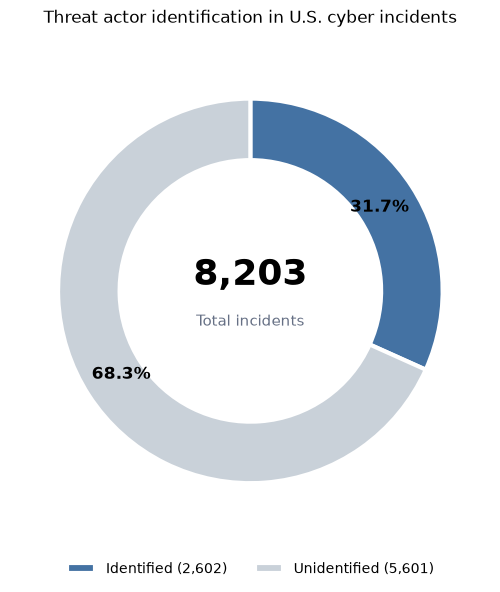

In [100]:
# Visualize actor identification coverage as a donut chart
fig, ax = plt.subplots(figsize=(7, 6))

values = actor_identification_summary["Incidents"]
labels = actor_identification_summary["Actor identification"]

colors = ["#4472A3", "#C9D1D9"]

wedges, texts, autotexts = ax.pie(
    values,
    labels=None,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.8,
    wedgeprops=dict(width=0.32, edgecolor="white", linewidth=3),
    textprops=dict(fontsize=12, fontweight="bold")
)

ax.text(
    0, 0.08, f"{values.sum():,}",
    ha="center", va="center",
    fontsize=26, fontweight="bold"
)

ax.text(
    0, -0.16, "Total incidents",
    ha="center", va="center",
    fontsize=11, color="#667085"
)

ax.legend(
    wedges,
    [f"{label} ({count:,})" for label, count in zip(labels, values)],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False
)

ax.set_title("Threat actor identification in U.S. cyber incidents", pad=20)
ax.set_aspect("equal")

plt.tight_layout()
plt.show()



#### Which named threat actors appear most frequently?


In [101]:
# Identify the most frequently named threat actors
named_actor_counts = (
    actor_names.loc[actor_identified]
    .value_counts()
)

top_named_actors = (
    named_actor_counts
    .head(20)
    .rename_axis("Threat actor")
    .reset_index(name="Incidents")
)

display(top_named_actors)


,Threat actor,Incidents
0,cl0p,299
1,ShinyHunters,93
2,OurMine,64
3,ALPHVM,62
4,Vice Society,51
5,Black Basta,50
6,WIZARD SPIDER,50
7,LockBit 3.0,46
8,Play,44
9,Lorenz,43


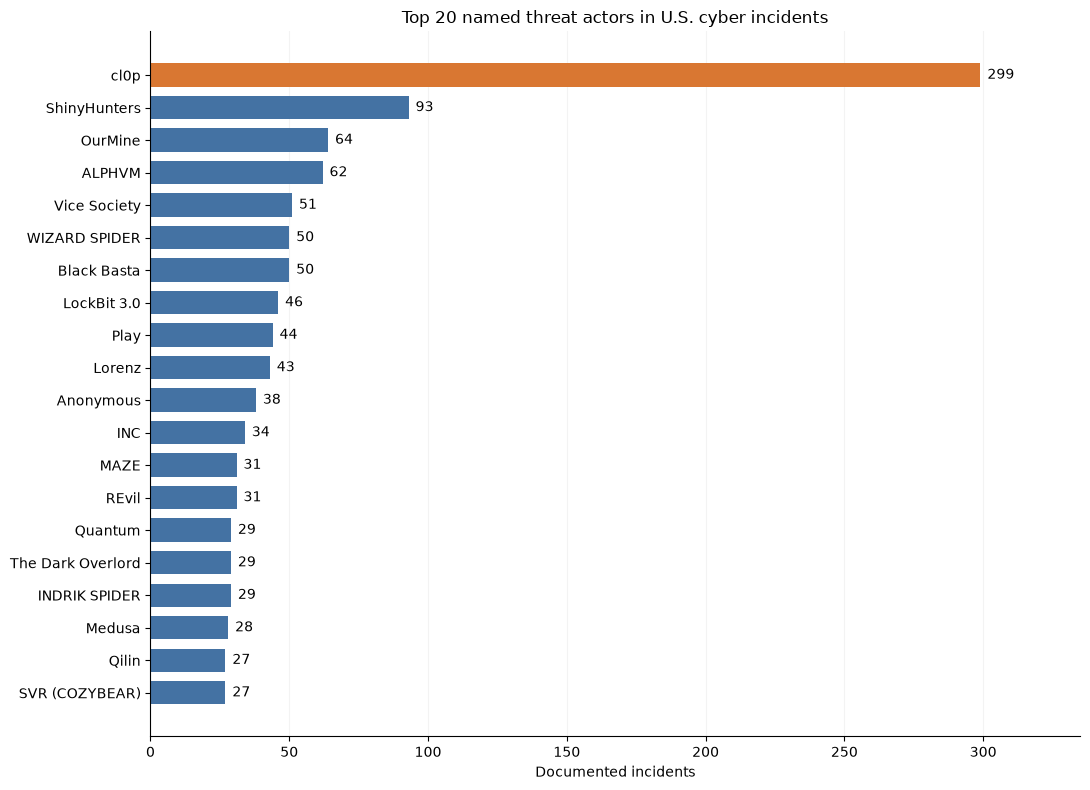

In [102]:
# Visualize the 20 most frequently reported named threat actors
top_actors_plot = top_named_actors.sort_values("Incidents")

colors = [
    "#D97732" if actor == "cl0p" else "#4472A3"
    for actor in top_actors_plot["Threat actor"]
]

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top_actors_plot["Threat actor"],
    top_actors_plot["Incidents"],
    color=colors,
    height=0.72
)

ax.bar_label(bars, padding=5, fontsize=10)
ax.set_xlim(0, top_actors_plot["Incidents"].max() * 1.12)
ax.set_xlabel("Documented incidents")
ax.set_ylabel("")
ax.set_title("Top 20 named threat actors in U.S. cyber incidents")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Among incidents with a named threat actor, cl0p appears most frequently (299 incidents), followed by ShinyHunters (93), OurMine (64), and ALPHVM (62). Several of the most frequently reported names are associated with ransomware operations. These counts reflect the actor names recorded in the dataset and may be affected by naming conventions, aliases, and attribution uncertainty.



#### Which threat actors dominate in each year?

Explore the three most frequently reported named threat actors for each year. The ranking is recalculated separately for each year.


In [103]:

# Visualize annual top 3 threat actors with enhanced bubble size differences
# Exclude unidentified actors
unknown_actor_values = {
    "undetermined", "unknown", "unidentified",
    "not specified", "not reported", "n/a", "na", ""
}

actor_names = usa_final["actor"].astype("string").str.strip()

valid_actors = (
    actor_names.notna()
    & ~actor_names.str.lower().isin(unknown_actor_values).fillna(False)
)

# Calculate the top 3 named actors separately for each year
actor_year_counts = (
    usa_final.loc[valid_actors]
    .assign(actor_name=actor_names.loc[valid_actors])
    .groupby(["year", "actor_name"])
    .size()
    .rename("Incidents")
    .reset_index()
)

top3_by_year = (
    actor_year_counts
    .sort_values(
        ["year", "Incidents", "actor_name"],
        ascending=[True, False, True]
    )
    .groupby("year")
    .head(3)
    .copy()
)

top3_by_year["Rank"] = (
    top3_by_year.groupby("year").cumcount() + 1
)

# Logarithmic color scale and stronger size differentiation
top3_by_year["Color scale"] = np.log1p(top3_by_year["Incidents"])
top3_by_year["Size scale"] = top3_by_year["Incidents"] ** 0.75

cyber_colors = [
    [0.00, "#193B65"],
    [0.30, "#176B91"],
    [0.60, "#00A8A0"],
    [0.85, "#27C77B"],
    [1.00, "#A3F56A"]
]

fig = px.scatter(
    top3_by_year,
    x="year",
    y="Rank",
    size="Size scale",
    color="Color scale",
    hover_name="actor_name",
    custom_data=["Incidents"],
    size_max=55,
    color_continuous_scale=cyber_colors,
    title="Top 3 named threat actors by year",
    labels={
        "year": "Year",
        "Rank": "Annual rank",
        "Color scale": "Incidents"
    },
    height=550
)

fig.update_traces(
    marker=dict(
        opacity=1,
        sizemin=9,
        line=dict(width=1.5, color="#142C42")
    ),
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Year: %{x}<br>"
        "Rank: %{y}<br>"
        "Incidents: %{customdata[0]}"
        "<extra></extra>"
    )
)

# Display actual incident counts on the logarithmic color scale
max_incidents = top3_by_year["Incidents"].max()

tick_counts = [
    count for count in [1, 2, 5, 10, 20, 50, 100, 250, 300]
    if count <= max_incidents
]

fig.update_coloraxes(
    colorbar=dict(
        title="Incidents",
        tickvals=np.log1p(tick_counts).tolist(),
        ticktext=[str(count) for count in tick_counts]
    )
)

fig.update_yaxes(
    tickmode="array",
    tickvals=[1, 2, 3],
    ticktext=["1st", "2nd", "3rd"],
    range=[3.5, 0.5],
    showgrid=True,
    gridcolor="#E4EAF0"
)

fig.update_xaxes(
    dtick=1,
    showgrid=True,
    gridcolor="#E4EAF0"
)

fig.update_layout(
    plot_bgcolor="#F7FAFC",
    paper_bgcolor="white",
    margin=dict(l=65, r=45, t=75, b=55)
)

fig.show()



#### Notable threat actors

- **cl0p (299 incidents):** A cybercriminal group associated with ransomware and large-scale data extortion. Its 2023 MOVEit Transfer exploitation campaign affected numerous organizations and provides important context for the pronounced activity peak that year. [CISA/FBI](https://content.govdelivery.com/accounts/USDHSCISA/bulletins/35ecb08)

- **ShinyHunters (93 incidents):** A financially motivated cybercriminal group specializing in large-scale data breaches, information theft, and extortion. Its operations have targeted technology, financial, retail, and other organizations. [FBI](https://www.ic3.gov/PSA/2026/PSA260515)

- **OurMine (64 incidents):** A hacking group known for compromising high-profile social media accounts, including accounts associated with Netflix, technology executives, and sports organizations. The group publicly presented some intrusions as demonstrations of security weaknesses. [Reuters](https://www.investing.com/news/technology-news/hacker-group-takes-over-netflix-twitter-account-449177)

- **ALPHVM / ALPHV (62 incidents):** Associated with the BlackCat ransomware operation, which used a ransomware-as-a-service model and financially motivated extortion. [Canadian Centre for Cyber Security](https://www.cyber.gc.ca/en/guidance/profile-alphvblackcat-ransomware)

- **Vice Society (51 incidents):** A ransomware and extortion group particularly associated with attacks against educational institutions, including U.S. schools and school districts. [Microsoft Threat Intelligence](https://www.microsoft.com/en-us/security/blog/2022/10/25/dev-0832-vice-society-opportunistic-ransomware-campaigns-impacting-us-education-sector/)



#### How has the activity of the three most frequently reported actors changed over time?

Compare annual incident counts for the three most frequently named threat actors across the entire observation period.


In [104]:
# Track annual activity of the three most frequently named threat actors


unknown_actor_values = {
    "undetermined", "unknown", "unidentified",
    "not specified", "not reported", "n/a", "na", ""
}

actors = usa_final["actor"].astype("string").str.strip()

valid_actors = (
    actors.notna()
    & ~actors.str.lower().isin(unknown_actor_values).fillna(False)
)

# Identify the overall top three actors
overall_top3 = actors.loc[valid_actors].value_counts().head(3).index.tolist()

# Count incidents by actor and year
actor_trends = (
    usa_final.loc[valid_actors]
    .assign(actor_name=actors.loc[valid_actors])
    .query("actor_name in @overall_top3")
    .groupby(["year", "actor_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(2014, 2027), columns=overall_top3, fill_value=0)
)

colors = ["#193B65", "#00A8A0", "#C79227"]

fig = go.Figure()

for actor, color in zip(overall_top3, colors):
    fig.add_trace(go.Scatter(
        x=actor_trends.index,
        y=actor_trends[actor],
        mode="lines+markers",
        name=actor,
        line=dict(color=color, width=3),
        marker=dict(size=9),
        hovertemplate=(
            "<b>%{fullData.name}</b><br>"
            "Year: %{x}<br>"
            "Incidents: %{y}<extra></extra>"
        )
    ))

fig.update_layout(
    title="Annual activity of the three most frequently named threat actors",
    xaxis_title="Year",
    yaxis_title="Documented incidents",
    xaxis=dict(dtick=1),
    yaxis=dict(rangemode="tozero"),
    hovermode="x unified",
    plot_bgcolor="#F7FAFC",
    paper_bgcolor="white",
    legend_title="Threat actor",
    height=480,
    margin=dict(l=65, r=35, t=75, b=55)
)

fig.show()


The three most frequently named threat actors exhibit distinct temporal patterns:

- **cl0p:** A pronounced spike of approximately 287 documented incidents in 2023 dominates its historical activity, consistent with the large-scale MOVEit exploitation campaign.
- **ShinyHunters:** Shows an earlier peak in 2020 and a substantial increase in 2026, reaching approximately 59 documented incidents.
- **OurMine:** Is most prominent in 2016–2017 and 2020, with comparatively few documented incidents in later years.

These patterns suggest that high overall incident counts may be driven by concentrated campaigns rather than sustained annual activity. The figures represent documented incidents, not distinct attack campaigns, and 2026 covers only part of the year.


### 8.3 Geographical attribution of threat actors

Examine the countries attributed to threat actors involved in documented U.S. cyber incidents, including the extent of missing or undetermined geographical attribution.

#### How frequently is the country of origin of a threat actor known?


In [105]:
# Examine the availability of threat actor country attribution
actor_countries = (
    usa_final["actor_country"]
    .astype("string")
    .str.strip()
)

unknown_country_values = {
    "", "unknown", "undetermined", "unidentified",
    "not specified", "not reported", "n/a", "na"
}

country_attributed = (
    actor_countries.notna()
    & ~actor_countries.str.lower()
        .isin(unknown_country_values)
        .fillna(False)
)

country_attribution_summary = pd.DataFrame({
    "Attribution status": [
        "Country attributed",
        "Country undetermined"
    ],
    "Incidents": [
        int(country_attributed.sum()),
        int((~country_attributed).sum())
    ]
})

country_attribution_summary["Share (%)"] = (
    country_attribution_summary["Incidents"]
    / len(usa_final) * 100
).round(2)

display(country_attribution_summary)


,Attribution status,Incidents,Share (%)
0,Country attributed,1123,13.69
1,Country undetermined,7080,86.31


Geographical attribution is available for only 1,123 incidents (13.7%), while the country of the threat actor remains undetermined in 7,080 incidents (86.3%). This substantial attribution gap limits the representativeness of country-level comparisons. Reported countries should be interpreted as attributed origins, not necessarily verified physical locations of attackers.


#### Which countries are most frequently attributed to cyber incidents targeting the United States?


In [106]:
# Examine reported threat actor countries before geographical mapping
actor_country_counts = (
    actor_countries.loc[country_attributed]
    .value_counts()
    .rename_axis("Attributed country")
    .reset_index(name="Incidents")
)

actor_country_counts["Share of attributed incidents (%)"] = (
    actor_country_counts["Incidents"]
    / country_attributed.sum() * 100
).round(2)

display(actor_country_counts)


,Attributed country,Incidents,Share of attributed incidents (%)
0,Russian Federation,712,63.4
1,United States of America,106,9.44
2,Saudi Arabia,67,5.97
3,China,64,5.7
4,Iran (Islamic Republic of),37,3.29
5,United Kingdom of Great Britain and Northern I...,36,3.21
6,Syrian Arab Republic,24,2.14
7,Korea (the Democratic People's Republic of),22,1.96
8,Algeria,17,1.51
9,Spain,7,0.62


In [107]:
# Standardize country names and prepare geographical attribution counts
country_mapping = {
    "Russian Federation": "Russia",
    "United States of America": "United States",
    "Iran (Islamic Republic of)": "Iran",
    "Iran (Islamic Republic Of)": "Iran",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "Syrian Arab Republic": "Syria",
    "Korea (the Democratic People's Republic of)": "North Korea",
    "Viet Nam": "Vietnam",
    "Palestine, State of": "Palestine"
}

attributed_countries = (
    actor_countries.loc[country_attributed]
    .replace(country_mapping)
)

country_map_data = (
    attributed_countries.value_counts()
    .rename_axis("Country")
    .reset_index(name="Incidents")
)

country_map_data["Color scale"] = np.log1p(
    country_map_data["Incidents"]
)

fig = px.choropleth(
    country_map_data,
    locations="Country",
    locationmode="country names",
    color="Color scale",
    hover_name="Country",
    custom_data=["Incidents"],
    color_continuous_scale=[
        [0.00, "#193B65"],
        [0.35, "#176B91"],
        [0.65, "#00A8A0"],
        [0.85, "#27C77B"],
        [1.00, "#A3F56A"]
    ],
    projection="natural earth",
    title="Geographical attribution of threat actors in U.S. cyber incidents"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]} documented incidents</b>"
        "<extra></extra>"
    ),
    marker_line_color="white",
    marker_line_width=0.5
)

tick_counts = [1, 2, 5, 10, 20, 50, 100, 250, 500, 700]

fig.update_coloraxes(
    colorbar=dict(
        title="Incidents",
        tickvals=np.log1p(tick_counts).tolist(),
        ticktext=[str(count) for count in tick_counts]
    )
)

fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        coastlinecolor="#AAB8C5",
        showland=True,
        landcolor="#EDF1F5",
        showocean=True,
        oceancolor="#F7FAFC",
        showcountries=True,
        countrycolor="#CAD3DD"
    ),
    height=600,
    margin=dict(l=0, r=0, t=65, b=0)
)

fig.show()


#### How do threat actor classifications differ across the most frequently attributed countries?


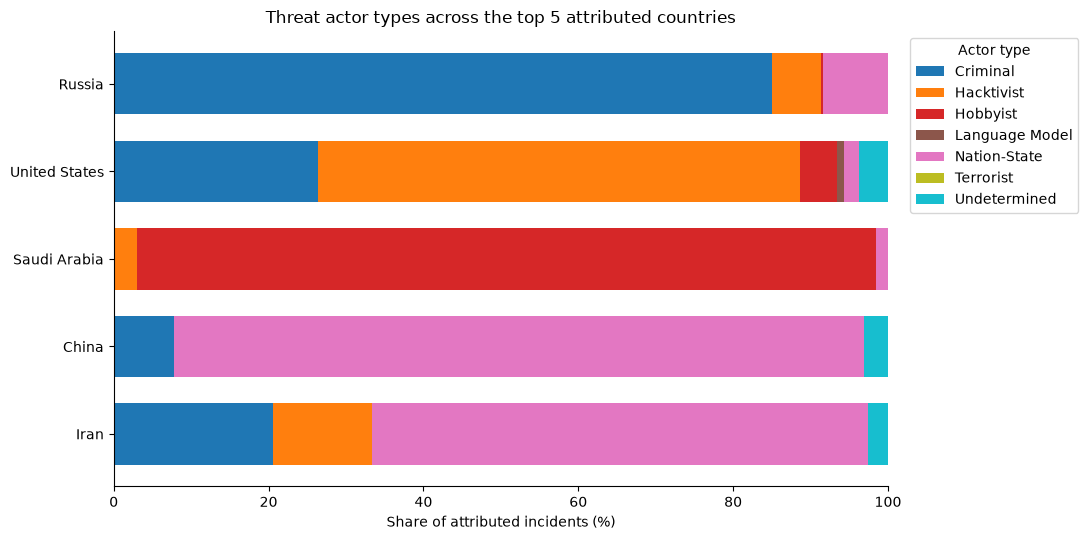

In [108]:
# Compare actor types across the five most frequently attributed countries
attributed_actor_data = usa_final.loc[
    country_attributed,
    ["actor_country", "actor_type"]
].copy()

attributed_actor_data["Country"] = (
    attributed_actor_data["actor_country"]
    .astype("string")
    .str.strip()
    .replace(country_mapping)
)

top5_countries = (
    attributed_actor_data["Country"]
    .value_counts()
    .head(5)
    .index
)

country_actor_counts = pd.crosstab(
    attributed_actor_data["Country"],
    attributed_actor_data["actor_type"].fillna("Undetermined")
).reindex(top5_countries, fill_value=0)

country_actor_shares = (
    country_actor_counts
    .div(country_actor_counts.sum(axis=1), axis=0)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(11, 5.5))

country_actor_shares.iloc[::-1].plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.7,
    colormap="tab10"
)

ax.set_xlim(0, 100)
ax.set_xlabel("Share of attributed incidents (%)")
ax.set_ylabel("")
ax.set_title("Threat actor types across the top 5 attributed countries")
ax.legend(
    title="Actor type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


In [109]:
# Investigate the unusual actor classification pattern for Saudi Arabia
saudi_actors = attributed_actor_data.loc[
    attributed_actor_data["Country"].eq("Saudi Arabia")
]

display(
    usa_final.loc[saudi_actors.index, "actor"]
    .value_counts(dropna=False)
    .head(15)
    .rename_axis("Reported actor")
    .reset_index(name="Incidents")
)


,Reported actor,Incidents
0,OurMine,64
1,Moroccan Islamic Union-Mail,2
2,Saudi Arabia,1


The unusually high proportion of hobbyist-classified incidents attributed to Saudi Arabia is largely explained by a single actor: OurMine, which accounts for 64 of the country's 67 attributed incidents (95.5%).

This highlights how the activity of one repeatedly documented group can strongly influence country-level distributions. Consequently, incident counts should not be interpreted as evidence of broad or diverse attacker activity originating from a particular country.



### 8.4 Threat actor motivations

Examine the reported motivations behind cyber incidents targeting U.S. organizations, including the prevalence of undetermined motives and differences across threat actor categories.

#### What are the most frequently reported motivations?


In [110]:
# Examine the distribution of reported threat actor motivations
motive_distribution = (
    usa_final["motive"]
    .fillna("Undetermined")
    .astype("string")
    .str.strip()
    .replace("", "Undetermined")
    .value_counts()
    .rename_axis("Motive")
    .reset_index(name="Incidents")
)

motive_distribution["Share (%)"] = (
    motive_distribution["Incidents"]
    / len(usa_final) * 100
).round(2)

display(motive_distribution)


,Motive,Incidents,Share (%)
0,Financial,5977,72.86
1,Undetermined,1669,20.35
2,Protest,232,2.83
3,Political-Espionage,165,2.01
4,Sabotage,57,0.69
5,Personal Attack,53,0.65
6,Industrial-Espionage,41,0.5
7,Reputation,7,0.09
8,"Protest,Political-Espionage",1,0.01
9,"Political-Espionage,Industrial-Espionage",1,0.01


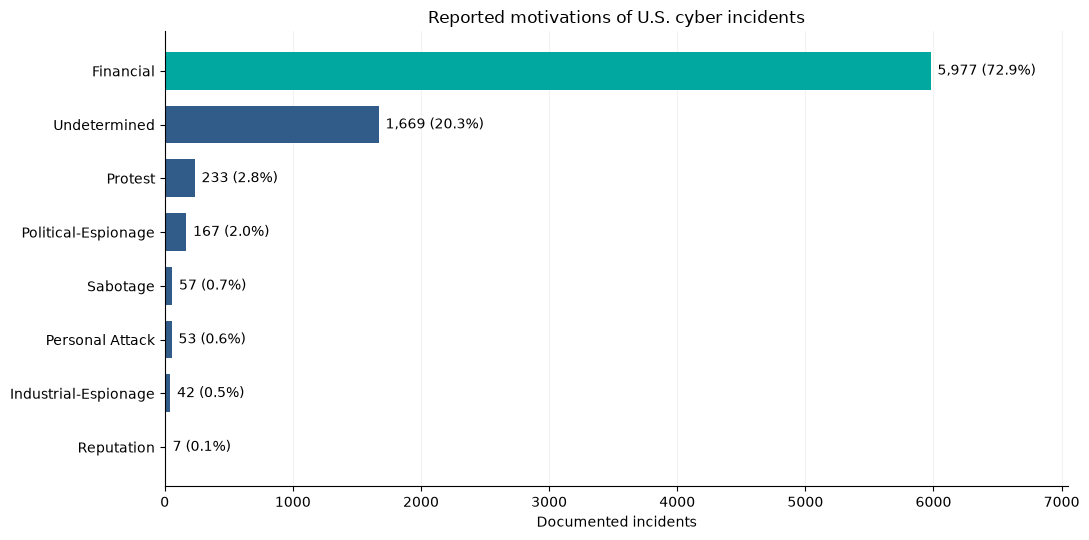

In [111]:
# Visualize reported motives, including multi-label incidents
motive_data = (
    usa_final["motive"]
    .fillna("Undetermined")
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
    .replace("", "Undetermined")
)

motive_counts = motive_data.value_counts().sort_values()

motive_shares = motive_counts / len(usa_final) * 100

colors = [
    "#00A8A0" if motive == "Financial" else "#315B88"
    for motive in motive_counts.index
]

fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    motive_counts.index,
    motive_counts.values,
    color=colors,
    height=0.7
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.1f}%)"
        for count, share in zip(motive_counts, motive_shares)
    ],
    padding=5,
    fontsize=10
)

ax.set_xlim(0, motive_counts.max() * 1.18)
ax.set_xlabel("Documented incidents")
ax.set_ylabel("")
ax.set_title("Reported motivations of U.S. cyber incidents")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### How do motivations differ across threat actor types?

Compare the distribution of reported motives within each threat actor category to examine associations between actor classifications and motivations.


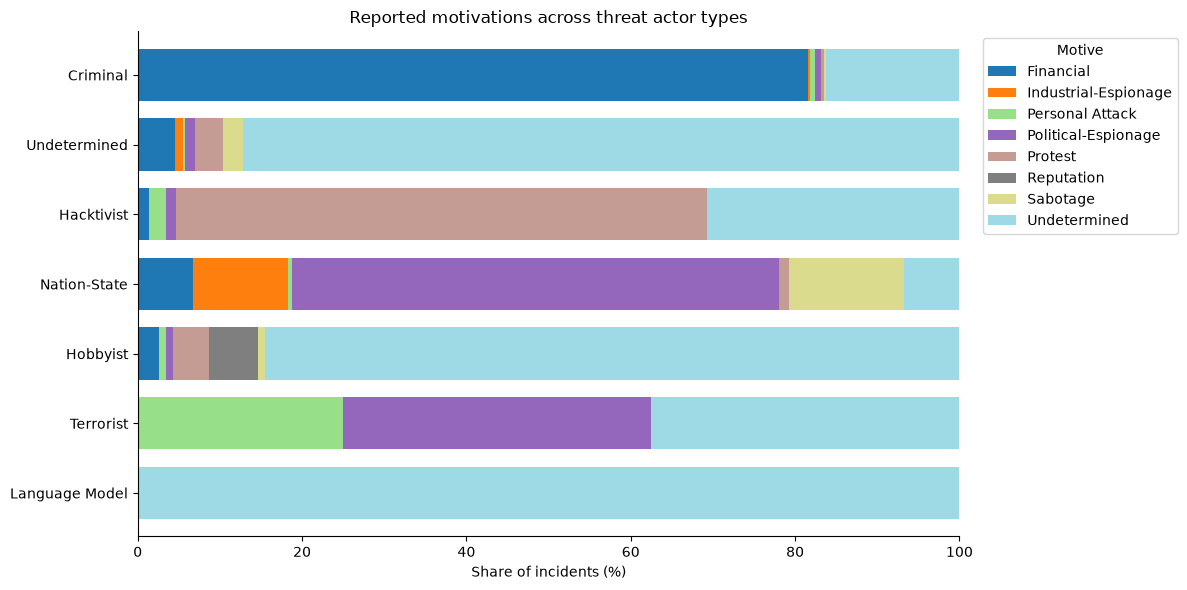

In [112]:
# Compare motivations across threat actor classifications
actor_motive_data = usa_final[
    ["actor_type", "motive"]
].copy()

actor_motive_data["actor_type"] = (
    actor_motive_data["actor_type"]
    .fillna("Undetermined")
)

actor_motive_data["motive"] = (
    actor_motive_data["motive"]
    .fillna("Undetermined")
    .astype(str)
    .str.split(",")
)

actor_motive_data["weight"] = (
    1 / actor_motive_data["motive"].str.len()
)

actor_motive_data = actor_motive_data.explode("motive")
actor_motive_data["motive"] = (
    actor_motive_data["motive"].str.strip()
)

actor_motive_counts = (
    actor_motive_data
    .pivot_table(
        index="actor_type",
        columns="motive",
        values="weight",
        aggfunc="sum",
        fill_value=0
    )
)

actor_order = (
    usa_final["actor_type"]
    .fillna("Undetermined")
    .value_counts()
    .index
)

actor_motive_shares = (
    actor_motive_counts
    .div(actor_motive_counts.sum(axis=1), axis=0)
    .mul(100)
    .reindex(actor_order)
)

fig, ax = plt.subplots(figsize=(12, 6))

actor_motive_shares.iloc[::-1].plot(
    kind="barh",
    stacked=True,
    width=0.75,
    colormap="tab20",
    ax=ax
)

ax.set_xlim(0, 100)
ax.set_xlabel("Share of incidents (%)")
ax.set_ylabel("")
ax.set_title("Reported motivations across threat actor types")
ax.legend(
    title="Motive",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


### 8.5 Threat actors, target sectors, and incident types

Examine how reported threat actor classifications relate to targeted economic sectors and incident types.

#### Which economic sectors are most frequently targeted by different actor types?


In [113]:
# Compare the most frequently targeted sectors by actor type
import plotly.graph_objects as go

actor_sector_data = usa_final.loc[
    usa_final["industry"].notna()
    & usa_final["industry"].ne("Undetermined"),
    ["actor_type", "industry"]
].copy()

actor_sector_data["actor_type"] = (
    actor_sector_data["actor_type"].fillna("Undetermined")
)

actor_categories = (
    actor_sector_data["actor_type"]
    .value_counts()
    .index.tolist()
)

fig = go.Figure()

for i, actor in enumerate(actor_categories):
    counts = (
        actor_sector_data.loc[
            actor_sector_data["actor_type"].eq(actor),
            "industry"
        ]
        .value_counts()
        .head(10)
        .sort_values()
    )

    fig.add_trace(go.Bar(
        x=counts.values,
        y=counts.index,
        orientation="h",
        marker_color="#00A8A0",
        text=counts.values,
        textposition="outside",
        cliponaxis=False,
        visible=(i == 0),
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Incidents: %{x}<extra></extra>"
        )
    ))

buttons = [
    dict(
        label=actor,
        method="update",
        args=[
            {"visible": [j == i for j in range(len(actor_categories))]},
            {
                "title": f"Top targeted sectors — {actor}",
                "xaxis.range": [
                    0,
                    max(
                        actor_sector_data.loc[
                            actor_sector_data["actor_type"].eq(actor),
                            "industry"
                        ].value_counts().head(10).max() * 1.18,
                        1
                    )
                ]
            }
        ]
    )
    for i, actor in enumerate(actor_categories)
]

fig.update_layout(
    title=f"Top targeted sectors — {actor_categories[0]}",
    xaxis_title="Documented incidents",
    yaxis_title="",
    xaxis=dict(rangemode="tozero"),
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        x=0.75,
        y=1.16,
        xanchor="left",
        yanchor="bottom",
        showactive=True
    )],
    height=550,
    margin=dict(l=340, r=65, t=110, b=55),
    showlegend=False,
    plot_bgcolor="#F7FAFC"
)

fig.show()


#### How do incident types differ across threat actor categories?

Compare the proportional distribution of incident types within each threat actor category.


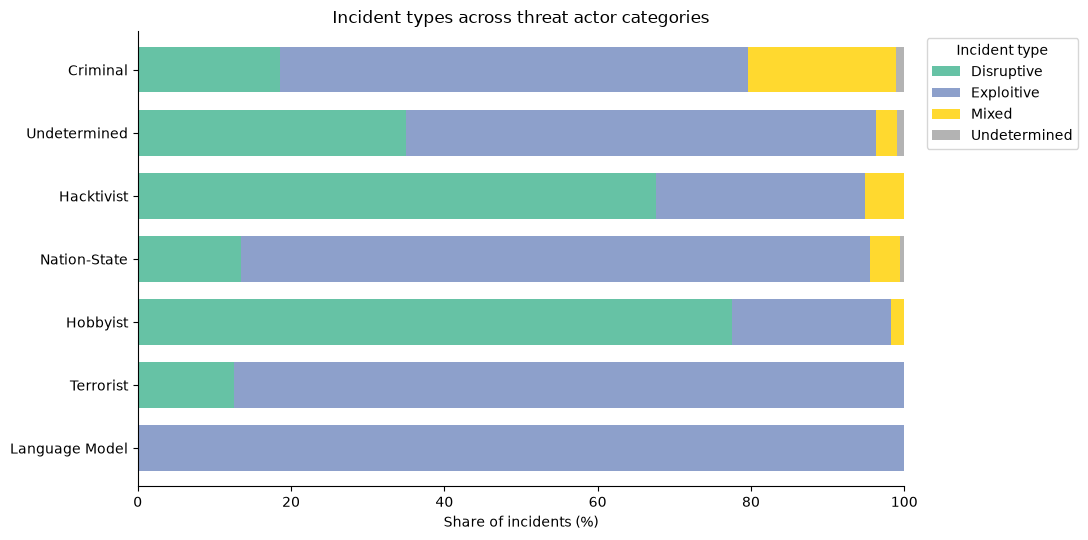

In [114]:

# Compare incident types across threat actor categories
actor_event_data = usa_final[
    ["actor_type", "event_type"]
].copy()

actor_event_data["actor_type"] = (
    actor_event_data["actor_type"].fillna("Undetermined")
)

actor_event_data["event_type"] = (
    actor_event_data["event_type"]
    .fillna("Undetermined")
    .astype(str)
    .str.split(",")
)

# Split the weight of incidents with multiple event types
actor_event_data["weight"] = (
    1 / actor_event_data["event_type"].str.len()
)

actor_event_data = actor_event_data.explode("event_type")
actor_event_data["event_type"] = (
    actor_event_data["event_type"].str.strip()
)

actor_event_counts = (
    actor_event_data
    .pivot_table(
        index="actor_type",
        columns="event_type",
        values="weight",
        aggfunc="sum",
        fill_value=0
    )
)

actor_event_shares = (
    actor_event_counts
    .div(actor_event_counts.sum(axis=1), axis=0)
    .mul(100)
    .reindex(actor_order)
)

fig, ax = plt.subplots(figsize=(11, 5.5))

actor_event_shares.iloc[::-1].plot(
    kind="barh",
    stacked=True,
    width=0.72,
    colormap="Set2",
    ax=ax
)

ax.set_xlim(0, 100)
ax.set_xlabel("Share of incidents (%)")
ax.set_ylabel("")
ax.set_title("Incident types across threat actor categories")
ax.legend(
    title="Incident type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## 9. Figure Export

This section exports all figures created in the notebook. Static Matplotlib and Seaborn figures are saved as high-resolution PNG files. Interactive Plotly figures are exported as standalone HTML files and, when possible, also as PNG files.

In [115]:
def save_mpl_figure(fig_obj, filename):
    output_path = STATIC_DIR / f"{filename}.png"
    fig_obj.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        facecolor="white"
    )
    print(f"Saved PNG: {output_path}")


def save_plotly_figure(fig_obj, filename, export_png=True):
    html_path = INTERACTIVE_DIR / f"{filename}.html"
    fig_obj.write_html(
        html_path,
        include_plotlyjs=True,
        full_html=True
    )
    print(f"Saved HTML: {html_path}")

    if export_png:
        png_path = STATIC_DIR / f"{filename}.png"
        try:
            fig_obj.write_image(png_path, scale=2)
            print(f"Saved PNG: {png_path}")
        except Exception as exc:
            print(
                f"PNG export skipped for {filename} "
                f"(install kaleido if needed): {exc}"
            )


print(f"Static figures directory: {STATIC_DIR}")
print(f"Interactive figures directory: {INTERACTIVE_DIR}")

Static figures directory: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static
Interactive figures directory: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive


In [116]:
# Export named Matplotlib figures created in earlier sections
named_mpl_figures = [
    ("01_01_missing_data", fig_usa_missing_values),
    ("01_02_data_quality_overview", fig_usa_data_quality),
    ("02_01_duplicate_criteria", fig_usa_duplicate_criteria),
    ("03_01_annual_incidents", fig_usa_annual_incidents),
    ("03_02_monthly_incidents_heatmap", fig_usa_monthly_heatmap),
    ("03_03_monthly_incident_shares_heatmap", fig_usa_monthly_shares),
    ("03_04_sector_distribution_2022_2024", fig_usa_sector_heatmap),
    ("03_05_sector_counts_heatmap", fig_usa_sector_counts_heatmap),
    ("03_06_sector_shares_heatmap", fig_usa_sector_shares_heatmap),
    ("04_01_state_counts_heatmap", fig_usa_state_counts_heatmap),
    ("04_02_state_shares_heatmap", fig_usa_state_shares_heatmap),
    ("04_03_top3_states_by_year", fig_usa_top3_states),
    ("04_04_top3_location_categories_by_year", fig_usa_top3_all_locations),
    ("05_01_incident_subtype_distribution", fig_usa_subtype_distribution),
    ("05_02_type_subtype_heatmap", fig_usa_type_subtype_heatmap),
    ("05_03_annual_incident_type_shares", fig_usa_type_annual_shares),
    ("06_01_ransomware_trends", fig_usa_ransomware_trends),
    ("06_02_sector_type_composition", fig_usa_sector_type_composition),
    ("06_03_sector_subtype_heatmap", fig_usa_sector_subtype_heatmap),
]

for filename, fig_obj in named_mpl_figures:
    save_mpl_figure(fig_obj, filename)

Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\01_01_missing_data.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\01_02_data_quality_overview.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\02_01_duplicate_criteria.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\03_01_annual_incidents.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\03_02_monthly_incidents_heatmap.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\03_03_monthly_incident_shares_heatmap.png
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\03_04_sector_distrib

In [117]:
# Export named Plotly figures created in earlier sections
named_plotly_figures = [
    ("04_05_state_annual_map", fig_usa_state_annual_map),
    ("05_04_type_subtype_sankey", fig_usa_type_subtype_sankey),
    ("05_05_incident_subtype_trends", fig_usa_subtype_trends),
    ("06_04_ransomware_counts_map", fig_usa_ransomware_counts_map),
    ("06_05_ransomware_shares_map", fig_usa_ransomware_shares_map),
]

for filename, fig_obj in named_plotly_figures:
    save_plotly_figure(fig_obj, filename)

Saved HTML: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive\04_05_state_annual_map.html
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\04_05_state_annual_map.png
Saved HTML: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive\05_04_type_subtype_sankey.html
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\05_04_type_subtype_sankey.png
Saved HTML: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive\05_05_incident_subtype_trends.html
Saved PNG: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\static\05_05_incident_subtype_trends.png
Saved HTML: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\figures\umd_usa\interactive\